# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

## Import external libs and internal models

In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions
from src.evaluation.training import all_valid_splits_seq_fit_predict, test_set_seq_fit_predict

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
from river.tree import HoeffdingTreeRegressor, HoeffdingAdaptiveTreeRegressor
from src.evaluation.baseline import PreviousValueRegressor
from src.trees import fastodt
from src.bagging import ARFRegressorFODT
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../../data/second_batch/industrial'

## Evaluation Settings

In [4]:
DATA_FREQUENCY = 'H'  # 1-Hour frequency
FORECAST_HORIZON = '1h'  # 1-Hour forecast horizon
SPIKE_PROMINENCE = 3.5  # For industrial data

In [5]:
# Measure loading time
start_time = time.time()

# Load data
train, valid, test = load_dataset(data_dir=data_dir, prefix='sb_ind_hour_wfv', use_numpy=True)
FEATURES = ['time', 'device_id', 'hour', 'weekday', 'month', 
           'consumption_lag_1h', 'consumption_lag_2h', 'consumption_lag_24h', 'consumption_lag_25h']

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 25 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 25 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.04 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 25 splits
Validation data: 25 splits
First train split shape: X=(1344, 9), y=(1344,)
First valid split shape: X=(1344, 9), y=(1344,)

Memory usage:
Train: 40.53 MB
Valid: 4.22 MB
Test: 1.08 MB
Total: 45.84 MB


# WFV Models Evaluation
(train+valid WFV)
- (1) `train[0]` vs `valid[0]`
- (2) `train[1]` vs `valid[1]`
- ...
- (n) `train[n]` vs `valid[n]`

, where: 
$$ train[1] = train[0]+valid[0] $$
$$...$$
$$ train[n] = train[0]+valid[0]+valid[1]+...+valid[n-1] $$

## Hourly granularity

### Baseline model (predict previous value)

In [47]:
update_freq = "1H"
baseline = PreviousValueRegressor
baseline_params = {}

In [48]:
baseline_train_period_predictions, baseline_valid_period_predictions,\
baseline_train_period_metrics, baseline_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=baseline,
    model_params=baseline_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0783
	MAE: 0.0527
	MAPE: 19.0481%

Directional Metrics:
	Directional Accuracy: 49.7765%
	First-Diff Correlation: -0.0117

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9583
		Recall: 1.0000
		F1: 0.9787
	Drops:
		Precision: 0.9565
		Recall: 1.0000
		F1: 0.9778
--------------------------------------------------
Da

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0604
	MAE: 0.0385
	MAPE: 18.1361%

Directional Metrics:
	Directional Accuracy: 41.7288%
	First-Diff Correlation: -0.2240

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Da

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

[! WARNING !] No validation data for device site1 in split 23. Skipping.
[! WARNING !] No validation data for device site3 in split 23. Skipping.
Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 0.000053 MB
Metrics for Device: site8 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 4.9477
	MAE: 2.2175
	MAPE: 27.8156%

Directional Metrics:
	Directional Accuracy: 44.4113%
	First-Diff Correlation: 0.2214

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

[! WARNING !] No validation data for device site1 in split 24. Skipping.
[! WARNING !] No validation data for device site3 in split 24. Skipping.
Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 0.000053 MB
Metrics for Device: site8 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 5.7934
	MAE: 2.8517
	MAPE: 32.0041%

Directional Metrics:
	Directional Accuracy: 44.8640%
	First-Diff Correlation: 0.2483

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0

#### Results

In [49]:
print("\n\nValid period metrics:")
baseline_all_time_valid_metrics = all_time_aggregation_metrics(baseline_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0721 ± 0.0085
	MAE: 0.0470 ± 0.0072
	MAPE: 17.6682% ± 2.2495%

	Directional Metrics:
		Directional Accuracy: 44.6712% ± 3.5092%
		First-Diff Correlation: -0.0971 ± 0.0960

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9829 ± 0.0479
		Spike Recall: 0.9972 ± 0.0093
		Spike F1: 0.9893 ± 0.0262
		Drop Precision: 0.9978 ± 0.0095
		Drop Recall: 0.9971 ± 0.0096
		Drop F1: 0.9974 ± 0.0066
Daily Metrics:
	RMSE: 0.0722 ± 0.0497
	MAE: 0.0505 ± 0.0388
	MAPE: 0.7561% ± 0.2958%

	Directional Metrics:
		Directional Accuracy: 98.0357% ± 3.2878%
		First-Diff Correlation: 0.9981 ± 0.0017

	Immediate Detection (delta=0):
		Spi

#### Validation plots

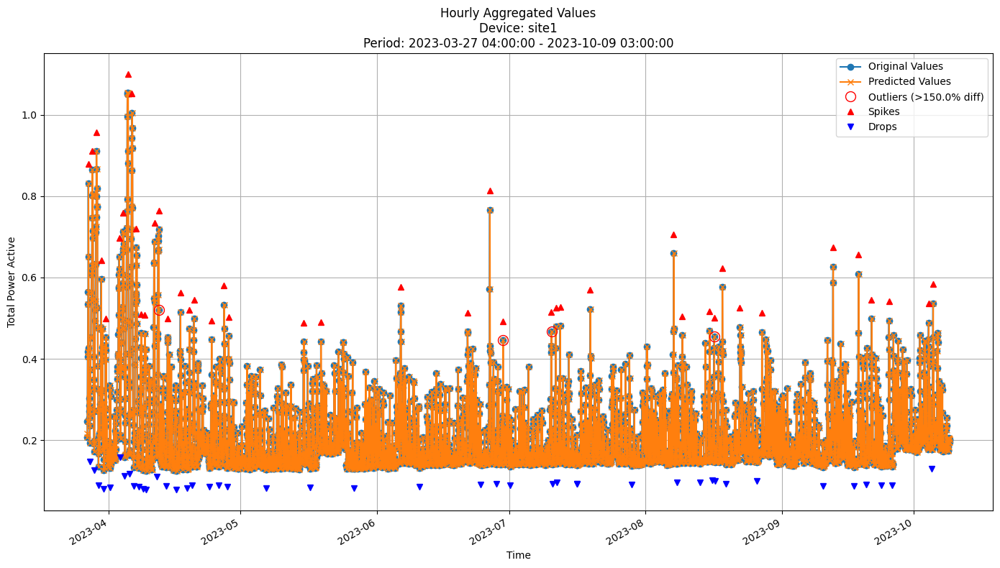


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0664
MAE: 0.0420
MAPE: 18.3269%

Directional Metrics:
Directional Accuracy: 44.0145%
First-Diff Correlation: -0.1712

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


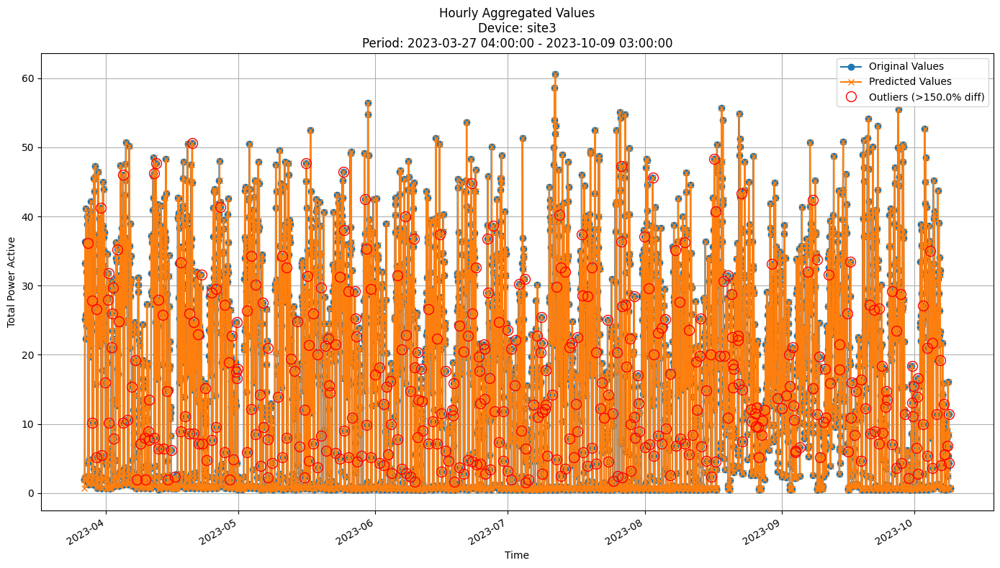


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 9.6082
MAE: 6.3234
MAPE: 76.9891%

Directional Metrics:
Directional Accuracy: 39.6768%
First-Diff Correlation: -0.1385

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


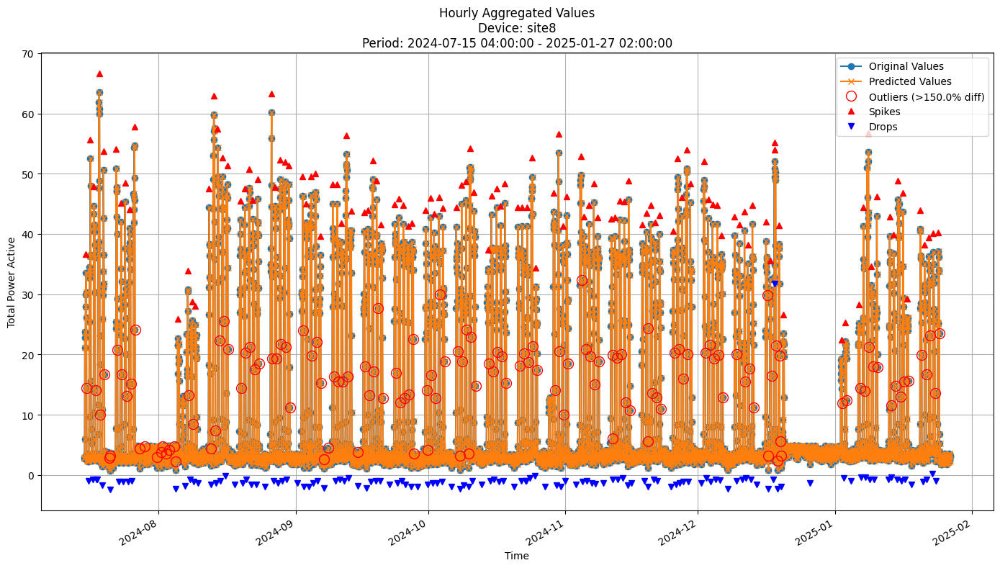


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 5.6246
MAE: 2.6651
MAPE: 32.6096%

Directional Metrics:
Directional Accuracy: 46.8212%
First-Diff Correlation: 0.2795

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


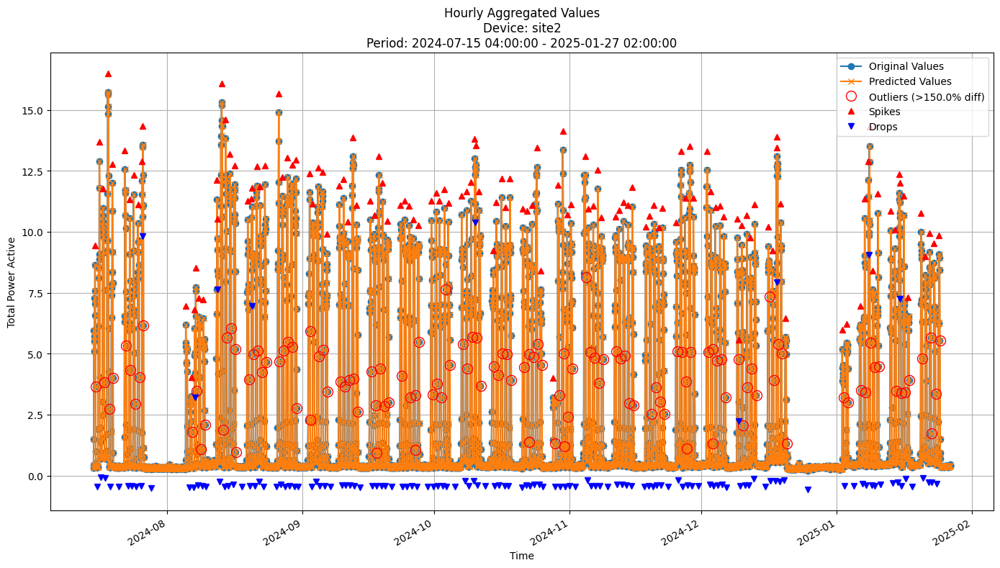


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.4050
MAE: 0.5976
MAPE: 26.9640%

Directional Metrics:
Directional Accuracy: 48.4159%
First-Diff Correlation: 0.2994

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


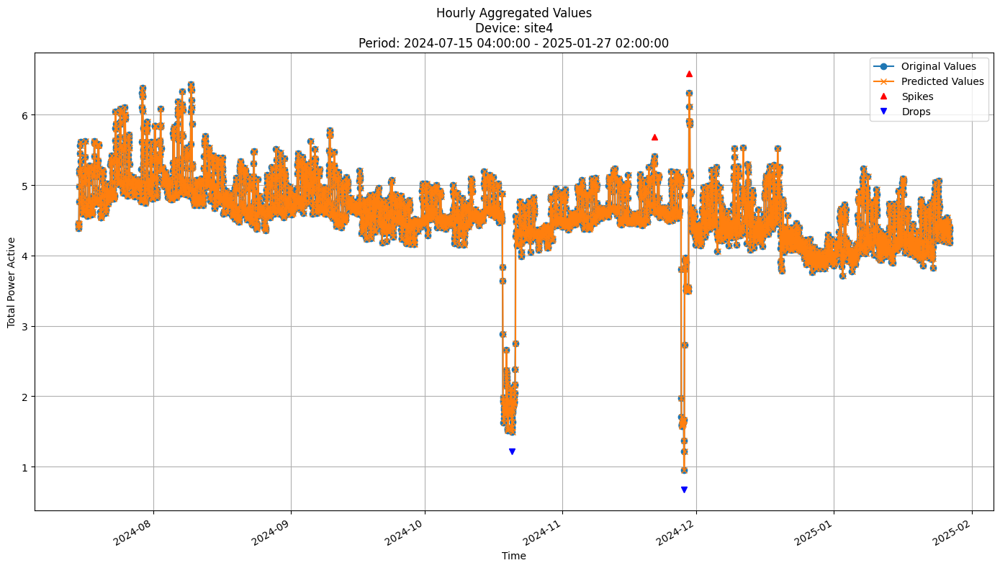


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1504
MAE: 0.0934
MAPE: 2.0943%

Directional Metrics:
Directional Accuracy: 44.4822%
First-Diff Correlation: 0.0188

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


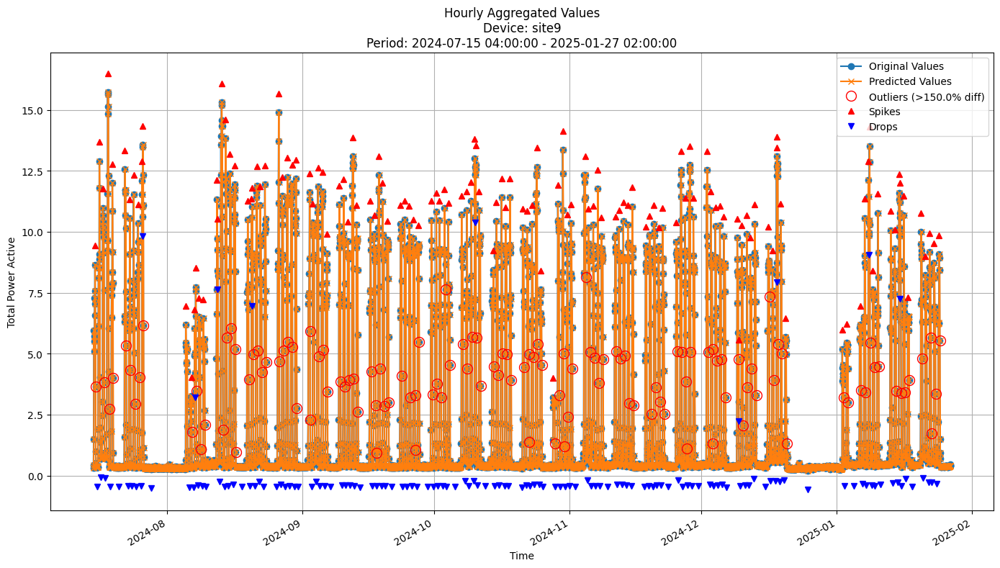


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.4050
MAE: 0.5976
MAPE: 26.9640%

Directional Metrics:
Directional Accuracy: 48.4159%
First-Diff Correlation: 0.2994

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


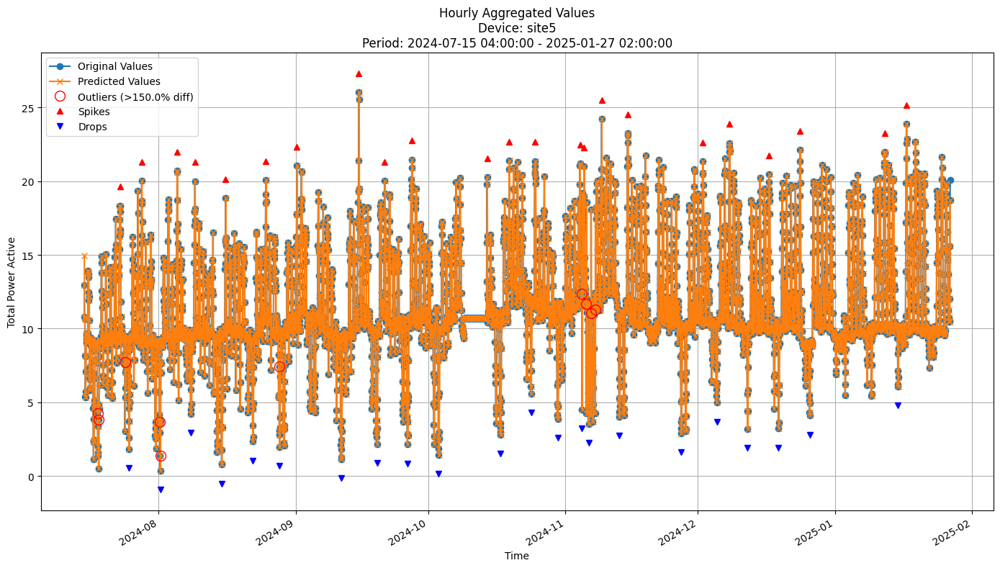


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.4863
MAE: 0.9250
MAPE: 9.0837%

Directional Metrics:
Directional Accuracy: 59.4089%
First-Diff Correlation: 0.1370

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


In [50]:
join_periods = range(len(baseline_valid_period_predictions))
# Device iteration
for device_id in baseline_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, baseline_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, baseline_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [41]:
update_freq = "14D"  # Update the model every 14 days
gbdt = GradientBoostingRegressor
gbdt_params = {
    'n_estimators': 100,
    'learning_rate': 0.03,
    'subsample': 0.8,
    'max_depth': 10,
    'random_state': 42
}

In [42]:
gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=gbdt,
    model_params=gbdt_params,
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]


Retraining model on data from 2023-02-27 03:00:00+01:00 to 2023-03-27 03:00:00+02:00

Time: 0.24 seconds
Predicting for chunk from 2023-03-27 04:00:00+02:00 to 2023-04-10 04:00:00+02:00

-------------------------

Retraining model on data from 2023-02-27 03:00:00+01:00 to 2023-04-10 04:00:00+02:00

Time: 0.32 seconds
Predicting for chunk from 2023-04-10 05:00:00+02:00 to 2023-04-24 03:00:00+02:00

-------------------------
Model's memory usage: 0.000053 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0767
	MAE: 0.0592
	MAPE: 25.5255%

Directional Metrics:
	Directional Accuracy: 59.1654%
	First-Diff Correlation: 0.4374

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2273
		Recall: 0.2174
		F1: 0.2222
	Drops:
		Precision: 0.0952
		Recall: 0.0909
		F1: 0.0930

Delayed Detection (delta=

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]


Retraining model on data from 2023-02-27 03:00:00+01:00 to 2023-04-24 03:00:00+02:00

Time: 0.41 seconds
Predicting for chunk from 2023-04-24 04:00:00+02:00 to 2023-05-08 04:00:00+02:00

-------------------------

Retraining model on data from 2023-02-27 03:00:00+01:00 to 2023-05-08 04:00:00+02:00

Time: 0.48 seconds
Predicting for chunk from 2023-05-08 05:00:00+02:00 to 2023-05-22 03:00:00+02:00

-------------------------
Model's memory usage: 0.000053 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0482
	MAE: 0.0357
	MAPE: 19.2195%

Directional Metrics:
	Directional Accuracy: 59.9106%
	First-Diff Correlation: 0.4100

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1667
		Recall: 0.1163
		F1: 0.1370
	Drops:
		Precision: 0.1034
		Recall: 0.0652
		F1: 0.0800

Delayed Detection (delta=

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

[! WARNING !] No validation data for device site1 in split 23. Skipping.
[! WARNING !] No validation data for device site3 in split 23. Skipping.

Retraining model on data from 2024-06-29 12:00:00+02:00 to 2024-12-30 02:00:00+01:00

Time: 1.34 seconds
Predicting for chunk from 2024-12-30 03:00:00+01:00 to 2025-01-13 03:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 12:00:00+02:00 to 2025-01-13 03:00:00+01:00

Time: 1.42 seconds
Predicting for chunk from 2025-01-13 04:00:00+01:00 to 2025-01-27 02:00:00+01:00

-------------------------
Model's memory usage: 0.000053 MB
Metrics for Device: site8 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 3.8101
	MAE: 2.0236
	MAPE: 24.9363%

Directional Metrics:
	Directional Accuracy: 54.0984%
	First-Diff Correlation: 0.6514

Immediate Detection (delta=0

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

[! WARNING !] No validation data for device site1 in split 24. Skipping.
[! WARNING !] No validation data for device site3 in split 24. Skipping.

Retraining model on data from 2024-06-29 12:00:00+02:00 to 2025-01-27 02:00:00+01:00

Time: 1.53 seconds
Predicting for chunk from 2025-01-27 03:00:00+01:00 to 2025-02-10 03:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 12:00:00+02:00 to 2025-02-10 03:00:00+01:00

Time: 1.64 seconds
Predicting for chunk from 2025-02-10 04:00:00+01:00 to 2025-02-23 17:00:00+01:00

-------------------------
Model's memory usage: 0.000053 MB
Metrics for Device: site8 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 4.1203
	MAE: 2.1368
	MAPE: 23.2527%

Directional Metrics:
	Directional Accuracy: 58.3082%
	First-Diff Correlation: 0.6447

Immediate Detection (delta=0

#### Results

In [43]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0262 ± 0.0063
	MAE: 0.0199 ± 0.0045
	MAPE: 8.3739% ± 1.6319%

	Directional Metrics:
		Directional Accuracy: 80.5304% ± 5.5907%
		First-Diff Correlation: 0.9282 ± 0.0372

	Immediate Detection (delta=0):
		Spike Precision: 0.7817 ± 0.0751
		Spike Recall: 0.6917 ± 0.1172
		Spike F1: 0.7325 ± 0.0971
		Drop Precision: 0.4013 ± 0.1432
		Drop Recall: 0.3453 ± 0.1449
		Drop F1: 0.3705 ± 0.1445

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8553 ± 0.0558
		Spike Recall: 0.7550 ± 0.1043
		Spike F1: 0.8004 ± 0.0805
		Drop Precision: 0.5398 ± 0.1128
		Drop Recall: 0.4613 ± 0.1271
		Drop F1: 0.4965 ± 0.1206
Daily Metrics:
	RMSE: 0.2658 ± 0.0500
	MAE: 0.2146 ± 0.0407
	MAPE: 3.4260% ± 0.5335%

	Directional Metrics:
		Directional Accuracy: 94.3681% ± 2.4343%
		First-Diff Correlation: 0.9935 ± 0.0029

	Immediate Detection (delta=0):
		Spike

#### Training plots

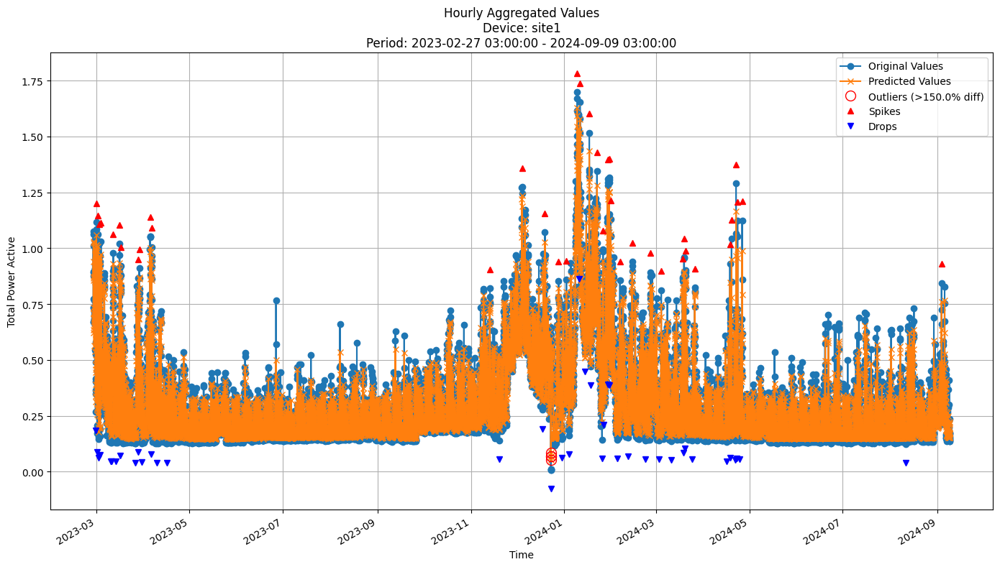


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0360
MAE: 0.0263
MAPE: 10.7511%

Directional Metrics:
Directional Accuracy: 73.8969%
First-Diff Correlation: 0.8615

Immediate Detection (delta=0):
Spikes:
  Precision: 0.7105
  Recall: 0.7105
  F1 Score: 0.7105
Drops:
  Precision: 0.3947
  Recall: 0.3750
  F1 Score: 0.3846

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8421
  Recall: 0.8421
  F1 Score: 0.8421
Drops:
  Precision: 0.5789
  Recall: 0.5500
  F1 Score: 0.5641


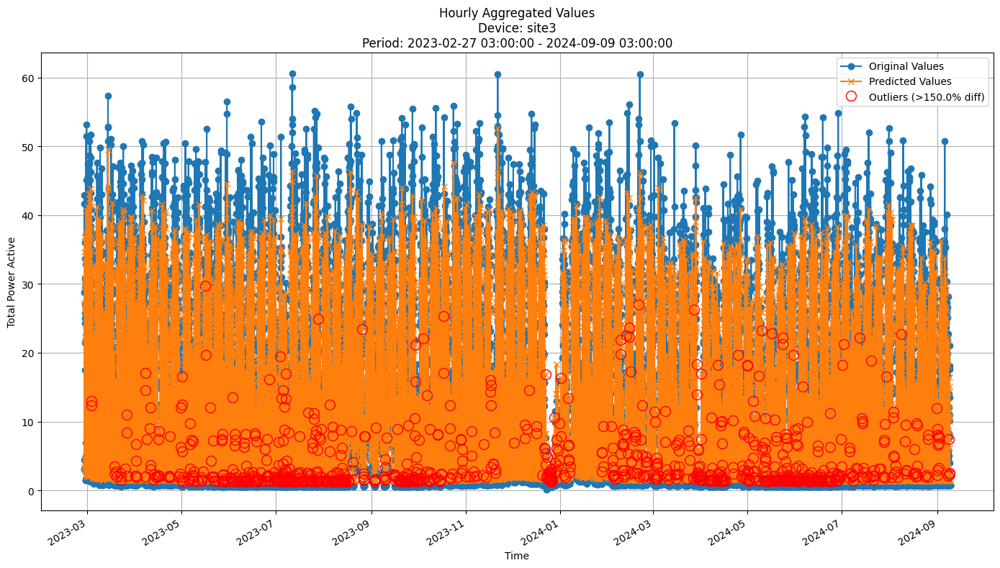


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 4.3483
MAE: 2.9361
MAPE: 56.0279%

Directional Metrics:
Directional Accuracy: 71.0097%
First-Diff Correlation: 0.8332

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


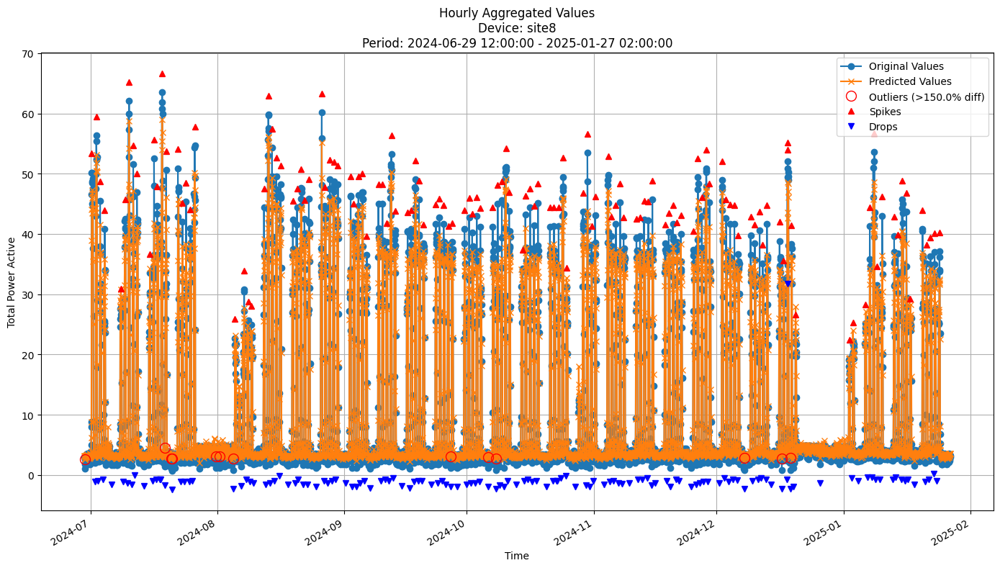


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5081
MAE: 0.9268
MAPE: 16.4643%

Directional Metrics:
Directional Accuracy: 83.0282%
First-Diff Correlation: 0.9657

Immediate Detection (delta=0):
Spikes:
  Precision: 0.5620
  Recall: 0.5704
  F1 Score: 0.5662
Drops:
  Precision: 0.4265
  Recall: 0.4265
  F1 Score: 0.4265

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7080
  Recall: 0.7185
  F1 Score: 0.7132
Drops:
  Precision: 0.4853
  Recall: 0.4853
  F1 Score: 0.4853


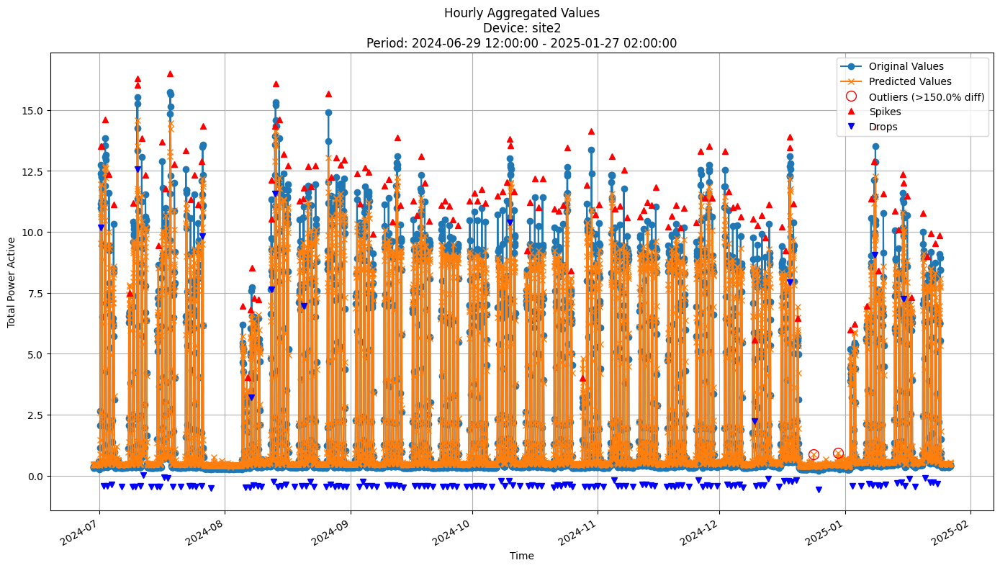


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4187
MAE: 0.2354
MAPE: 21.7263%

Directional Metrics:
Directional Accuracy: 78.8147%
First-Diff Correlation: 0.9568

Immediate Detection (delta=0):
Spikes:
  Precision: 0.4897
  Recall: 0.4797
  F1 Score: 0.4846
Drops:
  Precision: 0.2778
  Recall: 0.2703
  F1 Score: 0.2740

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6138
  Recall: 0.6014
  F1 Score: 0.6075
Drops:
  Precision: 0.3819
  Recall: 0.3716
  F1 Score: 0.3767


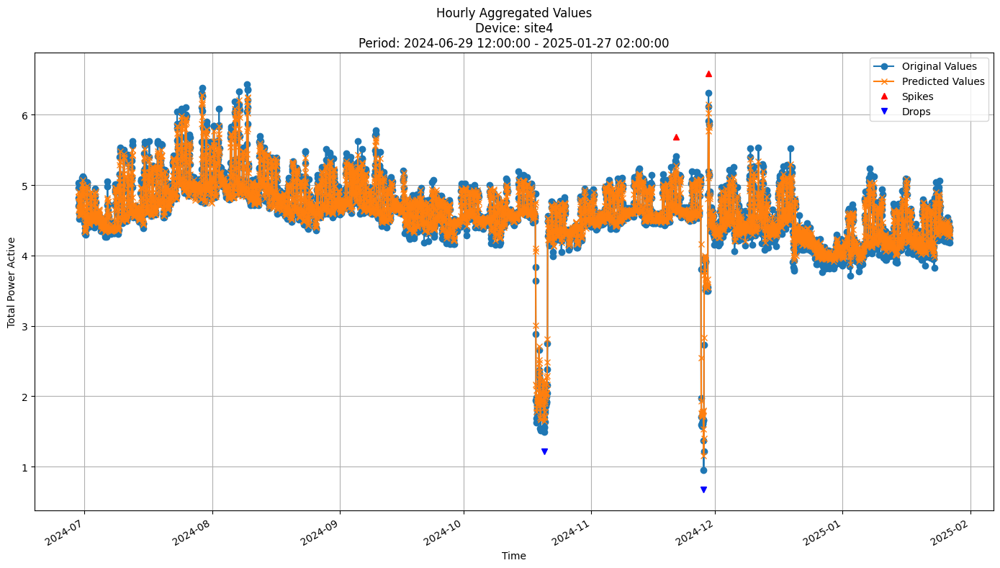


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0752
MAE: 0.0571
MAPE: 1.3102%

Directional Metrics:
Directional Accuracy: 72.4355%
First-Diff Correlation: 0.8552

Immediate Detection (delta=0):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


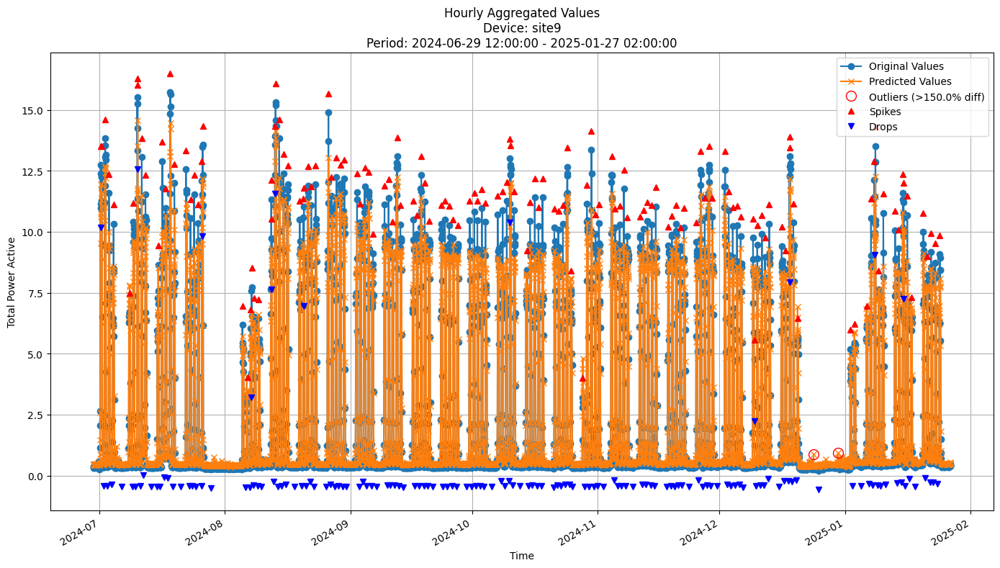


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4187
MAE: 0.2354
MAPE: 21.7263%

Directional Metrics:
Directional Accuracy: 78.8147%
First-Diff Correlation: 0.9568

Immediate Detection (delta=0):
Spikes:
  Precision: 0.4897
  Recall: 0.4797
  F1 Score: 0.4846
Drops:
  Precision: 0.2778
  Recall: 0.2703
  F1 Score: 0.2740

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6138
  Recall: 0.6014
  F1 Score: 0.6075
Drops:
  Precision: 0.3819
  Recall: 0.3716
  F1 Score: 0.3767


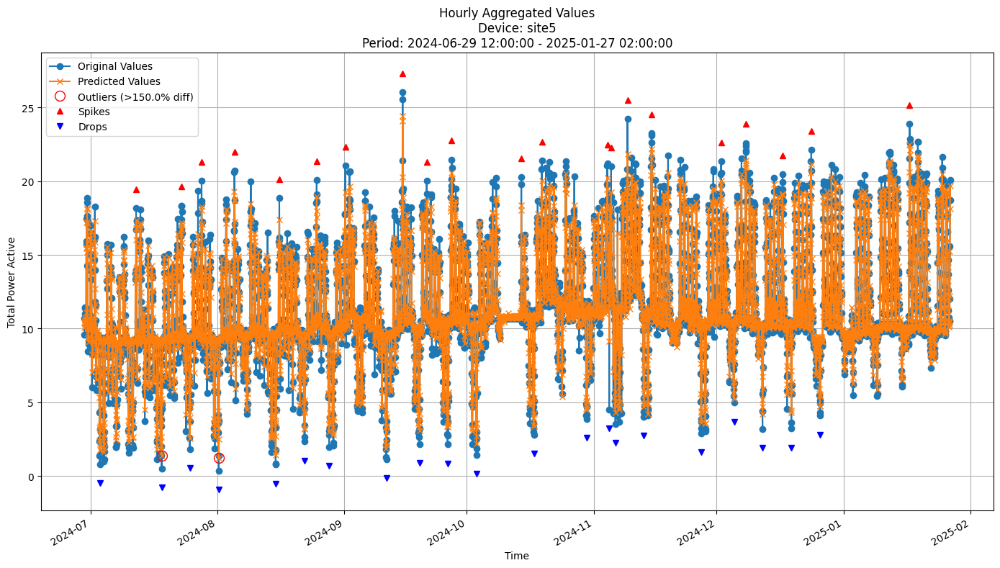


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.5245
MAE: 0.3814
MAPE: 4.1643%

Directional Metrics:
Directional Accuracy: 77.2790%
First-Diff Correlation: 0.9342

Immediate Detection (delta=0):
Spikes:
  Precision: 0.4737
  Recall: 0.4286
  F1 Score: 0.4500
Drops:
  Precision: 0.6316
  Recall: 0.5714
  F1 Score: 0.6000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6316
  Recall: 0.5714
  F1 Score: 0.6000
Drops:
  Precision: 0.6842
  Recall: 0.6190
  F1 Score: 0.6500


In [44]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last few periods of predictions

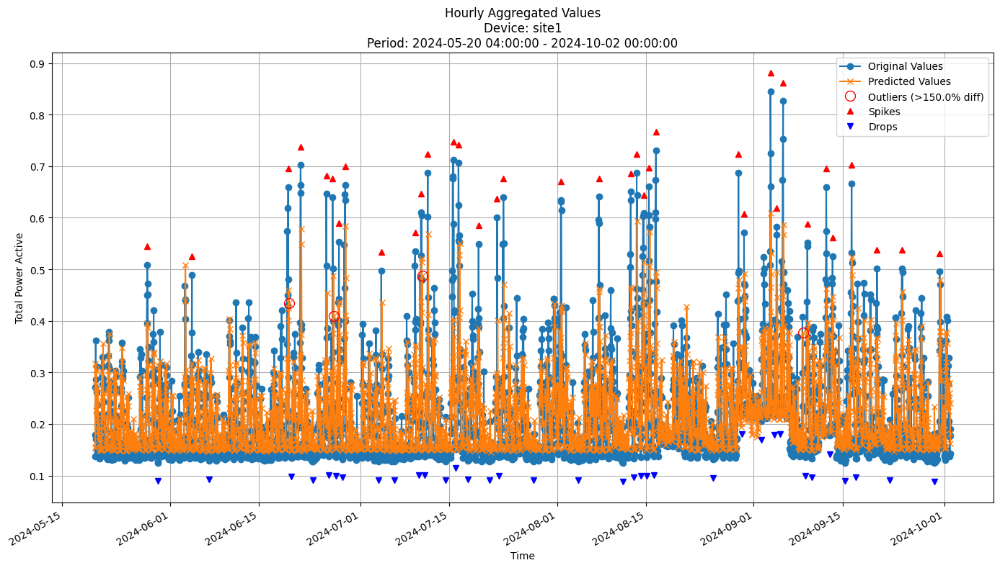


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0696
MAE: 0.0421
MAPE: 17.7989%

Directional Metrics:
Directional Accuracy: 58.5290%
First-Diff Correlation: 0.3563

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.3333
  Recall: 0.0857
  F1 Score: 0.1364

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3000
  Recall: 0.0833
  F1 Score: 0.1304
Drops:
  Precision: 0.3333
  Recall: 0.0857
  F1 Score: 0.1364


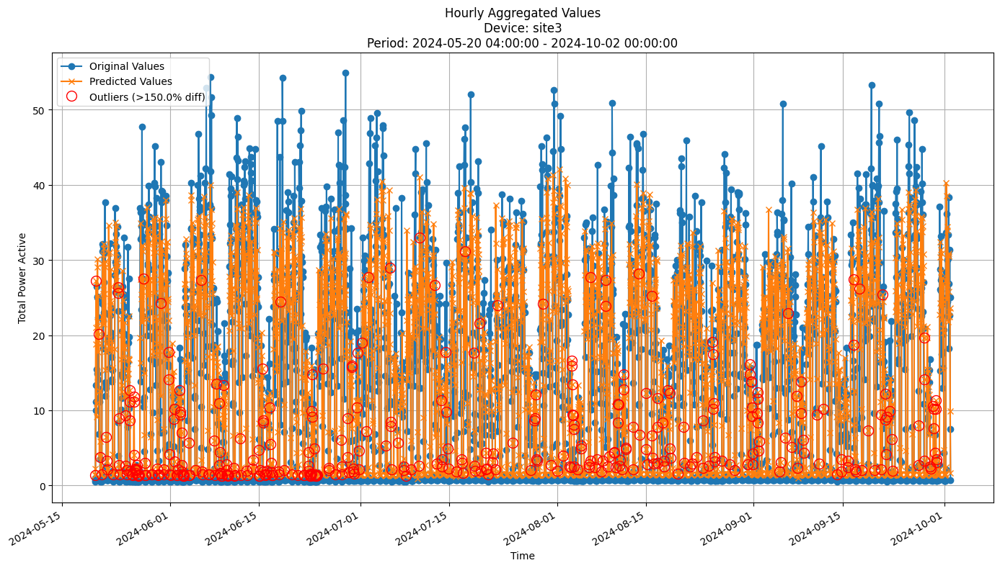


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 6.4896
MAE: 4.4638
MAPE: 81.1713%

Directional Metrics:
Directional Accuracy: 56.4277%
First-Diff Correlation: 0.5382

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


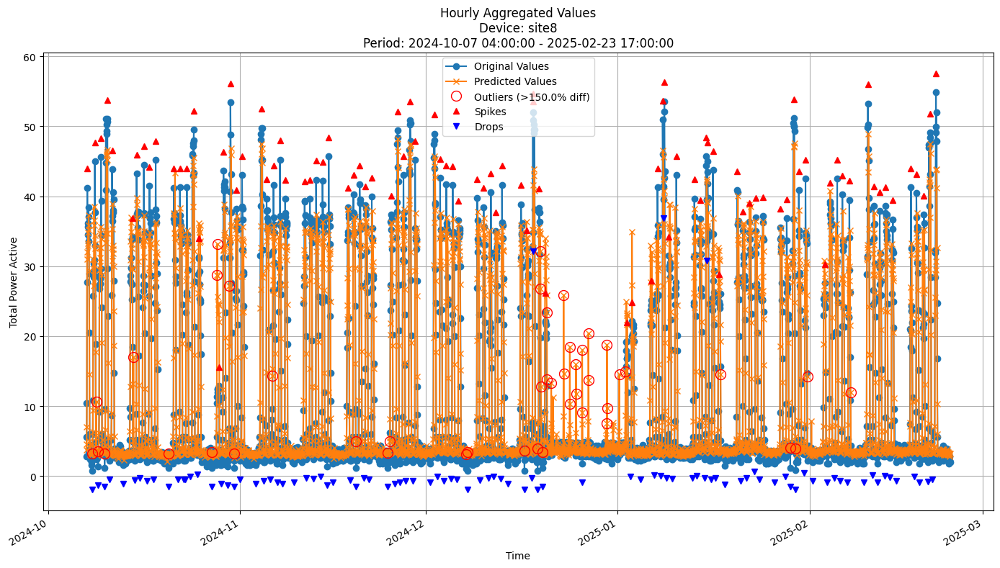


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 3.8741
MAE: 2.0519
MAPE: 26.1000%

Directional Metrics:
Directional Accuracy: 58.4776%
First-Diff Correlation: 0.6903

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0763
  Recall: 0.0947
  F1 Score: 0.0845
Drops:
  Precision: 0.0427
  Recall: 0.0526
  F1 Score: 0.0472

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2203
  Recall: 0.2737
  F1 Score: 0.2441
Drops:
  Precision: 0.1453
  Recall: 0.1789
  F1 Score: 0.1604


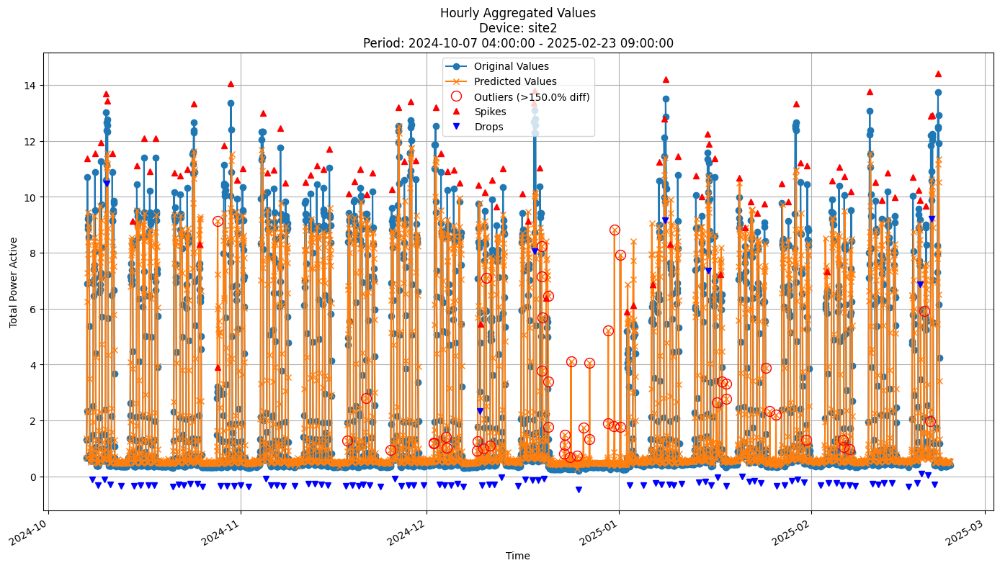


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.9586
MAE: 0.4827
MAPE: 33.4351%

Directional Metrics:
Directional Accuracy: 62.6272%
First-Diff Correlation: 0.7059

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0833
  Recall: 0.1010
  F1 Score: 0.0913
Drops:
  Precision: 0.0756
  Recall: 0.0918
  F1 Score: 0.0829

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2750
  Recall: 0.3333
  F1 Score: 0.3014
Drops:
  Precision: 0.1765
  Recall: 0.2143
  F1 Score: 0.1935


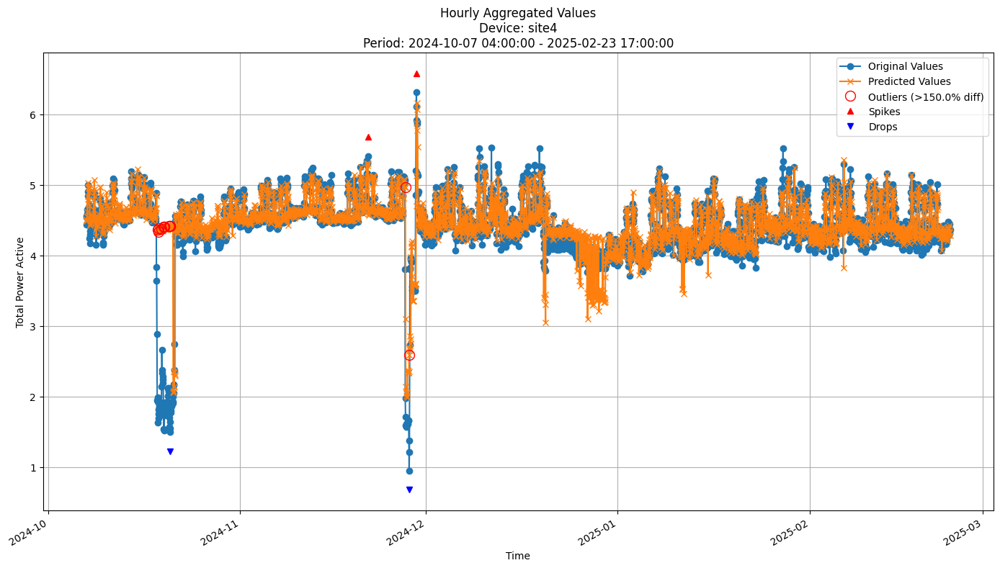


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4055
MAE: 0.1804
MAPE: 5.7601%

Directional Metrics:
Directional Accuracy: 52.9254%
First-Diff Correlation: 0.0873

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2500
  Recall: 0.5000
  F1 Score: 0.3333
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2500
  Recall: 0.5000
  F1 Score: 0.3333
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


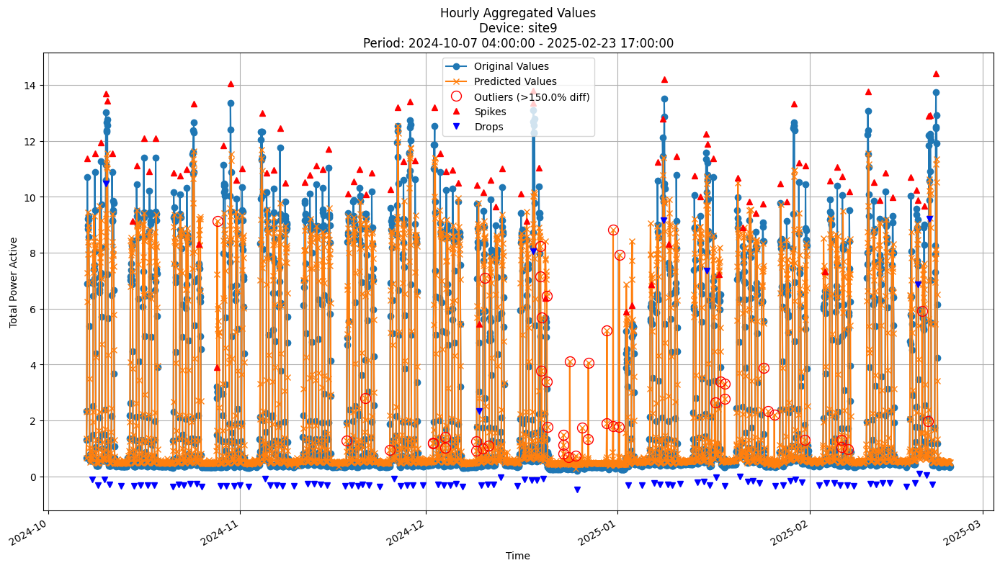


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.9575
MAE: 0.4819
MAPE: 33.4398%

Directional Metrics:
Directional Accuracy: 62.5672%
First-Diff Correlation: 0.7059

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0833
  Recall: 0.1010
  F1 Score: 0.0913
Drops:
  Precision: 0.0756
  Recall: 0.0918
  F1 Score: 0.0829

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2750
  Recall: 0.3333
  F1 Score: 0.3014
Drops:
  Precision: 0.1765
  Recall: 0.2143
  F1 Score: 0.1935


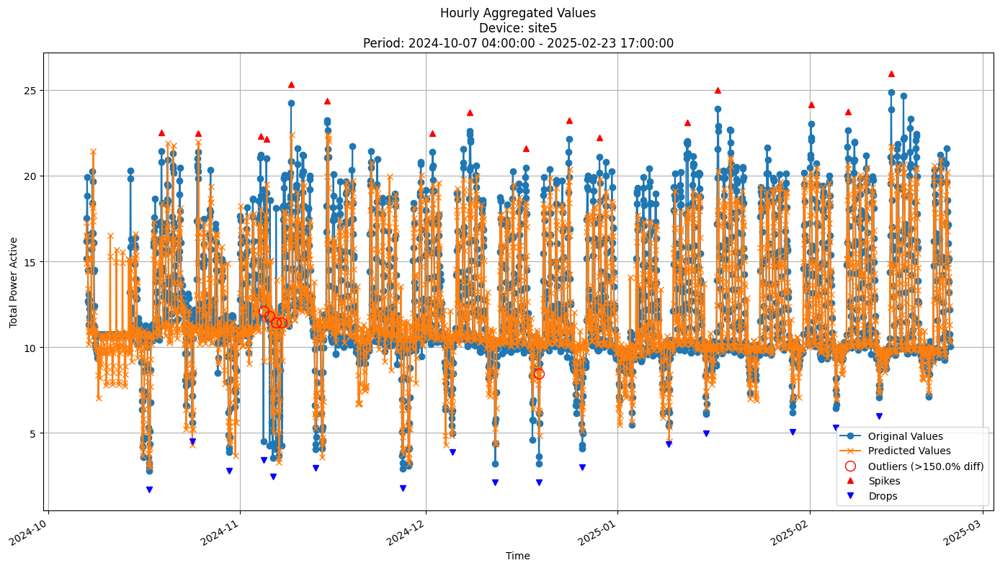


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.6177
MAE: 1.0761
MAPE: 8.7371%

Directional Metrics:
Directional Accuracy: 61.1045%
First-Diff Correlation: 0.3695

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0833
  Recall: 0.0625
  F1 Score: 0.0714

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.3333
  Recall: 0.2500
  F1 Score: 0.2857


In [45]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Random Forest model

In [33]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor
rf_params = {
    'n_estimators': 100,
    'max_depth': 10,
    'max_features': 'sqrt',
    'random_state': 42,
    'n_jobs': -1
}

In [34]:
rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=rf, 
    model_params=rf_params,
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]


Retraining model on data from 2023-02-27 03:00:00+01:00 to 2023-03-27 03:00:00+02:00

Time: 0.12 seconds
Predicting for chunk from 2023-03-27 04:00:00+02:00 to 2023-04-10 04:00:00+02:00

-------------------------

Retraining model on data from 2023-02-27 03:00:00+01:00 to 2023-04-10 04:00:00+02:00

Time: 0.12 seconds
Predicting for chunk from 2023-04-10 05:00:00+02:00 to 2023-04-24 03:00:00+02:00

-------------------------
Model's memory usage: 0.000053 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0820
	MAE: 0.0631
	MAPE: 25.7102%

Directional Metrics:
	Directional Accuracy: 57.0790%
	First-Diff Correlation: 0.3683

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1818
		Recall: 0.1739
		F1: 0.1778
	Drops:
		Precision: 0.1429
		Recall: 0.1364
		F1: 0.1395

Delayed Detection (delta=

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]


Retraining model on data from 2023-02-27 03:00:00+01:00 to 2023-04-24 03:00:00+02:00

Time: 0.11 seconds
Predicting for chunk from 2023-04-24 04:00:00+02:00 to 2023-05-08 04:00:00+02:00

-------------------------

Retraining model on data from 2023-02-27 03:00:00+01:00 to 2023-05-08 04:00:00+02:00

Time: 0.11 seconds
Predicting for chunk from 2023-05-08 05:00:00+02:00 to 2023-05-22 03:00:00+02:00

-------------------------
Model's memory usage: 0.000053 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0487
	MAE: 0.0362
	MAPE: 18.8775%

Directional Metrics:
	Directional Accuracy: 54.9925%
	First-Diff Correlation: 0.2439

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1250
		Recall: 0.0698
		F1: 0.0896
	Drops:
		Precision: 0.0435
		Recall: 0.0217
		F1: 0.0290

Delayed Detection (delta=

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

[! WARNING !] No validation data for device site1 in split 23. Skipping.
[! WARNING !] No validation data for device site3 in split 23. Skipping.

Retraining model on data from 2024-06-29 12:00:00+02:00 to 2024-12-30 02:00:00+01:00

Time: 0.12 seconds
Predicting for chunk from 2024-12-30 03:00:00+01:00 to 2025-01-13 03:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 12:00:00+02:00 to 2025-01-13 03:00:00+01:00

Time: 0.12 seconds
Predicting for chunk from 2025-01-13 04:00:00+01:00 to 2025-01-27 02:00:00+01:00

-------------------------
Model's memory usage: 0.000053 MB
Metrics for Device: site8 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 3.8291
	MAE: 2.0896
	MAPE: 24.6198%

Directional Metrics:
	Directional Accuracy: 54.9925%
	First-Diff Correlation: 0.6808

Immediate Detection (delta=0

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

[! WARNING !] No validation data for device site1 in split 24. Skipping.
[! WARNING !] No validation data for device site3 in split 24. Skipping.

Retraining model on data from 2024-06-29 12:00:00+02:00 to 2025-01-27 02:00:00+01:00

Time: 0.12 seconds
Predicting for chunk from 2025-01-27 03:00:00+01:00 to 2025-02-10 03:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 12:00:00+02:00 to 2025-02-10 03:00:00+01:00

Time: 0.13 seconds
Predicting for chunk from 2025-02-10 04:00:00+01:00 to 2025-02-23 17:00:00+01:00

-------------------------
Model's memory usage: 0.000053 MB
Metrics for Device: site8 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 4.1423
	MAE: 2.1720
	MAPE: 22.2050%

Directional Metrics:
	Directional Accuracy: 58.7613%
	First-Diff Correlation: 0.6710

Immediate Detection (delta=0

#### Results

In [35]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0472 ± 0.0061
	MAE: 0.0339 ± 0.0042
	MAPE: 13.7720% ± 1.2562%

	Directional Metrics:
		Directional Accuracy: 68.2090% ± 5.2265%
		First-Diff Correlation: 0.7243 ± 0.0858

	Immediate Detection (delta=0):
		Spike Precision: 0.4669 ± 0.1138
		Spike Recall: 0.3480 ± 0.1279
		Spike F1: 0.3931 ± 0.1105
		Drop Precision: 0.2060 ± 0.0818
		Drop Recall: 0.1541 ± 0.0964
		Drop F1: 0.1737 ± 0.0895

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.6150 ± 0.0836
		Spike Recall: 0.4600 ± 0.1323
		Spike F1: 0.5192 ± 0.0984
		Drop Precision: 0.3963 ± 0.1139
		Drop Recall: 0.2948 ± 0.1499
		Drop F1: 0.3335 ± 0.1342
Daily Metrics:
	RMSE: 0.3468 ± 0.0283
	MAE: 0.2737 ± 0.0244
	MAPE: 4.3678% ± 0.3309%

	Directional Metrics:
		Directional Accuracy: 91.8831% ± 2.4698%
		First-Diff Correlation: 0.9740 ± 0.0070

	Immediate Detection (delta=0):
		Spik

#### Training plots
Plot only the last period of predictions

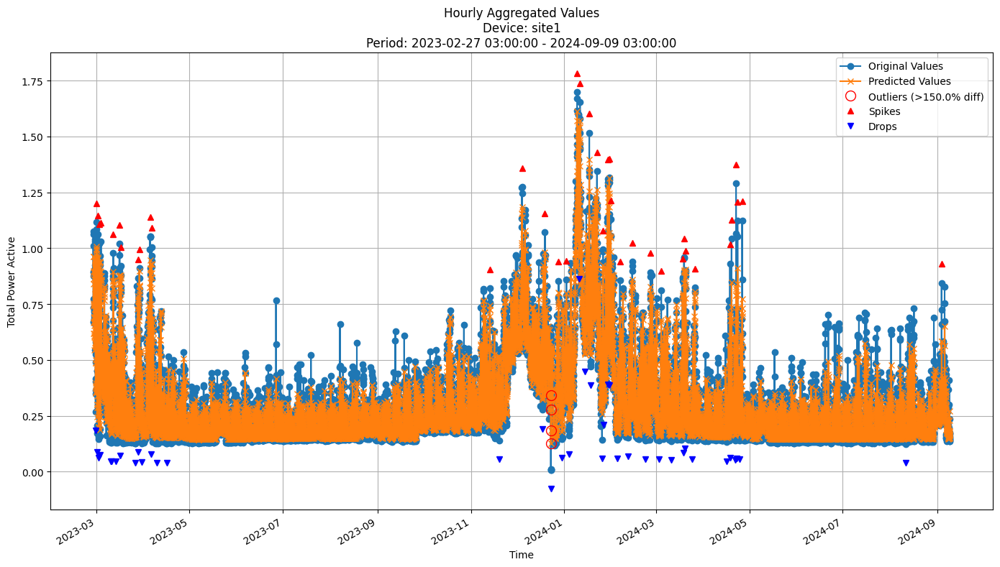


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0563
MAE: 0.0392
MAPE: 15.5673%

Directional Metrics:
Directional Accuracy: 62.7651%
First-Diff Correlation: 0.5933

Immediate Detection (delta=0):
Spikes:
  Precision: 0.5161
  Recall: 0.4211
  F1 Score: 0.4638
Drops:
  Precision: 0.1613
  Recall: 0.1250
  F1 Score: 0.1408

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6129
  Recall: 0.5000
  F1 Score: 0.5507
Drops:
  Precision: 0.3548
  Recall: 0.2750
  F1 Score: 0.3099


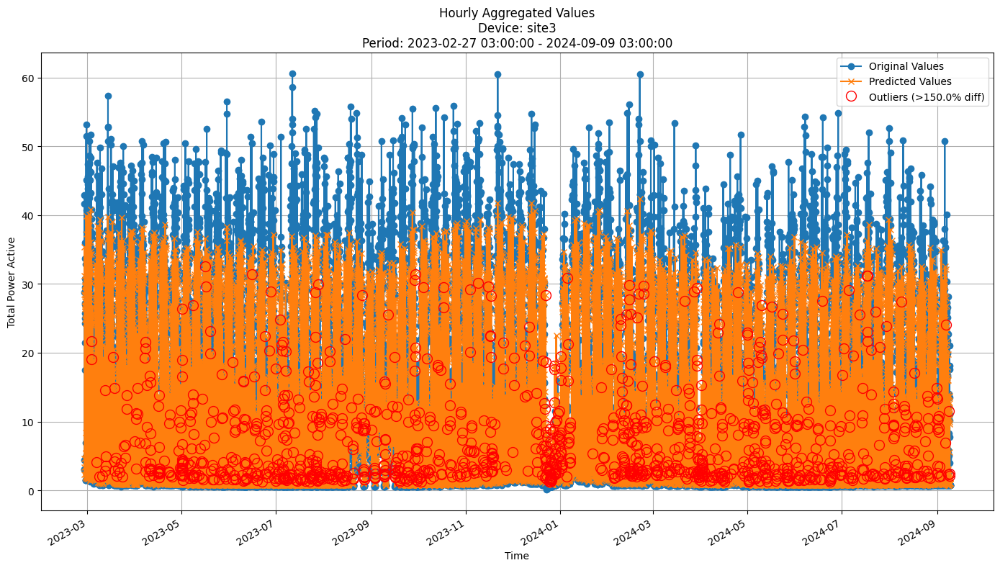


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 5.8573
MAE: 3.9005
MAPE: 61.9907%

Directional Metrics:
Directional Accuracy: 62.9437%
First-Diff Correlation: 0.6545

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


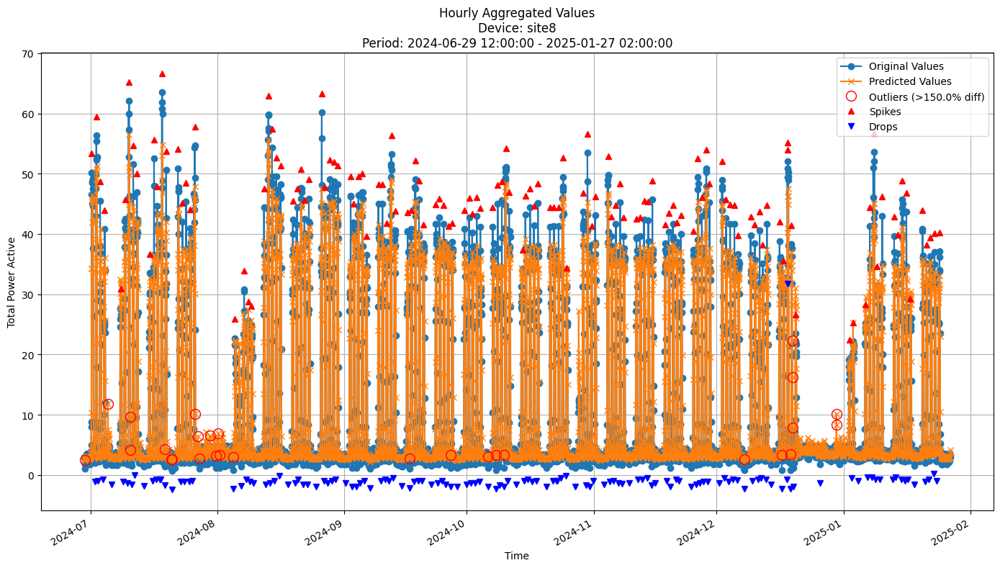


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.4961
MAE: 1.4064
MAPE: 19.1332%

Directional Metrics:
Directional Accuracy: 70.5060%
First-Diff Correlation: 0.8882

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1667
  Recall: 0.1704
  F1 Score: 0.1685
Drops:
  Precision: 0.2628
  Recall: 0.2647
  F1 Score: 0.2637

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2971
  Recall: 0.3037
  F1 Score: 0.3004
Drops:
  Precision: 0.3796
  Recall: 0.3824
  F1 Score: 0.3810


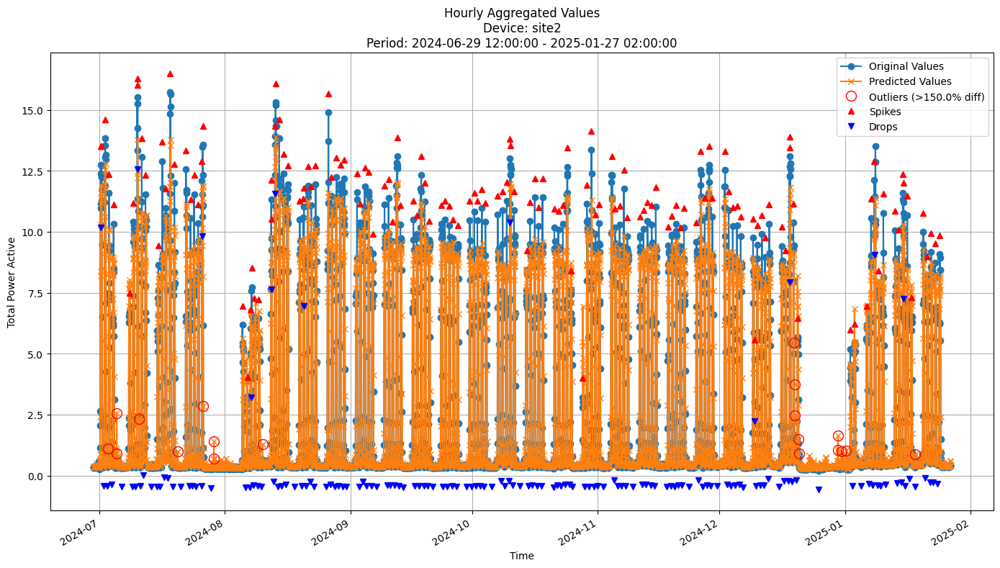


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.6158
MAE: 0.3023
MAPE: 15.7896%

Directional Metrics:
Directional Accuracy: 69.4822%
First-Diff Correlation: 0.8963

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1884
  Recall: 0.1757
  F1 Score: 0.1818
Drops:
  Precision: 0.1460
  Recall: 0.1351
  F1 Score: 0.1404

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3043
  Recall: 0.2838
  F1 Score: 0.2937
Drops:
  Precision: 0.2701
  Recall: 0.2500
  F1 Score: 0.2596


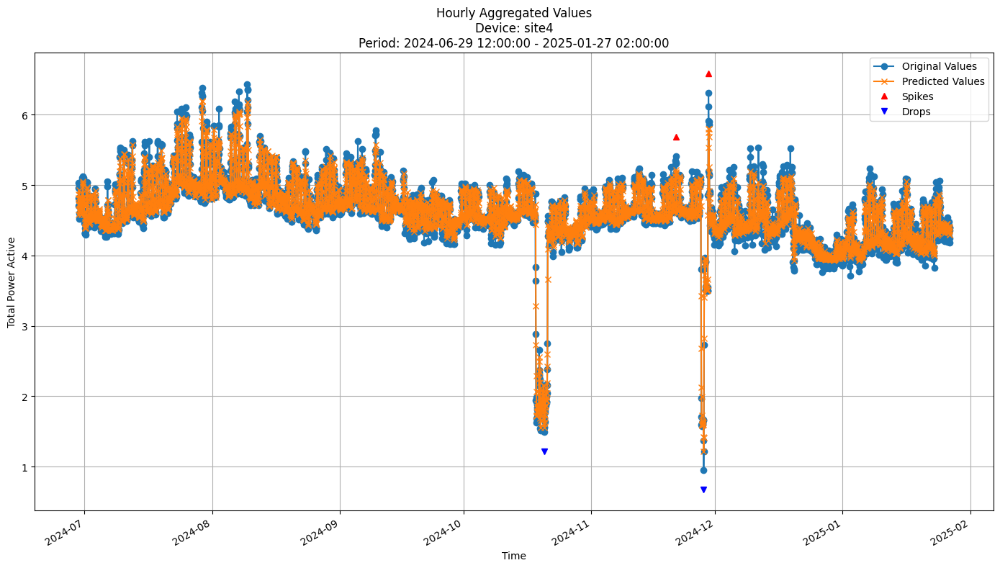


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1195
MAE: 0.0830
MAPE: 1.8322%

Directional Metrics:
Directional Accuracy: 64.8159%
First-Diff Correlation: 0.6195

Immediate Detection (delta=0):
Spikes:
  Precision: 1.0000
  Recall: 0.5000
  F1 Score: 0.6667
Drops:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 0.5000
  F1 Score: 0.6667
Drops:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000


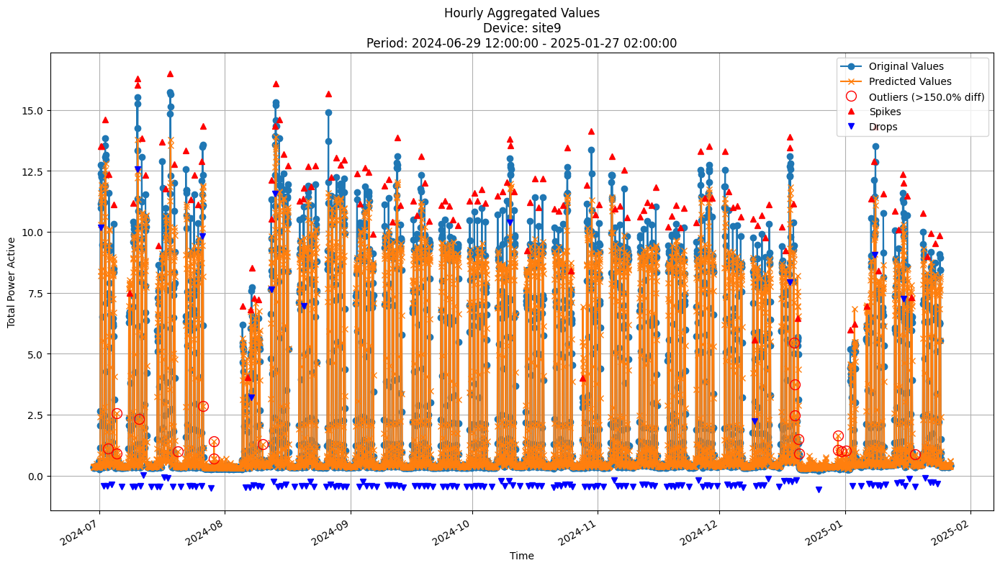


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.6158
MAE: 0.3023
MAPE: 15.7896%

Directional Metrics:
Directional Accuracy: 69.4822%
First-Diff Correlation: 0.8963

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1884
  Recall: 0.1757
  F1 Score: 0.1818
Drops:
  Precision: 0.1460
  Recall: 0.1351
  F1 Score: 0.1404

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3043
  Recall: 0.2838
  F1 Score: 0.2937
Drops:
  Precision: 0.2701
  Recall: 0.2500
  F1 Score: 0.2596


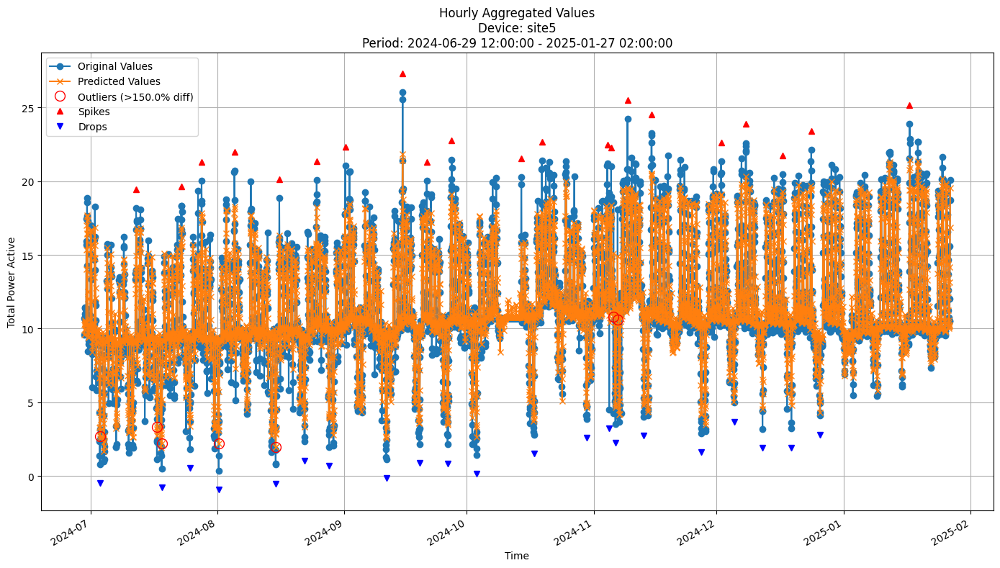


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.9805
MAE: 0.6920
MAPE: 7.4077%

Directional Metrics:
Directional Accuracy: 69.7775%
First-Diff Correlation: 0.7354

Immediate Detection (delta=0):
Spikes:
  Precision: 0.4167
  Recall: 0.2381
  F1 Score: 0.3030
Drops:
  Precision: 0.3077
  Recall: 0.1905
  F1 Score: 0.2353

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.2857
  F1 Score: 0.3636
Drops:
  Precision: 0.4615
  Recall: 0.2857
  F1 Score: 0.3529


In [36]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

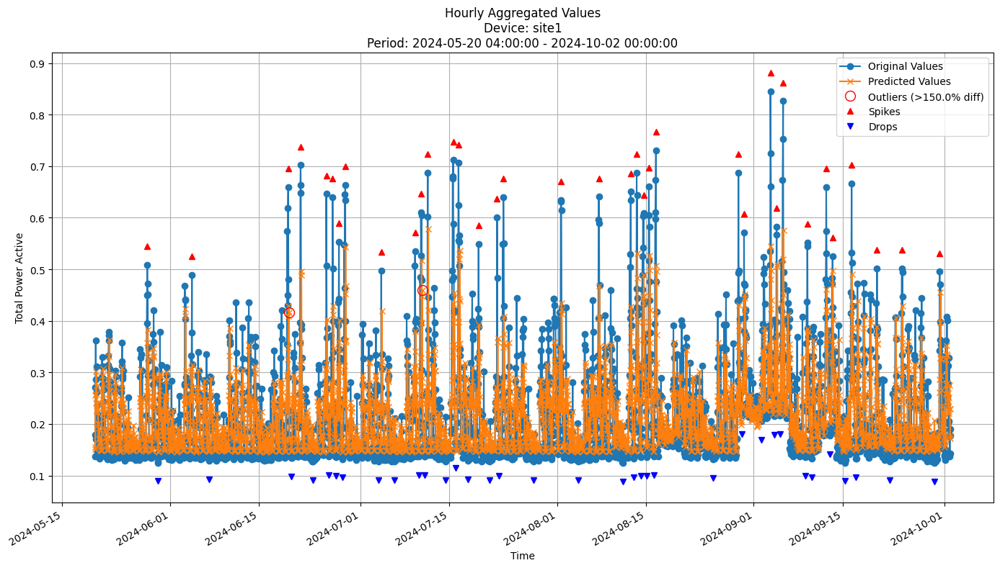


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0709
MAE: 0.0436
MAPE: 18.5874%

Directional Metrics:
Directional Accuracy: 55.7478%
First-Diff Correlation: 0.2342

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6667
  Recall: 0.0556
  F1 Score: 0.1026
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


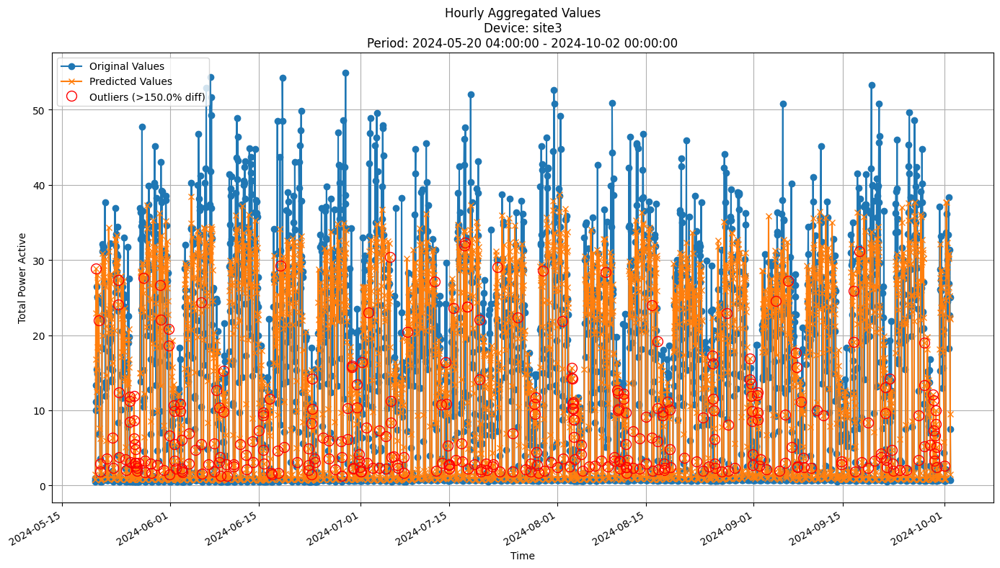


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 6.6616
MAE: 4.4932
MAPE: 68.9219%

Directional Metrics:
Directional Accuracy: 53.4302%
First-Diff Correlation: 0.4786

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


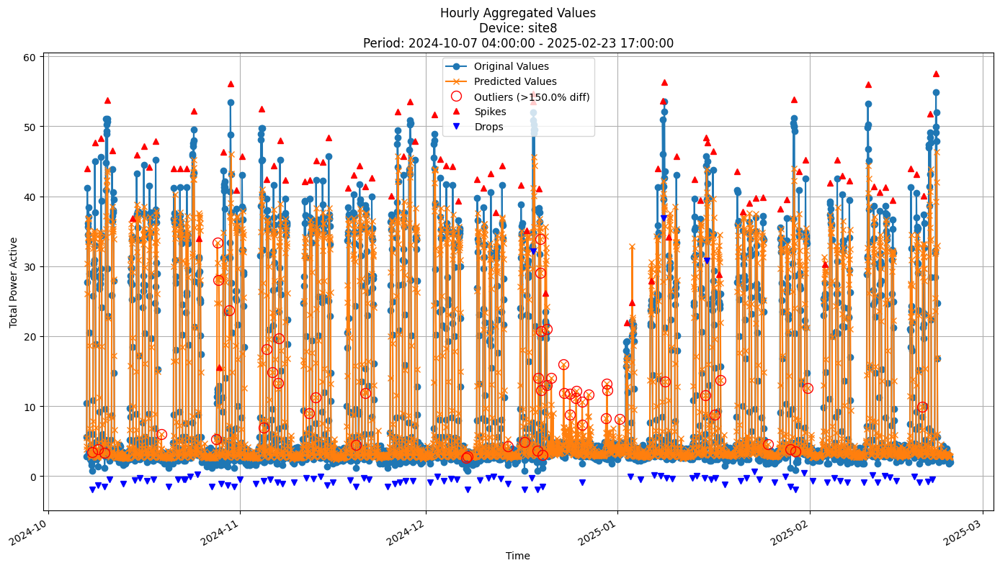


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 3.9990
MAE: 2.1313
MAPE: 25.9304%

Directional Metrics:
Directional Accuracy: 58.1791%
First-Diff Correlation: 0.6887

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0515
  Recall: 0.0526
  F1 Score: 0.0521
Drops:
  Precision: 0.1250
  Recall: 0.1263
  F1 Score: 0.1257

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1856
  Recall: 0.1895
  F1 Score: 0.1875
Drops:
  Precision: 0.2396
  Recall: 0.2421
  F1 Score: 0.2408


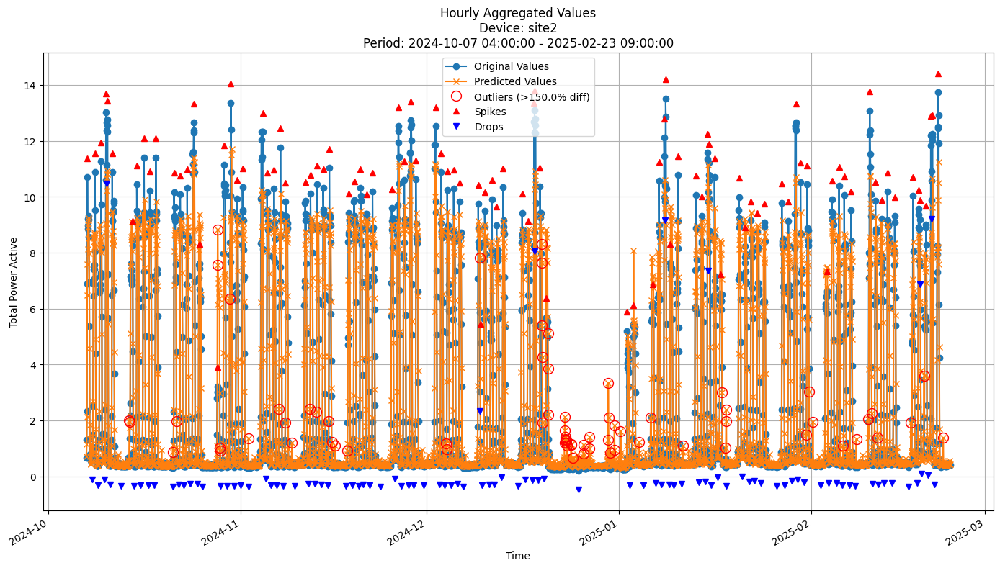


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.9682
MAE: 0.4849
MAPE: 27.3554%

Directional Metrics:
Directional Accuracy: 61.8492%
First-Diff Correlation: 0.7237

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0851
  Recall: 0.0808
  F1 Score: 0.0829
Drops:
  Precision: 0.1075
  Recall: 0.1020
  F1 Score: 0.1047

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2340
  Recall: 0.2222
  F1 Score: 0.2280
Drops:
  Precision: 0.2366
  Recall: 0.2245
  F1 Score: 0.2304


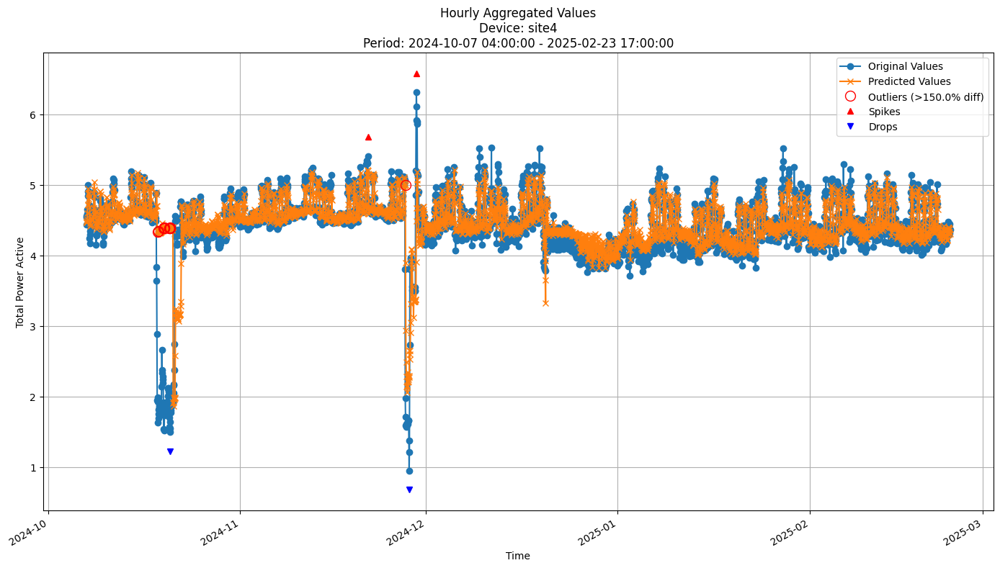


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4171
MAE: 0.1854
MAPE: 5.8686%

Directional Metrics:
Directional Accuracy: 53.8806%
First-Diff Correlation: 0.0948

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


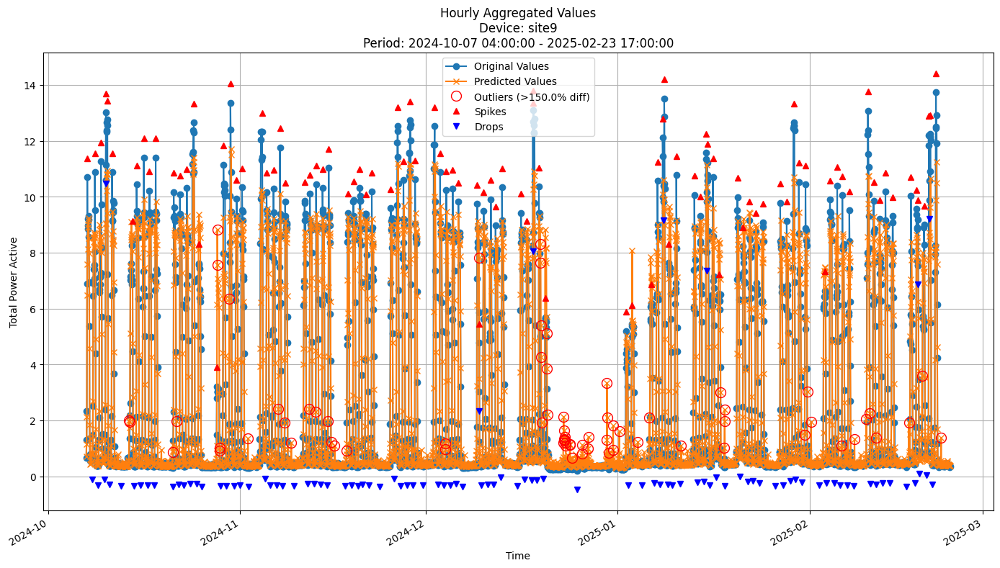


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.9671
MAE: 0.4838
MAPE: 27.3160%

Directional Metrics:
Directional Accuracy: 61.8209%
First-Diff Correlation: 0.7236

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0851
  Recall: 0.0808
  F1 Score: 0.0829
Drops:
  Precision: 0.1075
  Recall: 0.1020
  F1 Score: 0.1047

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2340
  Recall: 0.2222
  F1 Score: 0.2280
Drops:
  Precision: 0.2366
  Recall: 0.2245
  F1 Score: 0.2304


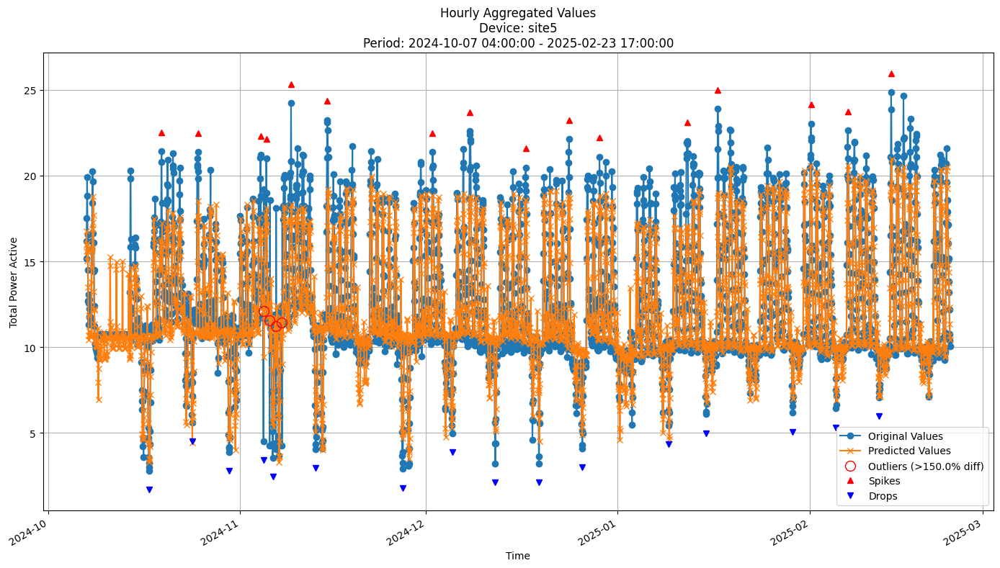


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.6278
MAE: 1.1190
MAPE: 9.0499%

Directional Metrics:
Directional Accuracy: 62.8358%
First-Diff Correlation: 0.3839

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.1250
  Recall: 0.0625
  F1 Score: 0.0833


In [37]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [12]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

hoef = HoeffdingTreeRegressor
hoef_params = {
    'grace_period': 10,
    'delta': 0.5,
    'max_depth': 10,
    'tau': 0.05,
    'leaf_prediction': 'mean'
}

In [13]:
hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=hoef, 
    model_params=hoef_params,
    train=train, 
    valid=valid, 
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1110
	MAE: 0.0822
	MAPE: 30.8622%

Directional Metrics:
	Directional Accuracy: 50.8197%
	First-Diff Correlation: 0.3397

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0690
		Recall: 0.0870
		F1: 0.0769
	Drops:
		Precision: 0.0714
		Recall: 0.0909
		F1: 0.0800

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.1724
		Recall: 0.2174
		F1: 0.1923
	Drops:
		Precision: 0.2500
		Recall: 0.3182
		F1: 0.2800
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0625
	MAE: 0.0432
	MAPE: 23.2779%

Directional Metrics:
	Directional Accuracy: 58.5693%
	First-Diff Correlation: 0.3519

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1351
		Recall: 0.1163
		F1: 0.1250
	Drops:
		Precision: 0.0556
		Recall: 0.0435
		F1: 0.0488

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2973
		Recall: 0.2558
		F1: 0.2750
	Drops:
		Precision: 0.1667
		Recall: 0.1304
		F1: 0.1463
--------------------------------------------------
Dai

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

[! WARNING !] No validation data for device site1 in split 23. Skipping.
[! WARNING !] No validation data for device site3 in split 23. Skipping.
Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 0.000053 MB
Metrics for Device: site8 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 4.5981
	MAE: 2.4592
	MAPE: 29.5441%

Directional Metrics:
	Directional Accuracy: 49.0313%
	First-Diff Correlation: 0.5025

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0732
		Recall: 0.1429
		F1: 0.0968
	Drops:
		Precision: 0.0714
		Recall: 0.1429
		F1: 0.0952

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

[! WARNING !] No validation data for device site1 in split 24. Skipping.
[! WARNING !] No validation data for device site3 in split 24. Skipping.
Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 0.000053 MB
Metrics for Device: site8 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 5.6041
	MAE: 3.0161
	MAPE: 33.6725%

Directional Metrics:
	Directional Accuracy: 48.4894%
	First-Diff Correlation: 0.4661

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0750
		Recall: 0.1200
		F1: 0.0923
	Drops:
		Precision: 0.0256
		Recall: 0.0417
		F1: 0.0317

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2

#### Results

In [14]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0967 ± 0.0211
	MAE: 0.0642 ± 0.0181
	MAPE: 23.4022% ± 4.9568%

	Directional Metrics:
		Directional Accuracy: 41.9211% ± 4.8059%
		First-Diff Correlation: 0.3713 ± 0.0490

	Immediate Detection (delta=0):
		Spike Precision: 0.1234 ± 0.0410
		Spike Recall: 0.1349 ± 0.0376
		Spike F1: 0.1282 ± 0.0382
		Drop Precision: 0.0936 ± 0.0180
		Drop Recall: 0.1107 ± 0.0377
		Drop F1: 0.1003 ± 0.0234

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3119 ± 0.0602
		Spike Recall: 0.3499 ± 0.0283
		Spike F1: 0.3273 ± 0.0401
		Drop Precision: 0.2145 ± 0.0424
		Drop Recall: 0.2520 ± 0.0757
		Drop F1: 0.2292 ± 0.0485
Daily Metrics:
	RMSE: 1.1214 ± 0.3786
	MAE: 0.7229 ± 0.3078
	MAPE: 10.2611% ± 3.4576%

	Directional Metrics:
		Directional Accuracy: 84.4470% ± 4.1420%
		First-Diff Correlation: 0.8752 ± 0.0350

	Immediate Detection (delta=0):
		Spi

#### Training plots
Plot only the last period of predictions

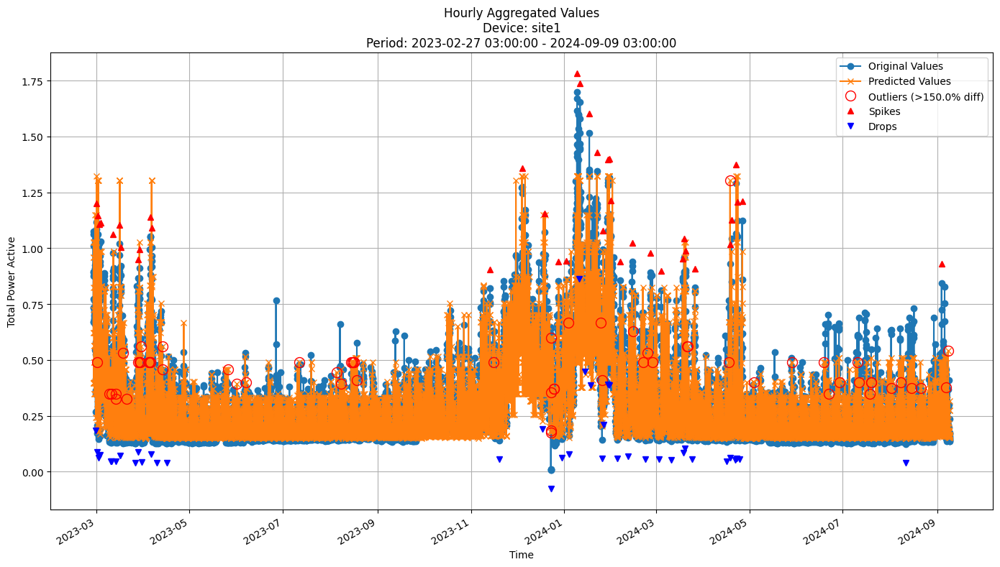


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0973
MAE: 0.0633
MAPE: 23.0756%

Directional Metrics:
Directional Accuracy: 41.3647%
First-Diff Correlation: 0.3042

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0877
  Recall: 0.1316
  F1 Score: 0.1053
Drops:
  Precision: 0.0145
  Recall: 0.0250
  F1 Score: 0.0183

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2456
  Recall: 0.3684
  F1 Score: 0.2947
Drops:
  Precision: 0.1159
  Recall: 0.2000
  F1 Score: 0.1468


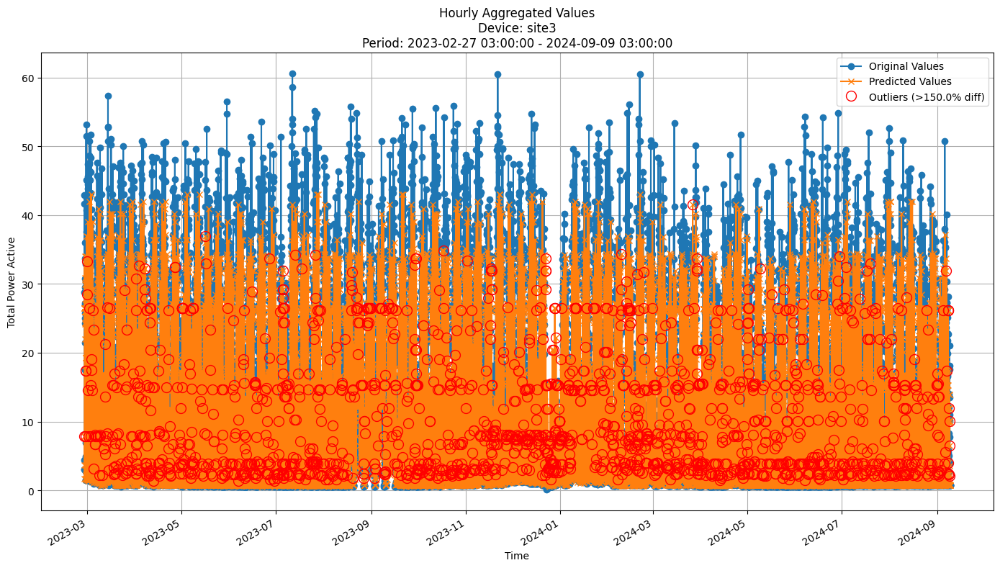


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.9413
MAE: 5.3224
MAPE: 103.2252%

Directional Metrics:
Directional Accuracy: 47.7491%
First-Diff Correlation: 0.3615

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


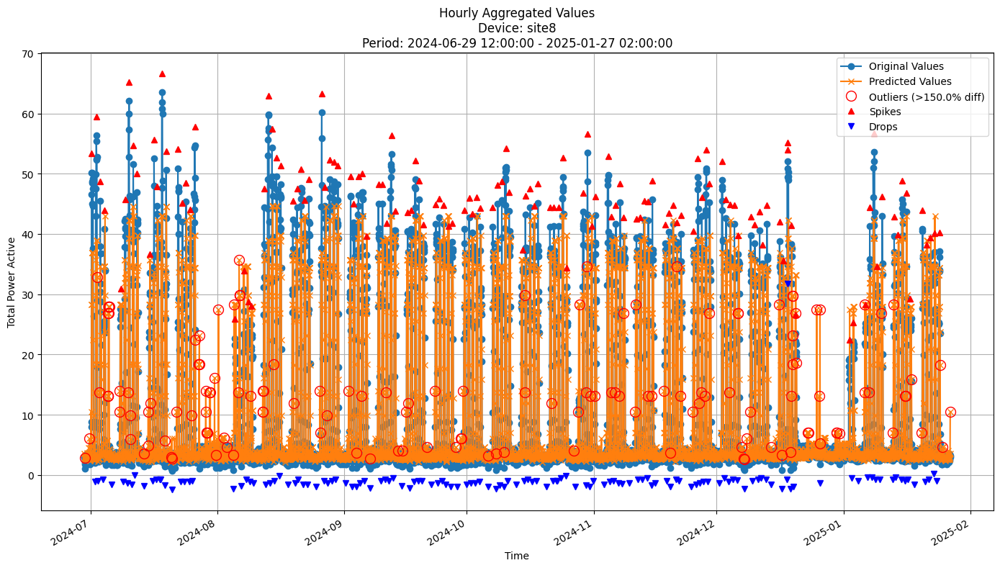


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 5.0715
MAE: 2.6310
MAPE: 32.7655%

Directional Metrics:
Directional Accuracy: 48.3166%
First-Diff Correlation: 0.5639

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0766
  Recall: 0.1185
  F1 Score: 0.0930
Drops:
  Precision: 0.0914
  Recall: 0.1324
  F1 Score: 0.1081

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1818
  Recall: 0.2815
  F1 Score: 0.2209
Drops:
  Precision: 0.2183
  Recall: 0.3162
  F1 Score: 0.2583


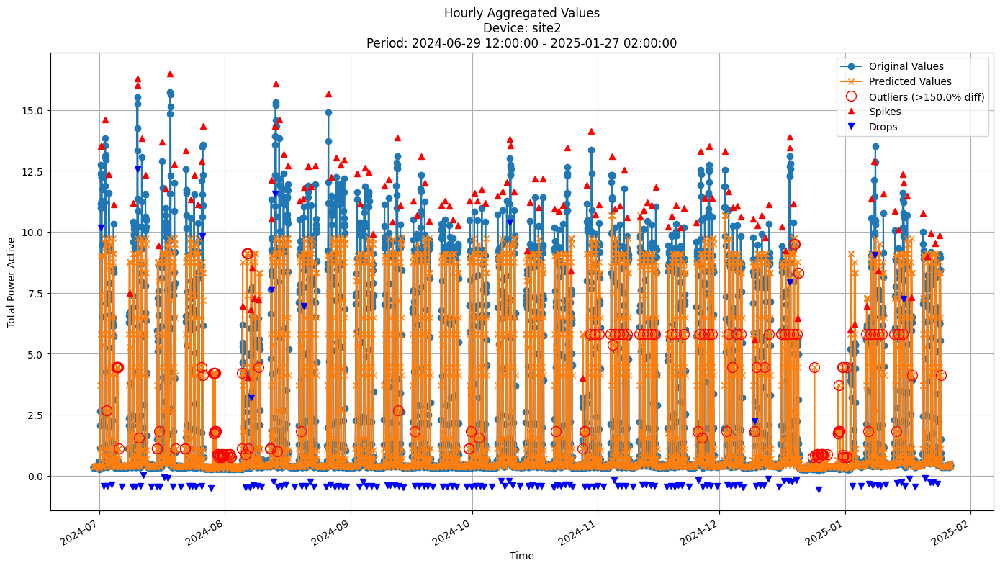


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2747
MAE: 0.6279
MAPE: 32.9732%

Directional Metrics:
Directional Accuracy: 35.1644%
First-Diff Correlation: 0.4047

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0932
  Recall: 0.1014
  F1 Score: 0.0971
Drops:
  Precision: 0.0978
  Recall: 0.1216
  F1 Score: 0.1084

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3851
  Recall: 0.4189
  F1 Score: 0.4013
Drops:
  Precision: 0.2228
  Recall: 0.2770
  F1 Score: 0.2470


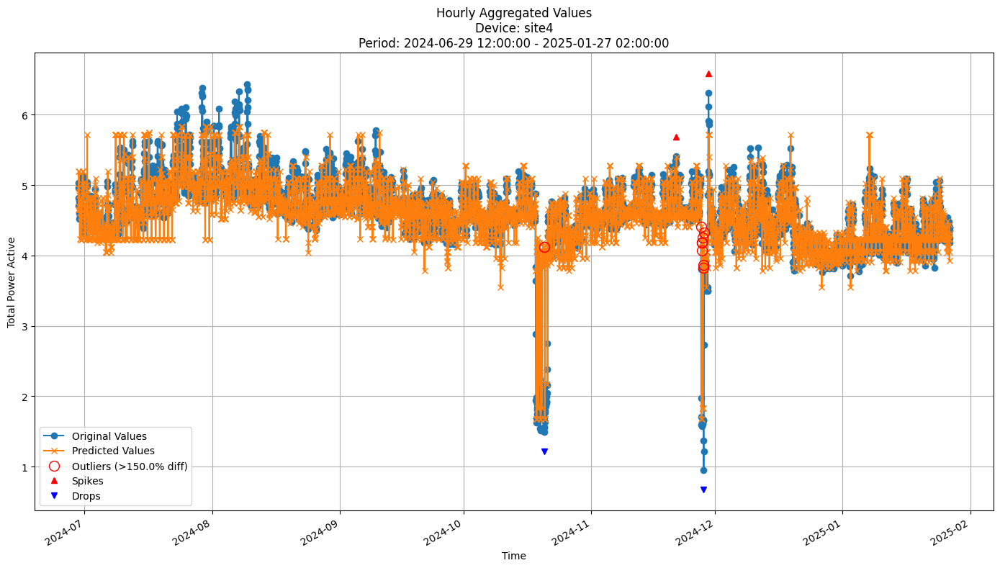


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3122
MAE: 0.1752
MAPE: 4.6216%

Directional Metrics:
Directional Accuracy: 34.7903%
First-Diff Correlation: 0.1358

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.2500
  Recall: 0.5000
  F1 Score: 0.3333


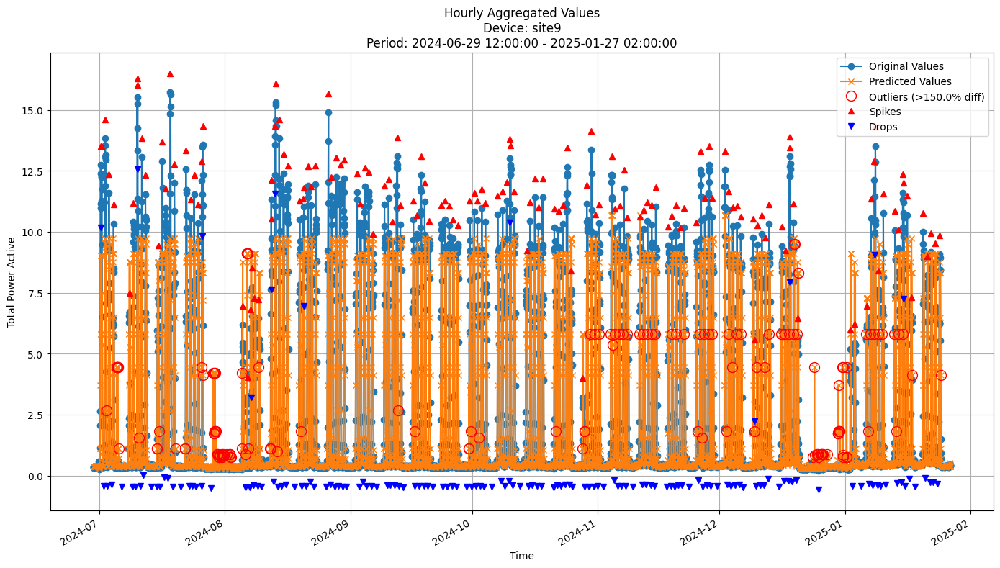


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2747
MAE: 0.6279
MAPE: 32.9732%

Directional Metrics:
Directional Accuracy: 35.1644%
First-Diff Correlation: 0.4047

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0932
  Recall: 0.1014
  F1 Score: 0.0971
Drops:
  Precision: 0.0978
  Recall: 0.1216
  F1 Score: 0.1084

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3851
  Recall: 0.4189
  F1 Score: 0.4013
Drops:
  Precision: 0.2228
  Recall: 0.2770
  F1 Score: 0.2470


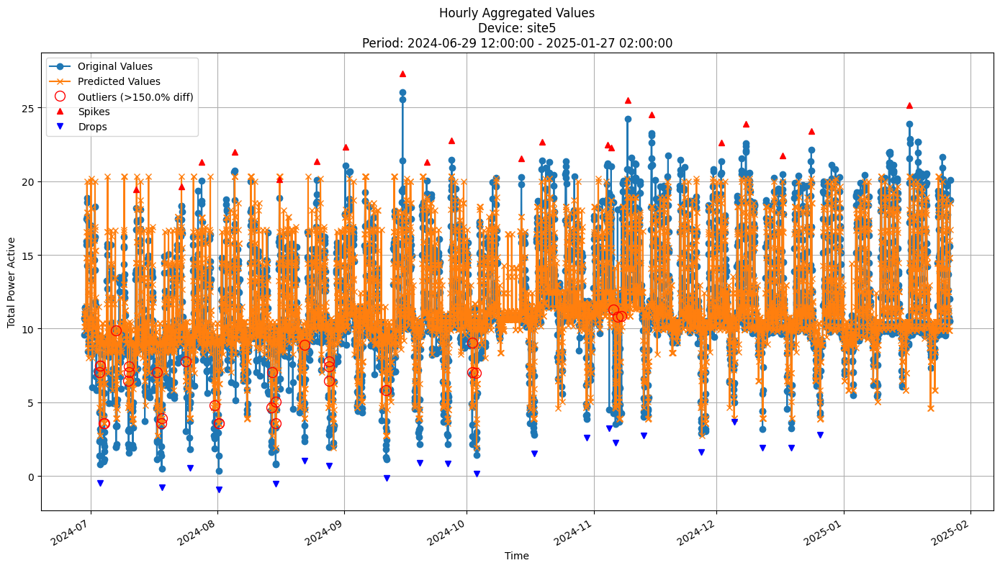


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.9022
MAE: 1.2771
MAPE: 13.8539%

Directional Metrics:
Directional Accuracy: 45.1664%
First-Diff Correlation: 0.2369

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.2917
  Recall: 0.3333
  F1 Score: 0.3111

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1724
  Recall: 0.2381
  F1 Score: 0.2000
Drops:
  Precision: 0.4167
  Recall: 0.4762
  F1 Score: 0.4444


In [15]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

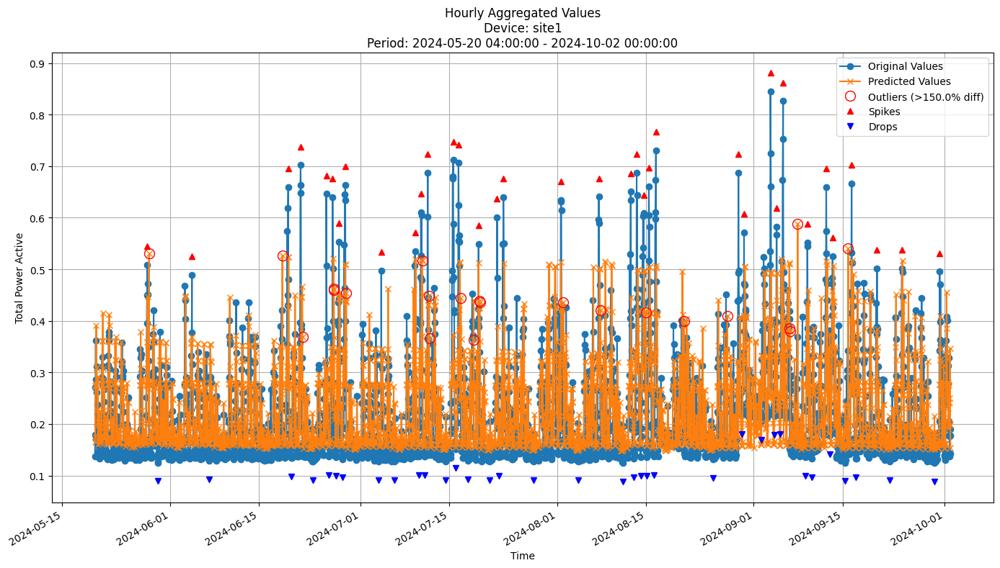


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0842
MAE: 0.0542
MAPE: 24.4795%

Directional Metrics:
Directional Accuracy: 54.1409%
First-Diff Correlation: 0.1892

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0938
  Recall: 0.0833
  F1 Score: 0.0882
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2500
  Recall: 0.2222
  F1 Score: 0.2353
Drops:
  Precision: 0.0645
  Recall: 0.0571
  F1 Score: 0.0606


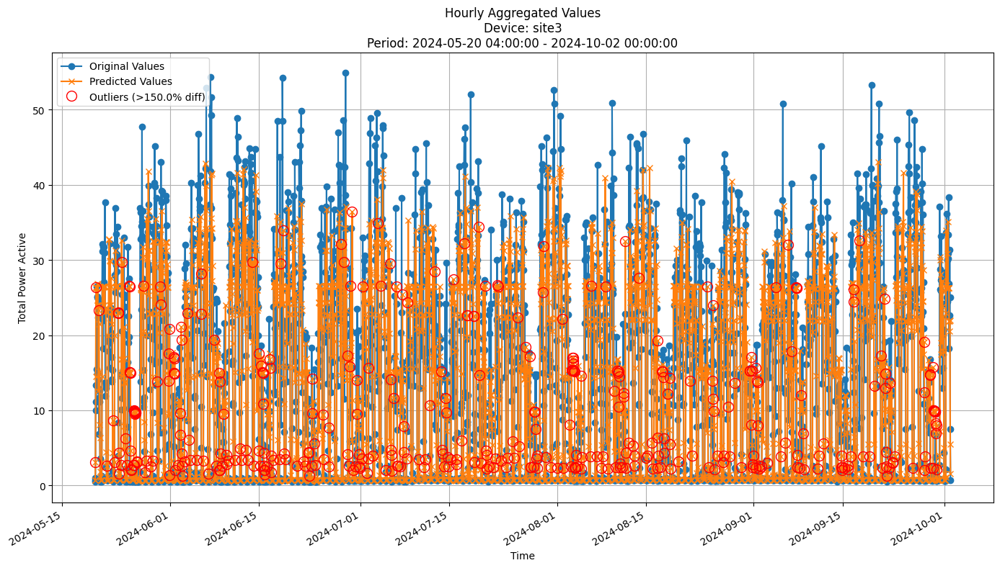


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.8311
MAE: 5.1890
MAPE: 85.8615%

Directional Metrics:
Directional Accuracy: 48.0532%
First-Diff Correlation: 0.2786

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


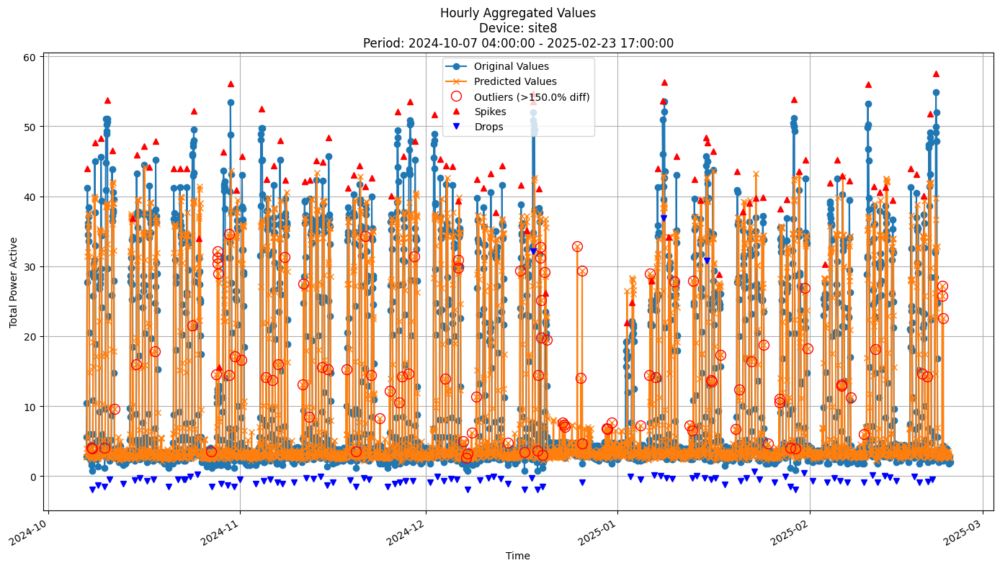


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 5.1289
MAE: 2.7219
MAPE: 33.1123%

Directional Metrics:
Directional Accuracy: 51.1940%
First-Diff Correlation: 0.4903

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0730
  Recall: 0.1053
  F1 Score: 0.0862
Drops:
  Precision: 0.0588
  Recall: 0.0842
  F1 Score: 0.0693

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1898
  Recall: 0.2737
  F1 Score: 0.2241
Drops:
  Precision: 0.1838
  Recall: 0.2632
  F1 Score: 0.2165


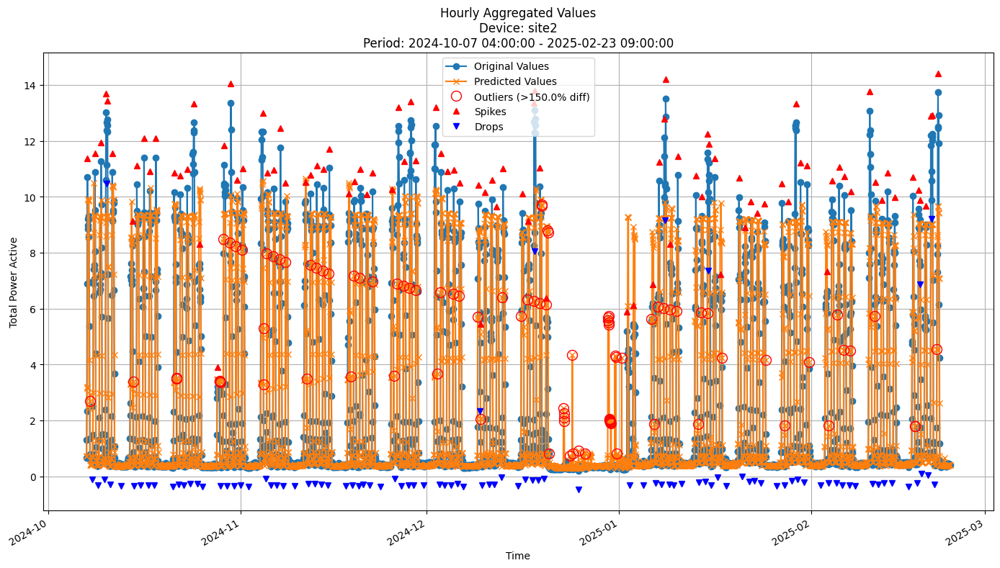


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.3857
MAE: 0.6732
MAPE: 33.3262%

Directional Metrics:
Directional Accuracy: 50.5087%
First-Diff Correlation: 0.3015

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0357
  Recall: 0.0505
  F1 Score: 0.0418
Drops:
  Precision: 0.0647
  Recall: 0.0918
  F1 Score: 0.0759

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3500
  Recall: 0.4949
  F1 Score: 0.4100
Drops:
  Precision: 0.1511
  Recall: 0.2143
  F1 Score: 0.1772


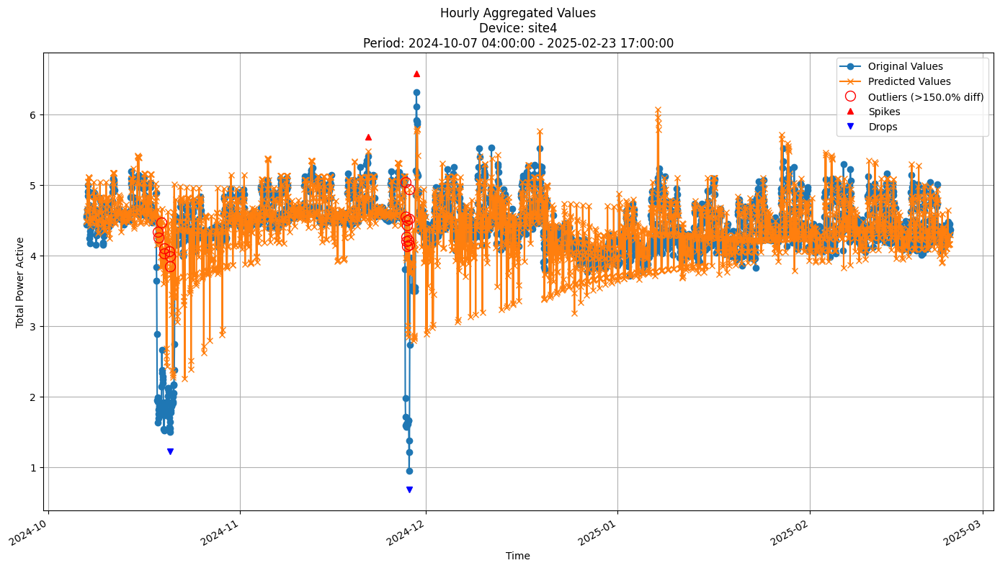


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4562
MAE: 0.2481
MAPE: 7.4691%

Directional Metrics:
Directional Accuracy: 48.9254%
First-Diff Correlation: 0.0519

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


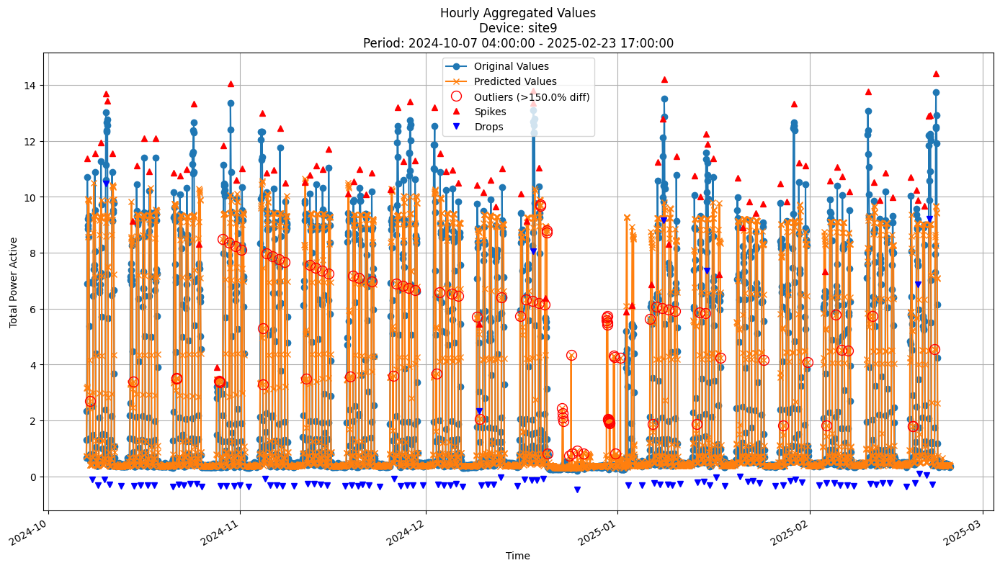


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.3840
MAE: 0.6716
MAPE: 33.2636%

Directional Metrics:
Directional Accuracy: 50.5075%
First-Diff Correlation: 0.3015

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0357
  Recall: 0.0505
  F1 Score: 0.0418
Drops:
  Precision: 0.0647
  Recall: 0.0918
  F1 Score: 0.0759

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3500
  Recall: 0.4949
  F1 Score: 0.4100
Drops:
  Precision: 0.1511
  Recall: 0.2143
  F1 Score: 0.1772


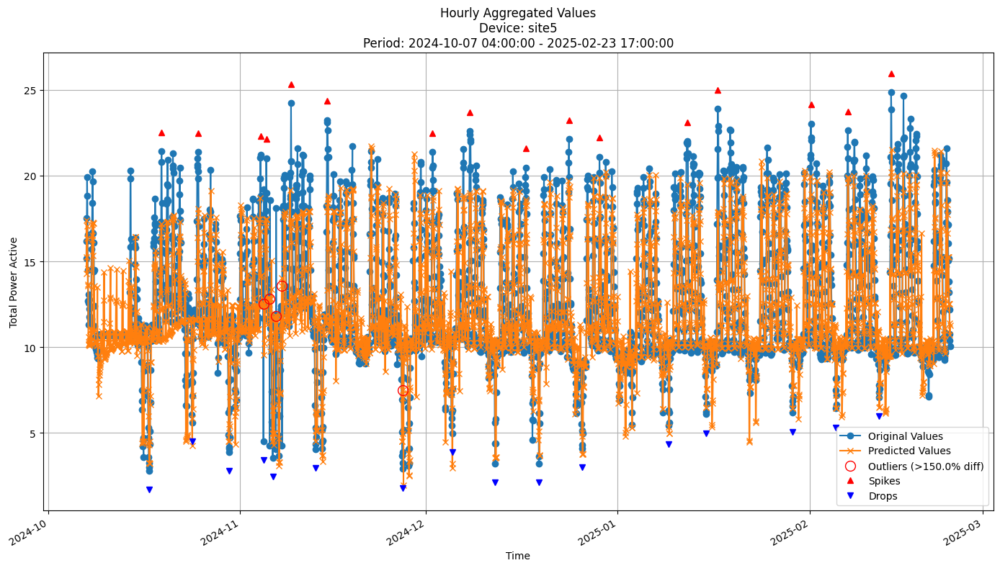


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.0799
MAE: 1.4165
MAPE: 11.3938%

Directional Metrics:
Directional Accuracy: 53.1642%
First-Diff Correlation: 0.2209

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.1667
  Recall: 0.1875
  F1 Score: 0.1765

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.3333
  Recall: 0.3750
  F1 Score: 0.3529


In [16]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [7]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf_hf = ARFRegressor
arf_hf_params = {
    'n_models': 10,
    'max_features': 0.8,
    'aggregation_method': 'median',
    'grace_period': 10,
    'max_depth': 10,
    'delta': 0.5,  # split confidence
    'tau': 0.01,  # break ties
    'seed': 42
}

In [8]:
arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf_hf,
    model_params=arf_hf_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0864
	MAE: 0.0654
	MAPE: 26.0662%

Directional Metrics:
	Directional Accuracy: 58.5693%
	First-Diff Correlation: 0.4029

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0769
		Recall: 0.0870
		F1: 0.0816
	Drops:
		Precision: 0.1600
		Recall: 0.1818
		F1: 0.1702

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.4231
		Recall: 0.4783
		F1: 0.4490
	Drops:
		Precision: 0.2400
		Recall: 0.2727
		F1: 0.2553
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0548
	MAE: 0.0434
	MAPE: 24.0669%

Directional Metrics:
	Directional Accuracy: 56.1848%
	First-Diff Correlation: 0.4006

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2258
		Recall: 0.1628
		F1: 0.1892
	Drops:
		Precision: 0.0667
		Recall: 0.0435
		F1: 0.0526

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2903
		Recall: 0.2093
		F1: 0.2432
	Drops:
		Precision: 0.4000
		Recall: 0.2609
		F1: 0.3158
--------------------------------------------------
Dai

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

[! WARNING !] No validation data for device site1 in split 23. Skipping.
[! WARNING !] No validation data for device site3 in split 23. Skipping.
Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 0.000053 MB
Metrics for Device: site8 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 4.6044
	MAE: 2.3626
	MAPE: 26.0703%

Directional Metrics:
	Directional Accuracy: 53.8003%
	First-Diff Correlation: 0.4604

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0541
		Recall: 0.0952
		F1: 0.0690
	Drops:
		Precision: 0.0556
		Recall: 0.0952
		F1: 0.0702

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.1

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

[! WARNING !] No validation data for device site1 in split 24. Skipping.
[! WARNING !] No validation data for device site3 in split 24. Skipping.
Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 0.000053 MB
Metrics for Device: site8 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 5.2826
	MAE: 2.7820
	MAPE: 25.5469%

Directional Metrics:
	Directional Accuracy: 57.8550%
	First-Diff Correlation: 0.5311

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1538
		Recall: 0.1600
		F1: 0.1569
	Drops:
		Precision: 0.0800
		Recall: 0.0833
		F1: 0.0816

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3

#### Results

In [9]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.1057 ± 0.0322
	MAE: 0.0766 ± 0.0338
	MAPE: 31.9123% ± 20.7777%

	Directional Metrics:
		Directional Accuracy: 52.8375% ± 6.1183%
		First-Diff Correlation: 0.3554 ± 0.1083

	Immediate Detection (delta=0):
		Spike Precision: 0.1444 ± 0.0594
		Spike Recall: 0.1300 ± 0.0327
		Spike F1: 0.1326 ± 0.0379
		Drop Precision: 0.0937 ± 0.0295
		Drop Recall: 0.0892 ± 0.0296
		Drop F1: 0.0891 ± 0.0251

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3783 ± 0.0821
		Spike Recall: 0.3602 ± 0.0928
		Spike F1: 0.3585 ± 0.0653
		Drop Precision: 0.2515 ± 0.0499
		Drop Recall: 0.2503 ± 0.0985
		Drop F1: 0.2442 ± 0.0613
Daily Metrics:
	RMSE: 1.7412 ± 0.8898
	MAE: 1.2674 ± 0.9075
	MAPE: 20.3651% ± 19.4043%

	Directional Metrics:
		Directional Accuracy: 79.7221% ± 6.6988%
		First-Diff Correlation: 0.8067 ± 0.1300

	Immediate Detection (delta=0):
		S

#### Training plots

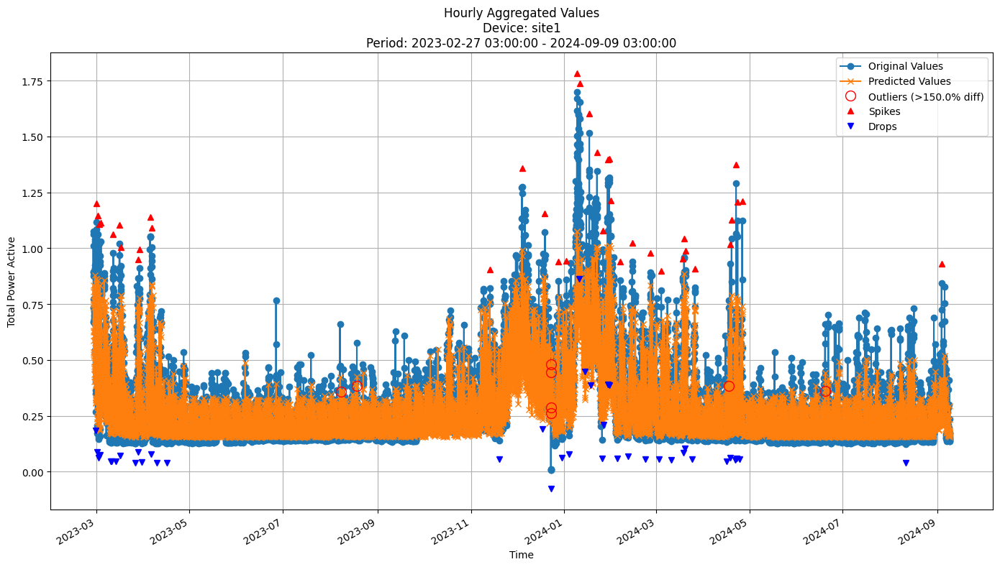


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0975
MAE: 0.0647
MAPE: 22.7899%

Directional Metrics:
Directional Accuracy: 53.0992%
First-Diff Correlation: 0.2752

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0577
  Recall: 0.0789
  F1 Score: 0.0667
Drops:
  Precision: 0.0833
  Recall: 0.1250
  F1 Score: 0.1000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1923
  Recall: 0.2632
  F1 Score: 0.2222
Drops:
  Precision: 0.1500
  Recall: 0.2250
  F1 Score: 0.1800


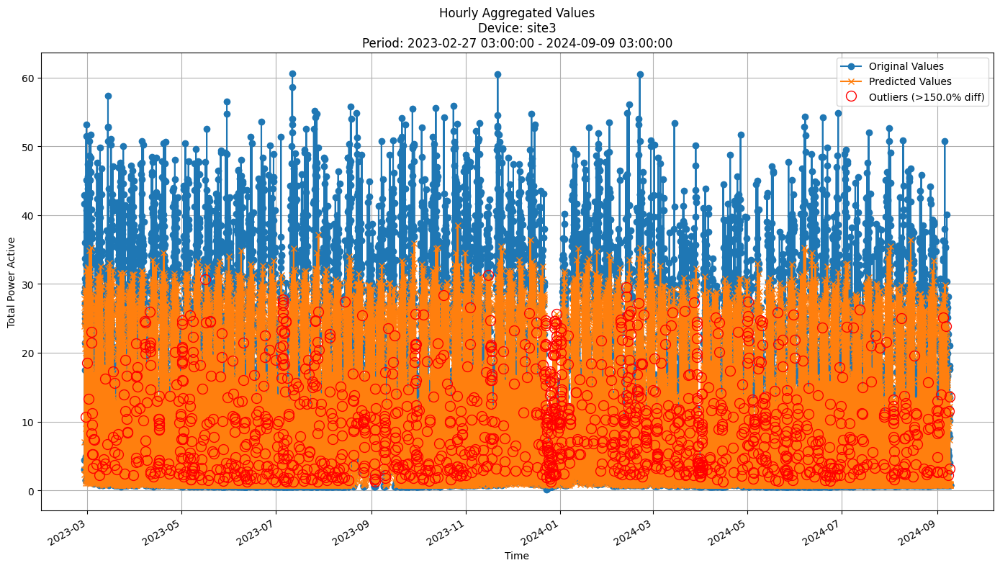


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.3917
MAE: 4.9455
MAPE: 84.4651%

Directional Metrics:
Directional Accuracy: 56.7304%
First-Diff Correlation: 0.5075

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


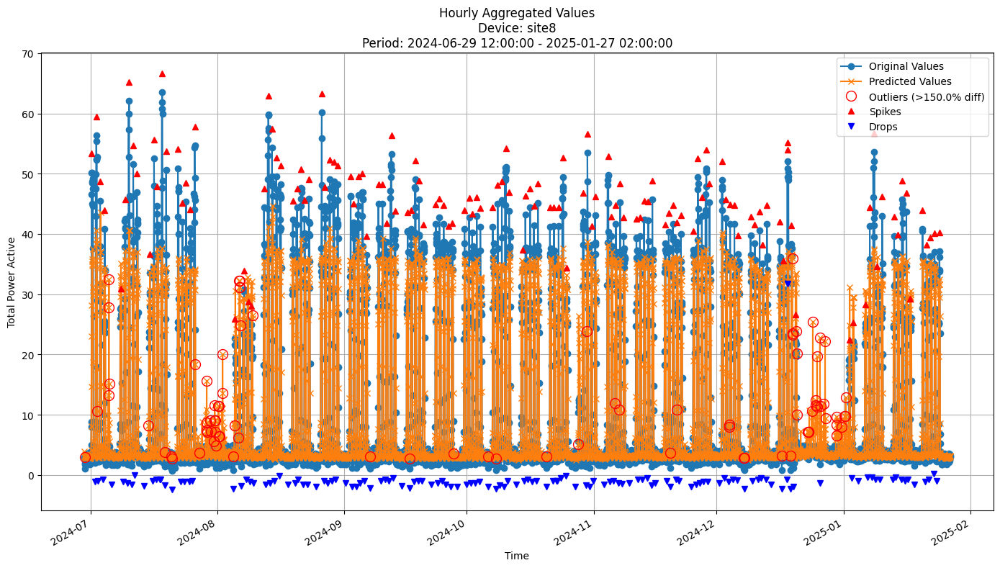


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 4.6677
MAE: 2.3947
MAPE: 27.3994%

Directional Metrics:
Directional Accuracy: 60.8191%
First-Diff Correlation: 0.6808

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1037
  Recall: 0.1259
  F1 Score: 0.1137
Drops:
  Precision: 0.1195
  Recall: 0.1397
  F1 Score: 0.1288

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2378
  Recall: 0.2889
  F1 Score: 0.2609
Drops:
  Precision: 0.2642
  Recall: 0.3088
  F1 Score: 0.2847


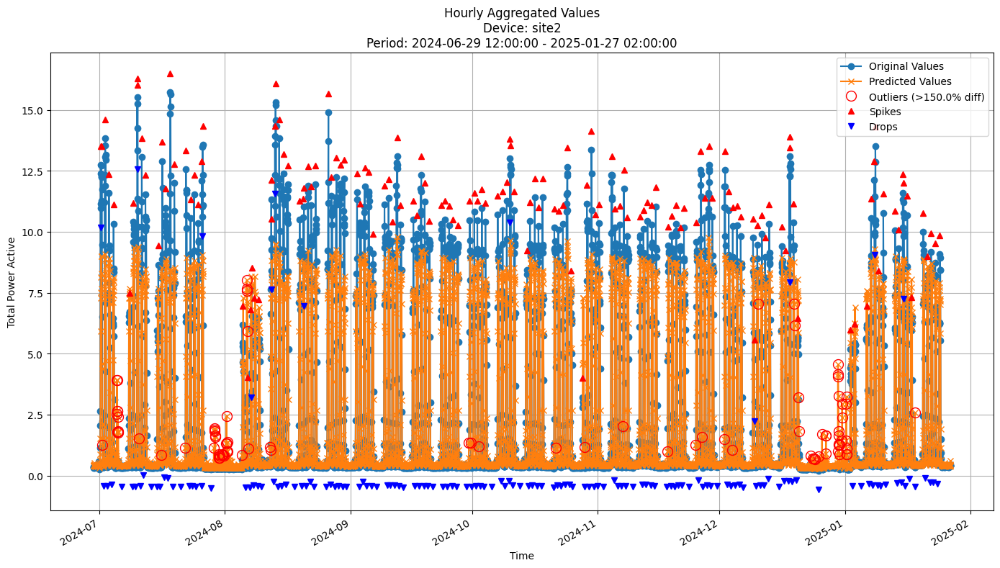


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.1521
MAE: 0.5471
MAPE: 26.7262%

Directional Metrics:
Directional Accuracy: 58.0232%
First-Diff Correlation: 0.7380

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0671
  Recall: 0.0676
  F1 Score: 0.0673
Drops:
  Precision: 0.0974
  Recall: 0.1014
  F1 Score: 0.0993

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2148
  Recall: 0.2162
  F1 Score: 0.2155
Drops:
  Precision: 0.3052
  Recall: 0.3176
  F1 Score: 0.3113


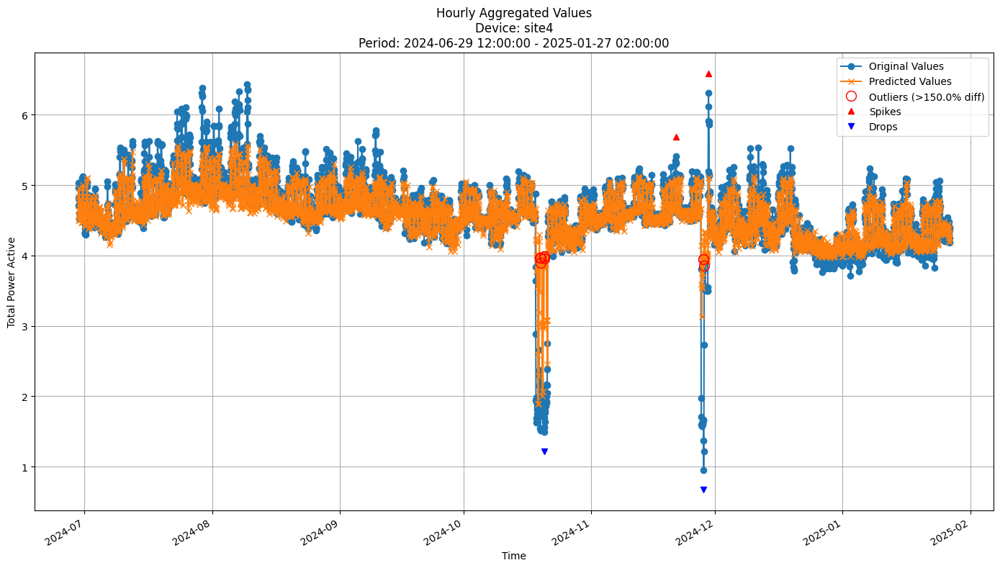


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3050
MAE: 0.1545
MAPE: 4.3061%

Directional Metrics:
Directional Accuracy: 52.4119%
First-Diff Correlation: 0.2353

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


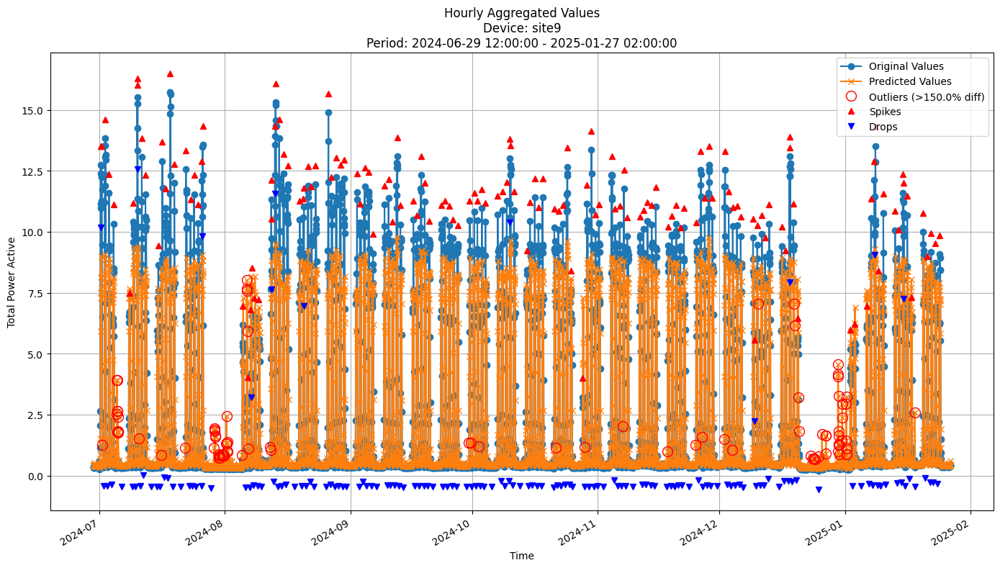


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.1521
MAE: 0.5471
MAPE: 26.7262%

Directional Metrics:
Directional Accuracy: 58.0232%
First-Diff Correlation: 0.7380

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0671
  Recall: 0.0676
  F1 Score: 0.0673
Drops:
  Precision: 0.0974
  Recall: 0.1014
  F1 Score: 0.0993

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2148
  Recall: 0.2162
  F1 Score: 0.2155
Drops:
  Precision: 0.3052
  Recall: 0.3176
  F1 Score: 0.3113


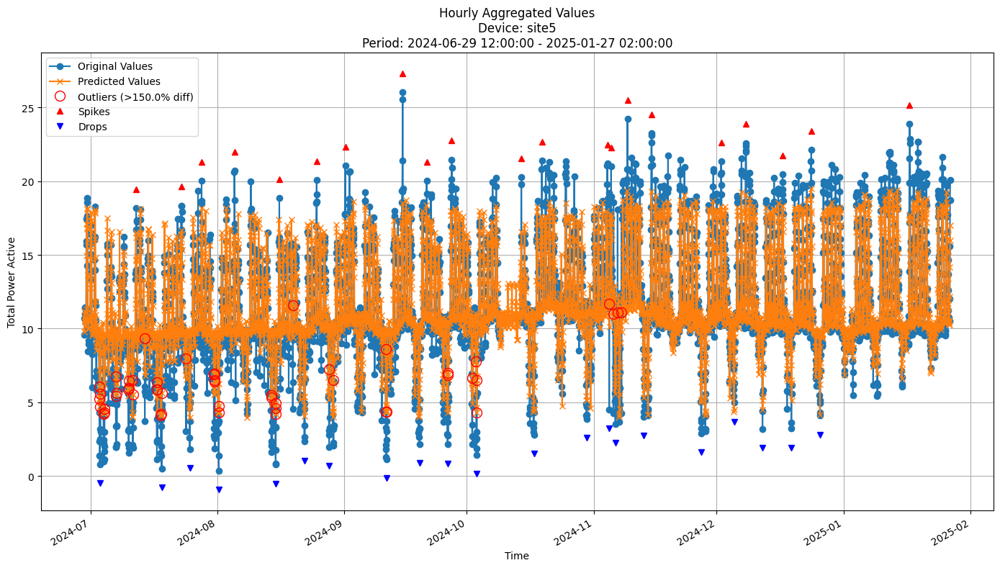


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.6669
MAE: 1.1562
MAPE: 13.5415%

Directional Metrics:
Directional Accuracy: 60.0512%
First-Diff Correlation: 0.3700

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0357
  Recall: 0.0476
  F1 Score: 0.0408
Drops:
  Precision: 0.1034
  Recall: 0.1429
  F1 Score: 0.1200

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1071
  Recall: 0.1429
  F1 Score: 0.1224
Drops:
  Precision: 0.3103
  Recall: 0.4286
  F1 Score: 0.3600


In [10]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

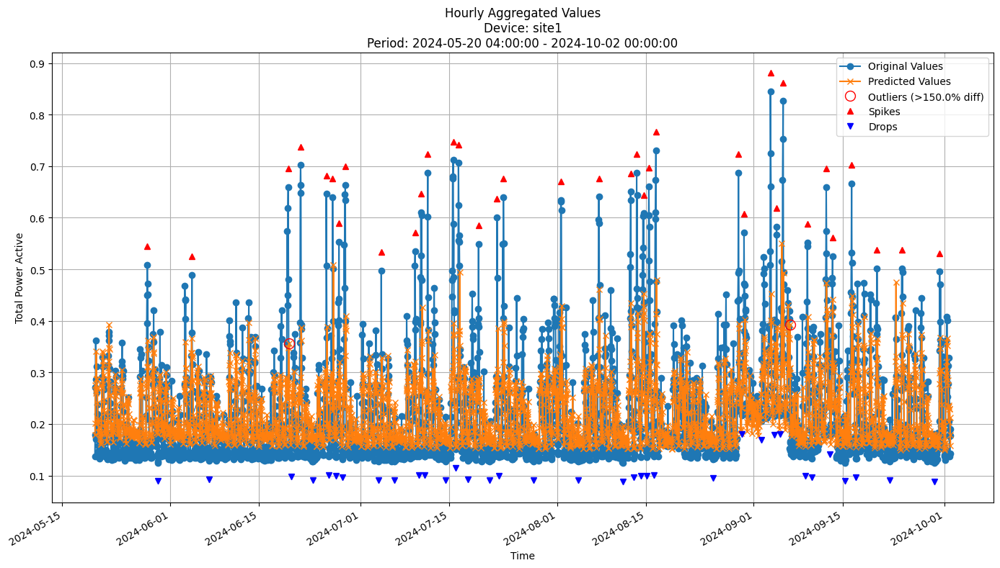


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0756
MAE: 0.0510
MAPE: 23.1293%

Directional Metrics:
Directional Accuracy: 54.1100%
First-Diff Correlation: 0.2025

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


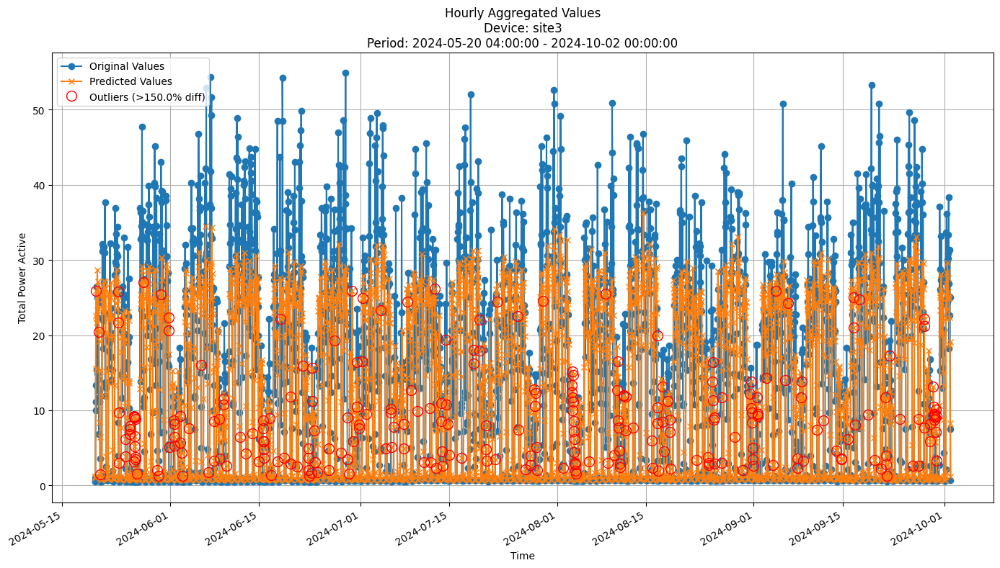


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 6.9613
MAE: 4.6069
MAPE: 64.1418%

Directional Metrics:
Directional Accuracy: 54.0173%
First-Diff Correlation: 0.4627

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


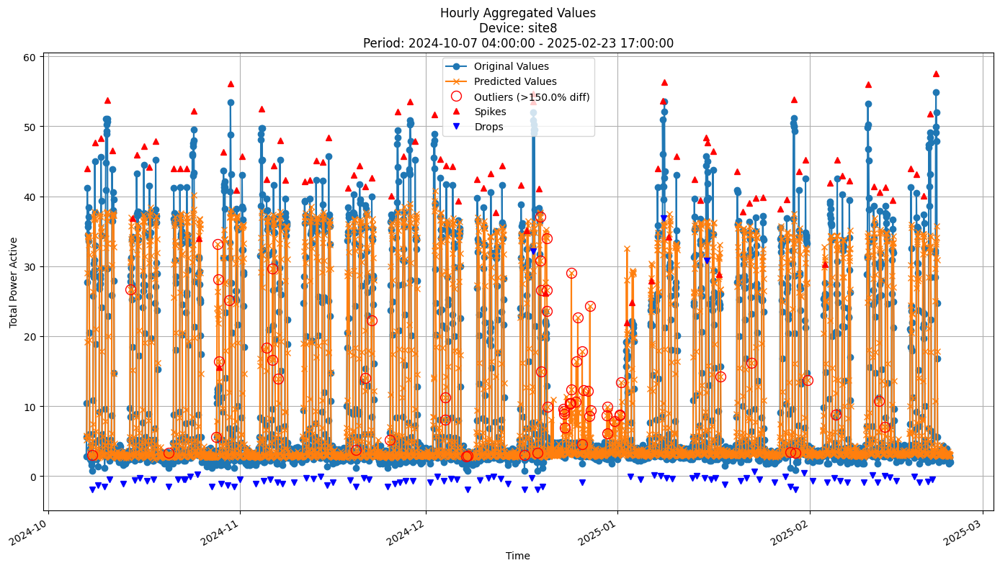


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 4.8602
MAE: 2.4861
MAPE: 27.8754%

Directional Metrics:
Directional Accuracy: 57.4925%
First-Diff Correlation: 0.5463

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0642
  Recall: 0.0737
  F1 Score: 0.0686
Drops:
  Precision: 0.1019
  Recall: 0.1158
  F1 Score: 0.1084

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2202
  Recall: 0.2526
  F1 Score: 0.2353
Drops:
  Precision: 0.2407
  Recall: 0.2737
  F1 Score: 0.2562


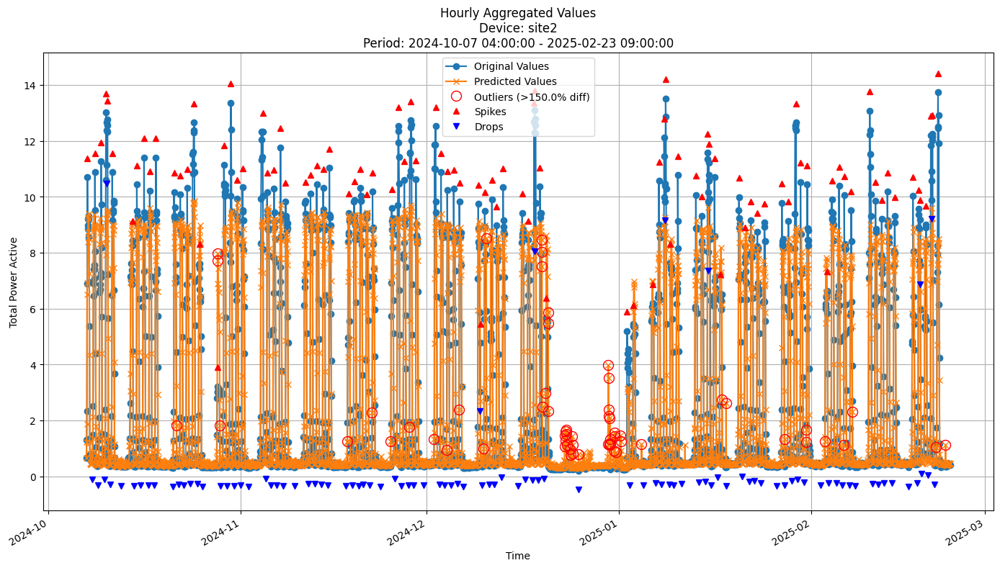


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.0563
MAE: 0.5070
MAPE: 25.6162%

Directional Metrics:
Directional Accuracy: 59.8444%
First-Diff Correlation: 0.6825

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0745
  Recall: 0.0707
  F1 Score: 0.0725
Drops:
  Precision: 0.0860
  Recall: 0.0816
  F1 Score: 0.0838

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2021
  Recall: 0.1919
  F1 Score: 0.1969
Drops:
  Precision: 0.2473
  Recall: 0.2347
  F1 Score: 0.2408


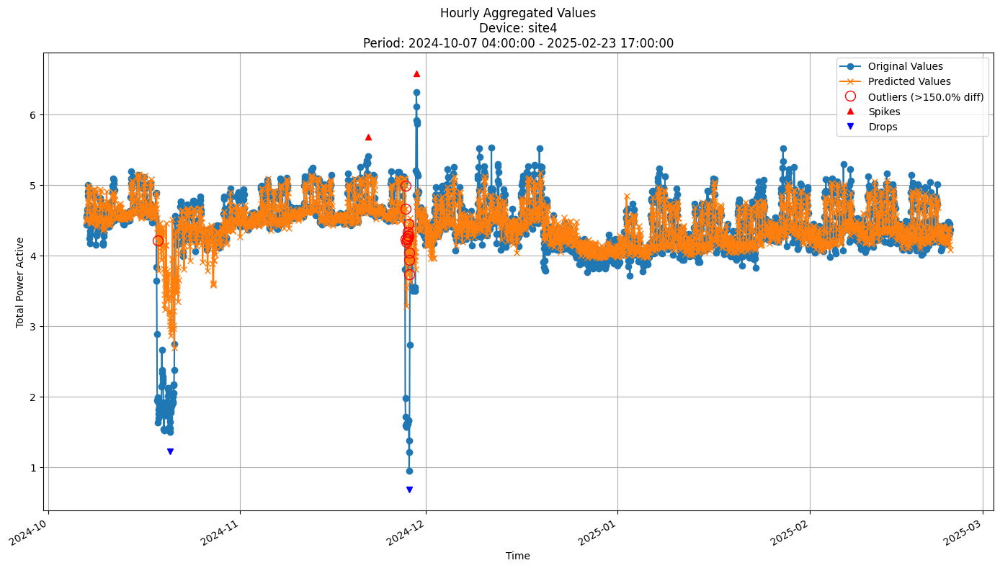


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3817
MAE: 0.1789
MAPE: 5.7381%

Directional Metrics:
Directional Accuracy: 52.1791%
First-Diff Correlation: 0.0916

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


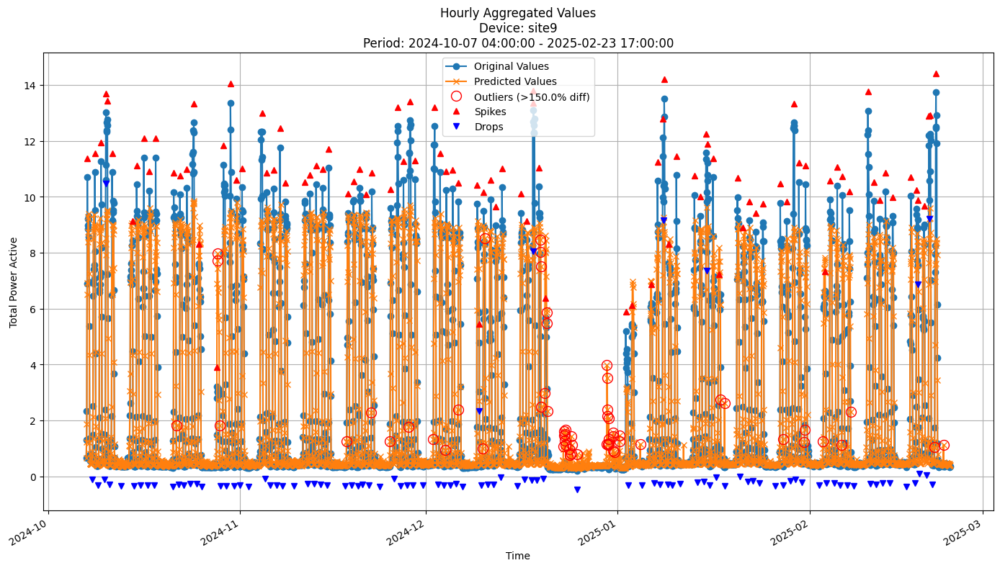


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.0550
MAE: 0.5059
MAPE: 25.5881%

Directional Metrics:
Directional Accuracy: 59.8209%
First-Diff Correlation: 0.6825

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0745
  Recall: 0.0707
  F1 Score: 0.0725
Drops:
  Precision: 0.0860
  Recall: 0.0816
  F1 Score: 0.0838

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2021
  Recall: 0.1919
  F1 Score: 0.1969
Drops:
  Precision: 0.2473
  Recall: 0.2347
  F1 Score: 0.2408


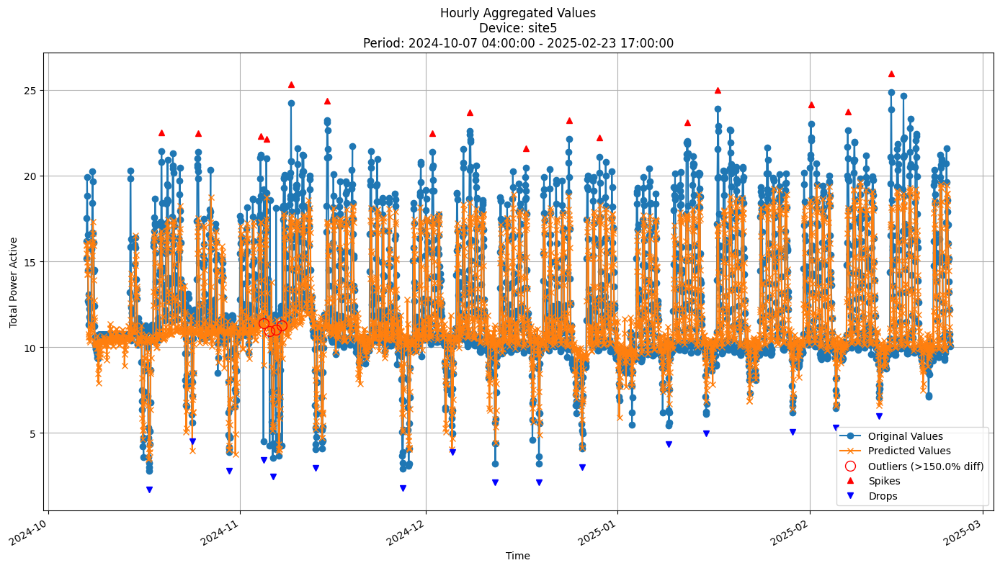


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.8636
MAE: 1.2608
MAPE: 9.8382%

Directional Metrics:
Directional Accuracy: 58.3881%
First-Diff Correlation: 0.3407

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0556
  Recall: 0.0625
  F1 Score: 0.0588
Drops:
  Precision: 0.1579
  Recall: 0.1875
  F1 Score: 0.1714

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1111
  Recall: 0.1250
  F1 Score: 0.1176
Drops:
  Precision: 0.4737
  Recall: 0.5625
  F1 Score: 0.5143


In [11]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [17]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

fodt = fastodt.FastODT
fodt_params = {
        "depth": 50,
        "grace_period": 0,
        "split_confidence": 0.005,
        "option": 'hf',
        "eagerness" : 1000,
        "grace_period_depth" : 0  # set to 1 to use only for first node, set to -1 to use for all nodes, set to N to use for N nodes
}

In [18]:
fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=fodt,
    model_params=fodt_params,
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3539
	MAE: 0.3248
	MAPE: 162.0440%

Directional Metrics:
	Directional Accuracy: 57.5261%
	First-Diff Correlation: 0.4368

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2500
		Recall: 0.0435
		F1: 0.0741
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Da

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3941
	MAE: 0.3787
	MAPE: 220.0773%

Directional Metrics:
	Directional Accuracy: 52.9061%
	First-Diff Correlation: 0.3754

Immediate Detection (delta=0):
	Spikes:
		Precision: 1.0000
		Recall: 0.0233
		F1: 0.0455
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.0233
		F1: 0.0455
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Da

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

[! WARNING !] No validation data for device site1 in split 23. Skipping.
[! WARNING !] No validation data for device site3 in split 23. Skipping.
Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 0.000053 MB
Metrics for Device: site8 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 7.4899
	MAE: 4.6263
	MAPE: 78.3891%

Directional Metrics:
	Directional Accuracy: 50.0745%
	First-Diff Correlation: 0.4724

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0476
		Recall: 0.0476
		F1: 0.0476
	Drops:
		Precision: 0.0526
		Recall: 0.0476
		F1: 0.0500

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.1

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

[! WARNING !] No validation data for device site1 in split 24. Skipping.
[! WARNING !] No validation data for device site3 in split 24. Skipping.
Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 0.000053 MB
Metrics for Device: site8 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 7.6770
	MAE: 4.5714
	MAPE: 56.7764%

Directional Metrics:
	Directional Accuracy: 50.9063%
	First-Diff Correlation: 0.5082

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0476
		Recall: 0.0400
		F1: 0.0435
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2

#### Results

In [19]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.3015 ± 0.0141
	MAE: 0.2759 ± 0.0152
	MAPE: 140.5728% ± 14.0081%

	Directional Metrics:
		Directional Accuracy: 54.5405% ± 1.9458%
		First-Diff Correlation: 0.4138 ± 0.0319

	Immediate Detection (delta=0):
		Spike Precision: 0.2323 ± 0.1001
		Spike Recall: 0.1331 ± 0.0357
		Spike F1: 0.1639 ± 0.0446
		Drop Precision: 0.0678 ± 0.0339
		Drop Recall: 0.0454 ± 0.0260
		Drop F1: 0.0535 ± 0.0284

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3614 ± 0.1251
		Spike Recall: 0.2157 ± 0.0668
		Spike F1: 0.2627 ± 0.0745
		Drop Precision: 0.1636 ± 0.0588
		Drop Recall: 0.1025 ± 0.0465
		Drop F1: 0.1231 ± 0.0497
Daily Metrics:
	RMSE: 6.7674 ± 0.3224
	MAE: 6.3391 ± 0.3866
	MAPE: 121.8814% ± 14.5480%

	Directional Metrics:
		Directional Accuracy: 68.2666% ± 4.8689%
		First-Diff Correlation: 0.3490 ± 0.1078

	Immediate Detection (delta=0):
	

```

Train period metrics:


==================================================
Aggregated Metrics Across Periods
==================================================
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 1.4286 ± 0.4411
	MAE: 0.4649 ± 0.0949
	MAPE: 154.1858% ± 12.7512%

	Directional Metrics:
		Directional Accuracy: 63.7949% ± 1.4450%
		First-Diff Correlation: 0.0459 ± 0.0963

	Immediate Detection (delta=0):
		Spike Precision: 0.0945 ± 0.0637
		Spike Recall: 0.1248 ± 0.0342
		Spike F1: 0.1023 ± 0.0492
		Drop Precision: 0.0928 ± 0.0243
		Drop Recall: 0.1472 ± 0.0543
		Drop F1: 0.1082 ± 0.0211

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2370 ± 0.1074
		Spike Recall: 0.3507 ± 0.0532
		Spike F1: 0.2679 ± 0.0703
		Drop Precision: 0.1830 ± 0.0423
		Drop Recall: 0.3002 ± 0.1367
		Drop F1: 0.2161 ± 0.0506
Daily Metrics:
	RMSE: 20.4400 ± 7.4693
	MAE: 10.7240 ± 2.2030
	MAPE: 140.4382% ± 15.5932%

	Directional Metrics:
		Directional Accuracy: 69.0647% ± 1.8056%
		First-Diff Correlation: 0.5645 ± 0.0631

	Immediate Detection (delta=0):
		Spike Precision: 0.3597 ± 0.1428
		Spike Recall: 0.6779 ± 0.2191
		Spike F1: 0.4554 ± 0.1511
		Drop Precision: 0.2963 ± 0.1443
		Drop Recall: 0.5238 ± 0.1866
		Drop F1: 0.3630 ± 0.1328

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4043 ± 0.1354
		Spike Recall: 0.7713 ± 0.2297
		Spike F1: 0.5155 ± 0.1490
		Drop Precision: 0.4329 ± 0.1644
		Drop Recall: 0.7762 ± 0.2140
		Drop F1: 0.5371 ± 0.1586
Weekly Metrics:
	RMSE: 113.7435 ± 37.9546
	MAE: 72.5625 ± 15.5612
	MAPE: 142.3324% ± 16.4446%
28_days Metrics:
	RMSE: 360.8309 ± 118.6854
	MAE: 263.8197 ± 64.2663
	MAPE: 149.4141% ± 21.0361%
==================================================
Device ID: site3
--------------------------------------------------
Hourly Metrics:
	RMSE: 11.5669 ± 1.4555
	MAE: 8.0340 ± 1.0846
	MAPE: 111.1159% ± 6.0388%

	Directional Metrics:
		Directional Accuracy: 62.6447% ± 3.8172%
		First-Diff Correlation: 0.5265 ± 0.0533

	Immediate Detection (delta=0):
		Spike Precision: 0.0630 ± 0.0472
		Spike Recall: 0.0105 ± 0.0087
		Spike F1: 0.0177 ± 0.0140
		Drop Precision: 0.1906 ± 0.1411
		Drop Recall: 0.0133 ± 0.0121
		Drop F1: 0.0218 ± 0.0153

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1596 ± 0.1153
		Spike Recall: 0.0262 ± 0.0204
		Spike F1: 0.0442 ± 0.0332
		Drop Precision: 0.4194 ± 0.2593
		Drop Recall: 0.0504 ± 0.0704
		Drop F1: 0.0571 ± 0.0369
Daily Metrics:
	RMSE: 172.6580 ± 26.0863
	MAE: 146.3021 ± 23.9399
	MAPE: 41.7586% ± 4.0344%

	Directional Metrics:
		Directional Accuracy: 81.5129% ± 2.2913%
		First-Diff Correlation: 0.8680 ± 0.0527

	Immediate Detection (delta=0):
		Spike Precision: 0.3788 ± 0.1361
		Spike Recall: 0.5379 ± 0.1611
		Spike F1: 0.4389 ± 0.1422
		Drop Precision: 0.5538 ± 0.1801
		Drop Recall: 0.7194 ± 0.1023
		Drop F1: 0.6031 ± 0.1125

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5900 ± 0.2319
		Spike Recall: 0.8119 ± 0.2027
		Spike F1: 0.6742 ± 0.2186
		Drop Precision: 0.6804 ± 0.1865
		Drop Recall: 0.8966 ± 0.1323
		Drop F1: 0.7489 ± 0.1365
Weekly Metrics:
	RMSE: 971.9025 ± 152.7558
	MAE: 902.1004 ± 139.8825
	MAPE: 33.8709% ± 3.7386%
28_days Metrics:
	RMSE: 3496.3959 ± 412.0541
	MAE: 3151.8350 ± 226.5504
	MAPE: 31.4738% ± 3.8223%
==================================================
Device ID: site4
--------------------------------------------------
Hourly Metrics:
	RMSE: 7.2047 ± 0.1088
	MAE: 5.8004 ± 0.0861
	MAPE: 122.7946% ± 6.2983%

	Directional Metrics:
		Directional Accuracy: 51.1547% ± 0.5179%
		First-Diff Correlation: 0.0186 ± 0.0173

	Immediate Detection (delta=0):
		Spike Precision: 0.0430 ± 0.0220
		Spike Recall: 0.0769 ± 0.0120
		Spike F1: 0.0537 ± 0.0183
		Drop Precision: 0.0219 ± 0.0096
		Drop Recall: 0.0463 ± 0.0214
		Drop F1: 0.0296 ± 0.0130

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2057 ± 0.0498
		Spike Recall: 0.3891 ± 0.0493
		Spike F1: 0.2640 ± 0.0395
		Drop Precision: 0.0536 ± 0.0238
		Drop Recall: 0.0945 ± 0.0143
		Drop F1: 0.0664 ± 0.0186
Daily Metrics:
	RMSE: 122.3920 ± 3.3864
	MAE: 113.0393 ± 4.2904
	MAPE: 101.4446% ± 6.2264%

	Directional Metrics:
		Directional Accuracy: 64.9284% ± 1.3102%
		First-Diff Correlation: 0.4384 ± 0.0827

	Immediate Detection (delta=0):
		Spike Precision: 0.0151 ± 0.0196
		Spike Recall: 0.1250 ± 0.1614
		Spike F1: 0.0270 ± 0.0350
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0221 ± 0.0227
		Spike Recall: 0.1875 ± 0.1943
		Spike F1: 0.0395 ± 0.0405
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Weekly Metrics:
	RMSE: 744.0829 ± 66.3055
	MAE: 688.2735 ± 105.1532
	MAPE: 93.2305% ± 10.0279%
28_days Metrics:
	RMSE: 2808.1318 ± 427.2894
	MAE: 2750.4929 ± 422.6597
	MAPE: 101.6742% ± 6.1800%
==================================================
Device ID: site5
--------------------------------------------------
Hourly Metrics:
	RMSE: 7.1001 ± 0.1762
	MAE: 5.7555 ± 0.1221
	MAPE: 66.2675% ± 8.1382%

	Directional Metrics:
		Directional Accuracy: 49.6081% ± 1.7725%
		First-Diff Correlation: -0.0996 ± 0.0138

	Immediate Detection (delta=0):
		Spike Precision: 0.0350 ± 0.0220
		Spike Recall: 0.0310 ± 0.0204
		Spike F1: 0.0329 ± 0.0211
		Drop Precision: 0.0128 ± 0.0095
		Drop Recall: 0.0108 ± 0.0076
		Drop F1: 0.0117 ± 0.0084

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0821 ± 0.0119
		Spike Recall: 0.0723 ± 0.0103
		Spike F1: 0.0769 ± 0.0109
		Drop Precision: 0.0287 ± 0.0171
		Drop Recall: 0.0246 ± 0.0142
		Drop F1: 0.0265 ± 0.0155
Daily Metrics:
	RMSE: 72.5536 ± 6.0504
	MAE: 63.1687 ± 4.2827
	MAPE: 27.2779% ± 1.6561%

	Directional Metrics:
		Directional Accuracy: 55.3416% ± 4.8641%
		First-Diff Correlation: 0.3503 ± 0.1151

	Immediate Detection (delta=0):
		Spike Precision: 0.0208 ± 0.0551
		Spike Recall: 0.0312 ± 0.0827
		Spike F1: 0.0250 ± 0.0661
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3750 ± 0.3975
		Spike Recall: 0.0878 ± 0.0838
		Spike F1: 0.1216 ± 0.1029
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Weekly Metrics:
	RMSE: 167.7174 ± 47.6658
	MAE: 145.0577 ± 39.8770
	MAPE: 15.7286% ± 6.2873%
28_days Metrics:
	RMSE: 567.2156 ± 260.0607
	MAE: 496.8963 ± 223.2519
	MAPE: 7.9982% ± 2.5192%
==================================================
Device ID: site8
--------------------------------------------------
Hourly Metrics:
	RMSE: 12.6180 ± 0.4301
	MAE: 9.3018 ± 0.2926
	MAPE: 170.1830% ± 4.8446%

	Directional Metrics:
		Directional Accuracy: 55.8814% ± 0.4535%
		First-Diff Correlation: 0.2770 ± 0.0194

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0675 ± 0.0323
		Drop Recall: 0.0441 ± 0.0232
		Drop F1: 0.0532 ± 0.0269

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.3221 ± 0.0573
		Drop Recall: 0.1984 ± 0.0158
		Drop F1: 0.2443 ± 0.0233
Daily Metrics:
	RMSE: 121.2843 ± 7.3768
	MAE: 107.5501 ± 5.9390
	MAPE: 83.3115% ± 9.1902%

	Directional Metrics:
		Directional Accuracy: 70.3931% ± 4.6669%
		First-Diff Correlation: 0.7882 ± 0.0525

	Immediate Detection (delta=0):
		Spike Precision: 0.0601 ± 0.0559
		Spike Recall: 0.1874 ± 0.3129
		Spike F1: 0.0764 ± 0.0691
		Drop Precision: 0.2129 ± 0.1830
		Drop Recall: 0.2998 ± 0.2383
		Drop F1: 0.2475 ± 0.2041

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2720 ± 0.1944
		Spike Recall: 0.4892 ± 0.3140
		Spike F1: 0.3243 ± 0.2143
		Drop Precision: 0.4358 ± 0.3483
		Drop Recall: 0.6250 ± 0.4841
		Drop F1: 0.5107 ± 0.3995
Weekly Metrics:
	RMSE: 367.8093 ± 70.2237
	MAE: 284.2988 ± 56.1231
	MAPE: 40.3974% ± 14.2109%
28_days Metrics:
	RMSE: 820.4173 ± 289.0154
	MAE: 742.9542 ± 275.4982
	MAPE: 14.3376% ± 12.4256%
==================================================
Device ID: site9
--------------------------------------------------
Hourly Metrics:
	RMSE: 5.7836 ± 0.1403
	MAE: 2.8282 ± 0.1197
	MAPE: 265.3842% ± 9.8812%

	Directional Metrics:
		Directional Accuracy: 56.1699% ± 0.9240%
		First-Diff Correlation: 0.2290 ± 0.0405

	Immediate Detection (delta=0):
		Spike Precision: 0.1096 ± 0.0110
		Spike Recall: 0.2695 ± 0.0391
		Spike F1: 0.1557 ± 0.0174
		Drop Precision: 0.0456 ± 0.0099
		Drop Recall: 0.1107 ± 0.0224
		Drop F1: 0.0646 ± 0.0137

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2966 ± 0.0195
		Spike Recall: 0.7280 ± 0.0769
		Spike F1: 0.4212 ± 0.0316
		Drop Precision: 0.1371 ± 0.0128
		Drop Recall: 0.3335 ± 0.0337
		Drop F1: 0.1942 ± 0.0180
Daily Metrics:
	RMSE: 75.9224 ± 2.2358
	MAE: 58.7399 ± 3.8585
	MAPE: 89.9029% ± 3.5175%

	Directional Metrics:
		Directional Accuracy: 71.6727% ± 2.3395%
		First-Diff Correlation: 0.8671 ± 0.0193

	Immediate Detection (delta=0):
		Spike Precision: 0.0789 ± 0.0587
		Spike Recall: 0.1904 ± 0.3103
		Spike F1: 0.0971 ± 0.0869
		Drop Precision: 0.3151 ± 0.2497
		Drop Recall: 0.3689 ± 0.2877
		Drop F1: 0.3389 ± 0.2658

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3344 ± 0.2253
		Spike Recall: 0.4891 ± 0.3131
		Spike F1: 0.3717 ± 0.2311
		Drop Precision: 0.4978 ± 0.3925
		Drop Recall: 0.5830 ± 0.4519
		Drop F1: 0.5353 ± 0.4173
Weekly Metrics:
	RMSE: 406.6172 ± 39.8134
	MAE: 358.5418 ± 62.1463
	MAPE: 89.8596% ± 5.4210%
28_days Metrics:
	RMSE: 1482.0490 ± 251.4957
	MAE: 1434.1671 ± 248.5852
	MAPE: 100.6348% ± 11.5976%
==================================================
Device ID: site2
--------------------------------------------------
Hourly Metrics:
	RMSE: 5.7677 ± 0.1537
	MAE: 2.8198 ± 0.1269
	MAPE: 264.2847% ± 10.9065%

	Directional Metrics:
		Directional Accuracy: 56.2055% ± 0.9262%
		First-Diff Correlation: 0.2297 ± 0.0402

	Immediate Detection (delta=0):
		Spike Precision: 0.1127 ± 0.0120
		Spike Recall: 0.2768 ± 0.0375
		Spike F1: 0.1601 ± 0.0180
		Drop Precision: 0.0461 ± 0.0103
		Drop Recall: 0.1117 ± 0.0227
		Drop F1: 0.0652 ± 0.0141

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2999 ± 0.0175
		Spike Recall: 0.7354 ± 0.0651
		Spike F1: 0.4257 ± 0.0269
		Drop Precision: 0.1375 ± 0.0142
		Drop Recall: 0.3344 ± 0.0349
		Drop F1: 0.1948 ± 0.0195
Daily Metrics:
	RMSE: 75.6948 ± 2.4162
	MAE: 58.5538 ± 4.0795
	MAPE: 89.5460% ± 3.8834%

	Directional Metrics:
		Directional Accuracy: 72.4540% ± 3.8659%
		First-Diff Correlation: 0.8664 ± 0.0205

	Immediate Detection (delta=0):
		Spike Precision: 0.0830 ± 0.0655
		Spike Recall: 0.1904 ± 0.3103
		Spike F1: 0.1030 ± 0.1002
		Drop Precision: 0.3151 ± 0.2497
		Drop Recall: 0.3689 ± 0.2877
		Drop F1: 0.3389 ± 0.2658

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3385 ± 0.2225
		Spike Recall: 0.4891 ± 0.3131
		Spike F1: 0.3777 ± 0.2294
		Drop Precision: 0.4978 ± 0.3925
		Drop Recall: 0.5830 ± 0.4519
		Drop F1: 0.5353 ± 0.4173
Weekly Metrics:
	RMSE: 405.4382 ± 41.4482
	MAE: 357.6252 ± 63.3554
	MAPE: 89.4626% ± 6.0151%
28_days Metrics:
	RMSE: 1478.1633 ± 256.4983
	MAE: 1430.5009 ± 253.4215
	MAPE: 100.3042% ± 11.5080%
==================================================

\Valid period metrics:


==================================================
Aggregated Metrics Across Periods
==================================================
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.9517 ± 1.3326
	MAE: 0.4789 ± 0.5493
	MAPE: 160.8027% ± 43.0824%

	Directional Metrics:
		Directional Accuracy: 59.4841% ± 3.0337%
		First-Diff Correlation: 0.1607 ± 0.1725

	Immediate Detection (delta=0):
		Spike Precision: 0.1808 ± 0.1957
		Spike Recall: 0.1208 ± 0.0885
		Spike F1: 0.1298 ± 0.1186
		Drop Precision: 0.0945 ± 0.0706
		Drop Recall: 0.0973 ± 0.0820
		Drop F1: 0.0828 ± 0.0591

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3351 ± 0.2361
		Spike Recall: 0.2752 ± 0.1159
		Spike F1: 0.2588 ± 0.1325
		Drop Precision: 0.1761 ± 0.1247
		Drop Recall: 0.2038 ± 0.1785
		Drop F1: 0.1574 ± 0.1118
Daily Metrics:
	RMSE: 14.5838 ± 20.9681
	MAE: 10.6832 ± 12.1654
	MAPE: 143.0981% ± 40.2923%

	Directional Metrics:
		Directional Accuracy: 67.8649% ± 7.5689%
		First-Diff Correlation: 0.5882 ± 0.1056

	Immediate Detection (delta=0):
		Spike Precision: 0.2475 ± 0.2703
		Spike Recall: 0.4333 ± 0.4453
		Spike F1: 0.3010 ± 0.3107
		Drop Precision: 0.2375 ± 0.3701
		Drop Recall: 0.2917 ± 0.4278
		Drop F1: 0.2433 ± 0.3616

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4058 ± 0.3076
		Spike Recall: 0.6417 ± 0.4258
		Spike F1: 0.4679 ± 0.3155
		Drop Precision: 0.3125 ± 0.3978
		Drop Recall: 0.3917 ± 0.4633
		Drop F1: 0.3267 ± 0.3943
Weekly Metrics:
	RMSE: 78.4506 ± 101.4114
	MAE: 61.9615 ± 70.3464
	MAPE: 142.7509% ± 41.8130%
28_days Metrics:
	RMSE: 219.1738 ± 248.5095
	MAE: 157.4884 ± 175.2153
	MAPE: 148.2634% ± 48.2707%
==================================================
Device ID: site3
--------------------------------------------------
Hourly Metrics:
	RMSE: 10.9856 ± 1.6665
	MAE: 7.5816 ± 1.2908
	MAPE: 123.2313% ± 29.9137%

	Directional Metrics:
		Directional Accuracy: 58.0760% ± 3.3480%
		First-Diff Correlation: 0.4170 ± 0.0758

	Immediate Detection (delta=0):
		Spike Precision: 0.0217 ± 0.0669
		Spike Recall: 0.0058 ± 0.0214
		Spike F1: 0.0088 ± 0.0316
		Drop Precision: 0.1696 ± 0.3068
		Drop Recall: 0.0339 ± 0.0653
		Drop F1: 0.0464 ± 0.0842

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0476 ± 0.1023
		Spike Recall: 0.0284 ± 0.0531
		Spike F1: 0.0279 ± 0.0534
		Drop Precision: 0.2625 ± 0.3603
		Drop Recall: 0.0738 ± 0.1239
		Drop F1: 0.0955 ± 0.1512
Daily Metrics:
	RMSE: 153.2790 ± 37.8610
	MAE: 126.7289 ± 33.1132
	MAPE: 45.8233% ± 17.1199%

	Directional Metrics:
		Directional Accuracy: 76.1568% ± 8.3840%
		First-Diff Correlation: 0.8191 ± 0.0897

	Immediate Detection (delta=0):
		Spike Precision: 0.2167 ± 0.2986
		Spike Recall: 0.2667 ± 0.3704
		Spike F1: 0.2333 ± 0.3187
		Drop Precision: 0.4000 ± 0.3590
		Drop Recall: 0.5250 ± 0.4225
		Drop F1: 0.4367 ± 0.3616

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4083 ± 0.3435
		Spike Recall: 0.5417 ± 0.4212
		Spike F1: 0.4517 ± 0.3547
		Drop Precision: 0.4667 ± 0.3712
		Drop Recall: 0.6167 ± 0.4349
		Drop F1: 0.5133 ± 0.3764
Weekly Metrics:
	RMSE: 753.5966 ± 244.0231
	MAE: 636.7292 ± 231.9271
	MAPE: 31.3748% ± 11.5298%
28_days Metrics:
	RMSE: 2199.5025 ± 868.6285
	MAE: 1593.7725 ± 649.8763
	MAPE: 30.4113% ± 17.6259%
==================================================
Device ID: site4
--------------------------------------------------
Hourly Metrics:
	RMSE: 7.3202 ± 0.1849
	MAE: 5.8934 ± 0.1437
	MAPE: 130.5138% ± 12.8996%

	Directional Metrics:
		Directional Accuracy: 49.9876% ± 2.2315%
		First-Diff Correlation: -0.0185 ± 0.0428

	Immediate Detection (delta=0):
		Spike Precision: 0.0576 ± 0.0415
		Spike Recall: 0.0491 ± 0.0325
		Spike F1: 0.0502 ± 0.0319
		Drop Precision: 0.0447 ± 0.0635
		Drop Recall: 0.0380 ± 0.0393
		Drop F1: 0.0385 ± 0.0440

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2645 ± 0.1393
		Spike Recall: 0.2468 ± 0.1333
		Spike F1: 0.2463 ± 0.1269
		Drop Precision: 0.1092 ± 0.1266
		Drop Recall: 0.0902 ± 0.0738
		Drop F1: 0.0945 ± 0.0882
Daily Metrics:
	RMSE: 123.3938 ± 6.2612
	MAE: 114.1434 ± 5.9808
	MAPE: 107.0105% ± 12.3918%

	Directional Metrics:
		Directional Accuracy: 70.9160% ± 6.8781%
		First-Diff Correlation: 0.5723 ± 0.0343

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Weekly Metrics:
	RMSE: 746.8908 ± 35.8703
	MAE: 678.1720 ± 42.4480
	MAPE: 93.9671% ± 9.5943%
28_days Metrics:
	RMSE: 2439.0257 ± 244.2624
	MAE: 1836.6557 ± 451.5047
	MAPE: 71.8009% ± 14.0903%
==================================================
Device ID: site5
--------------------------------------------------
Hourly Metrics:
	RMSE: 7.6519 ± 0.5666
	MAE: 6.1892 ± 0.4665
	MAPE: 55.9432% ± 6.9875%

	Directional Metrics:
		Directional Accuracy: 47.0407% ± 4.8812%
		First-Diff Correlation: -0.1117 ± 0.0473

	Immediate Detection (delta=0):
		Spike Precision: 0.0191 ± 0.0246
		Spike Recall: 0.0163 ± 0.0213
		Spike F1: 0.0175 ± 0.0228
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0697 ± 0.0499
		Spike Recall: 0.0590 ± 0.0431
		Spike F1: 0.0638 ± 0.0461
		Drop Precision: 0.0132 ± 0.0348
		Drop Recall: 0.0104 ± 0.0276
		Drop F1: 0.0116 ± 0.0308
Daily Metrics:
	RMSE: 84.4285 ± 12.0095
	MAE: 70.3333 ± 7.4046
	MAPE: 26.7400% ± 2.6748%

	Directional Metrics:
		Directional Accuracy: 51.5542% ± 7.2265%
		First-Diff Correlation: 0.4274 ± 0.1041

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1250 ± 0.3307
		Spike Recall: 0.0312 ± 0.0827
		Spike F1: 0.0500 ± 0.1323
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Weekly Metrics:
	RMSE: 245.3329 ± 119.7072
	MAE: 223.5658 ± 118.4510
	MAPE: 22.9895% ± 4.4954%
28_days Metrics:
	RMSE: 745.4015 ± 528.2215
	MAE: 607.3523 ± 508.3497
	MAPE: 38.1472% ± 8.2102%
==================================================
Device ID: site8
--------------------------------------------------
Hourly Metrics:
	RMSE: 11.8501 ± 1.2181
	MAE: 8.9456 ± 0.8876
	MAPE: 161.3096% ± 7.3006%

	Directional Metrics:
		Directional Accuracy: 55.5691% ± 1.7971%
		First-Diff Correlation: 0.3082 ± 0.0356

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0847 ± 0.0671
		Drop Recall: 0.0479 ± 0.0434
		Drop F1: 0.0595 ± 0.0501

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0078 ± 0.0207
		Spike Recall: 0.0050 ± 0.0132
		Spike F1: 0.0061 ± 0.0161
		Drop Precision: 0.2937 ± 0.1193
		Drop Recall: 0.1697 ± 0.0764
		Drop F1: 0.2115 ± 0.0897
Daily Metrics:
	RMSE: 105.6844 ± 12.5365
	MAE: 91.1066 ± 14.3190
	MAPE: 68.6242% ± 9.6434%

	Directional Metrics:
		Directional Accuracy: 68.1878% ± 8.7447%
		First-Diff Correlation: 0.7325 ± 0.0905

	Immediate Detection (delta=0):
		Spike Precision: 0.1562 ± 0.1583
		Spike Recall: 0.1562 ± 0.1583
		Spike F1: 0.1548 ± 0.1557
		Drop Precision: 0.3750 ± 0.3511
		Drop Recall: 0.3750 ± 0.3511
		Drop F1: 0.3750 ± 0.3511

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4792 ± 0.2818
		Spike Recall: 0.5000 ± 0.3227
		Spike F1: 0.4810 ± 0.2868
		Drop Precision: 0.7292 ± 0.3721
		Drop Recall: 0.8750 ± 0.3307
		Drop F1: 0.7708 ± 0.3430
Weekly Metrics:
	RMSE: 298.9891 ± 140.2942
	MAE: 216.2730 ± 99.1015
	MAPE: 20.5737% ± 14.3802%
28_days Metrics:
	RMSE: 586.5825 ± 239.4246
	MAE: 428.8414 ± 160.5970
	MAPE: 13.2441% ± 7.7204%
==================================================
Device ID: site9
--------------------------------------------------
Hourly Metrics:
	RMSE: 5.9176 ± 0.3311
	MAE: 2.9218 ± 0.3076
	MAPE: 270.3083% ± 29.7465%

	Directional Metrics:
		Directional Accuracy: 55.0079% ± 3.1764%
		First-Diff Correlation: 0.1970 ± 0.1029

	Immediate Detection (delta=0):
		Spike Precision: 0.0943 ± 0.0350
		Spike Recall: 0.2279 ± 0.0972
		Spike F1: 0.1329 ± 0.0510
		Drop Precision: 0.0478 ± 0.0201
		Drop Recall: 0.1129 ± 0.0423
		Drop F1: 0.0669 ± 0.0270

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2623 ± 0.0637
		Spike Recall: 0.6345 ± 0.1876
		Spike F1: 0.3698 ± 0.0940
		Drop Precision: 0.1384 ± 0.0325
		Drop Recall: 0.3349 ± 0.0842
		Drop F1: 0.1949 ± 0.0439
Daily Metrics:
	RMSE: 76.0067 ± 5.0255
	MAE: 60.2040 ± 6.6322
	MAPE: 91.4623% ± 7.9597%

	Directional Metrics:
		Directional Accuracy: 68.6508% ± 7.1786%
		First-Diff Correlation: 0.8693 ± 0.0353

	Immediate Detection (delta=0):
		Spike Precision: 0.1667 ± 0.2357
		Spike Recall: 0.1667 ± 0.2357
		Spike F1: 0.1667 ± 0.2357
		Drop Precision: 0.3333 ± 0.4410
		Drop Recall: 0.3333 ± 0.4410
		Drop F1: 0.3333 ± 0.4410

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4792 ± 0.2818
		Spike Recall: 0.4375 ± 0.2627
		Spike F1: 0.4554 ± 0.2687
		Drop Precision: 0.6250 ± 0.4841
		Drop Recall: 0.6250 ± 0.4841
		Drop F1: 0.6250 ± 0.4841
Weekly Metrics:
	RMSE: 408.1824 ± 27.3570
	MAE: 358.2268 ± 45.4032
	MAPE: 90.0797% ± 5.7593%
28_days Metrics:
	RMSE: 1290.6594 ± 202.6912
	MAE: 974.7000 ± 286.3010
	MAPE: 75.2432% ± 9.8562%
==================================================
Device ID: site2
--------------------------------------------------
Hourly Metrics:
	RMSE: 5.9014 ± 0.3367
	MAE: 2.9144 ± 0.3107
	MAPE: 269.3024% ± 29.6465%

	Directional Metrics:
		Directional Accuracy: 54.9561% ± 2.9216%
		First-Diff Correlation: 0.1992 ± 0.1018

	Immediate Detection (delta=0):
		Spike Precision: 0.0955 ± 0.0365
		Spike Recall: 0.2311 ± 0.0971
		Spike F1: 0.1346 ± 0.0525
		Drop Precision: 0.0502 ± 0.0211
		Drop Recall: 0.1198 ± 0.0458
		Drop F1: 0.0705 ± 0.0286

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2646 ± 0.0641
		Spike Recall: 0.6404 ± 0.1805
		Spike F1: 0.3731 ± 0.0930
		Drop Precision: 0.1413 ± 0.0312
		Drop Recall: 0.3439 ± 0.0789
		Drop F1: 0.1994 ± 0.0412
Daily Metrics:
	RMSE: 75.7461 ± 5.1066
	MAE: 59.9825 ± 6.7047
	MAPE: 91.0894% ± 7.7876%

	Directional Metrics:
		Directional Accuracy: 68.6508% ± 7.1786%
		First-Diff Correlation: 0.8689 ± 0.0361

	Immediate Detection (delta=0):
		Spike Precision: 0.1667 ± 0.2357
		Spike Recall: 0.1667 ± 0.2357
		Spike F1: 0.1667 ± 0.2357
		Drop Precision: 0.3333 ± 0.4410
		Drop Recall: 0.3333 ± 0.4410
		Drop F1: 0.3333 ± 0.4410

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4792 ± 0.2818
		Spike Recall: 0.4375 ± 0.2627
		Spike F1: 0.4554 ± 0.2687
		Drop Precision: 0.6250 ± 0.4841
		Drop Recall: 0.6250 ± 0.4841
		Drop F1: 0.6250 ± 0.4841
Weekly Metrics:
	RMSE: 406.7281 ± 27.7785
	MAE: 356.9030 ± 45.6577
	MAPE: 89.7187% ± 5.6834%
28_days Metrics:
	RMSE: 1285.8742 ± 202.9780
	MAE: 971.0458 ± 285.3396
	MAPE: 74.9596% ± 9.8430%
==================================================
```

#### Training plots

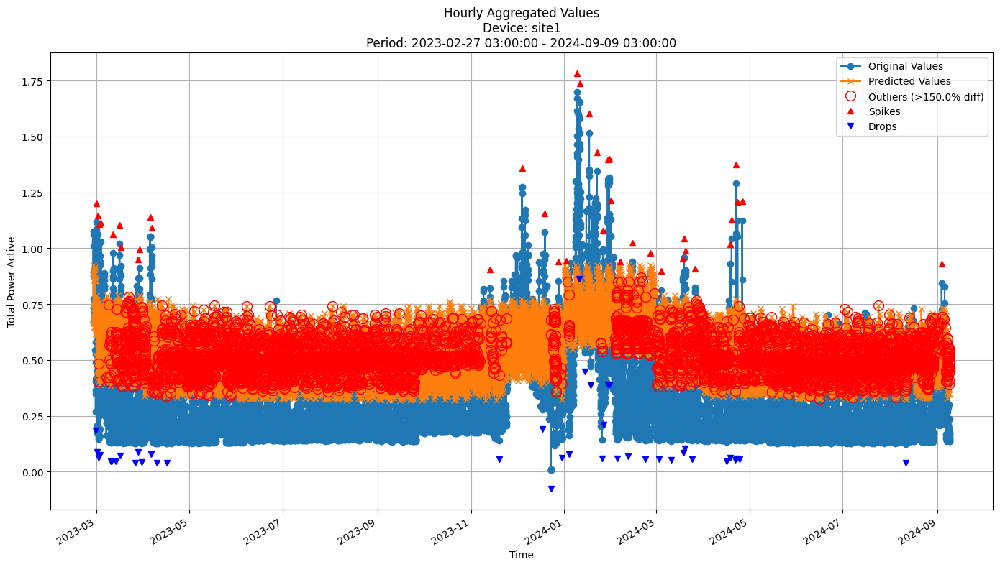


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2879
MAE: 0.2635
MAPE: 132.9879%

Directional Metrics:
Directional Accuracy: 55.8524%
First-Diff Correlation: 0.3735

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


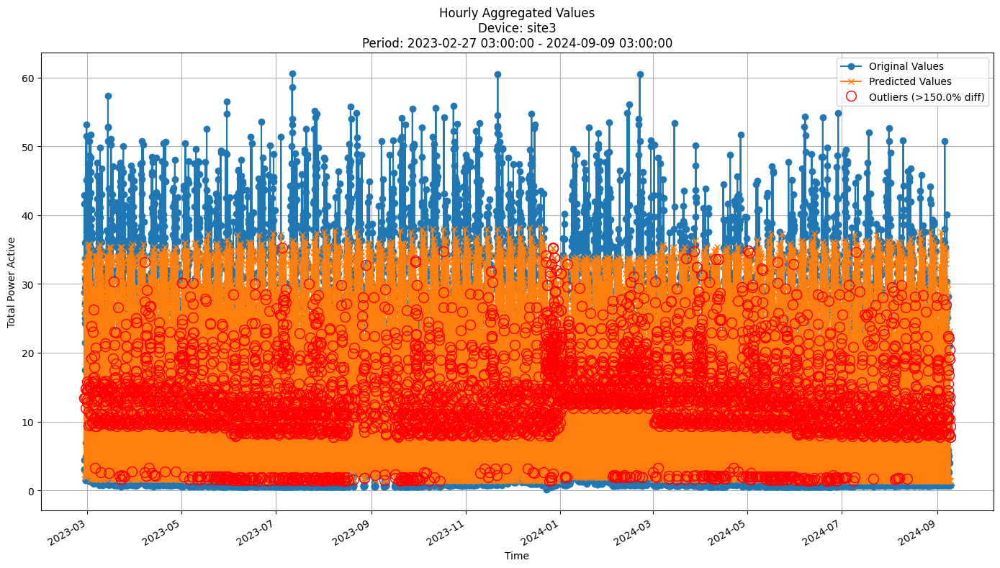


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 9.7668
MAE: 7.9468
MAPE: 384.9668%

Directional Metrics:
Directional Accuracy: 56.2319%
First-Diff Correlation: 0.3808

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


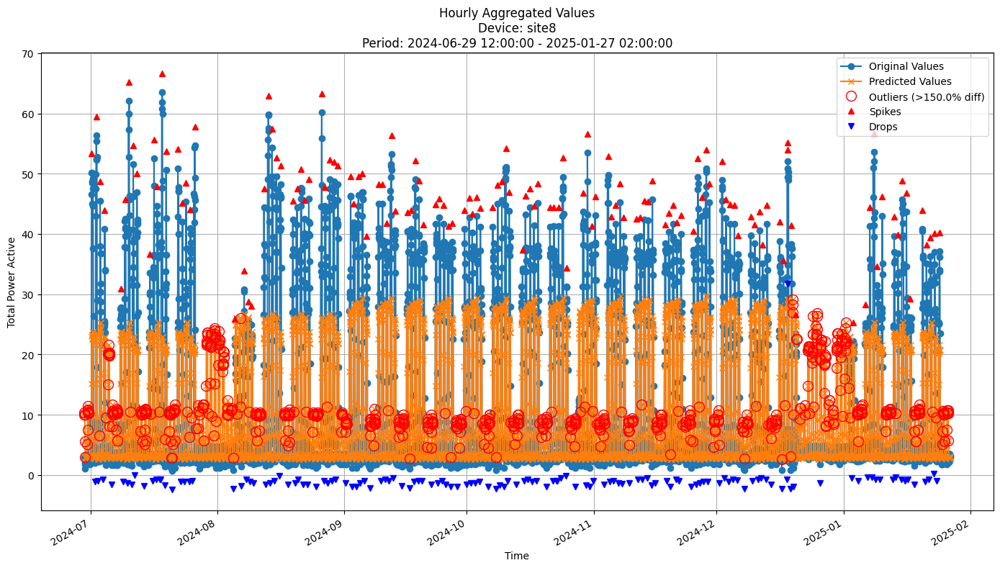


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.7312
MAE: 4.6628
MAPE: 68.3834%

Directional Metrics:
Directional Accuracy: 53.4751%
First-Diff Correlation: 0.5720

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


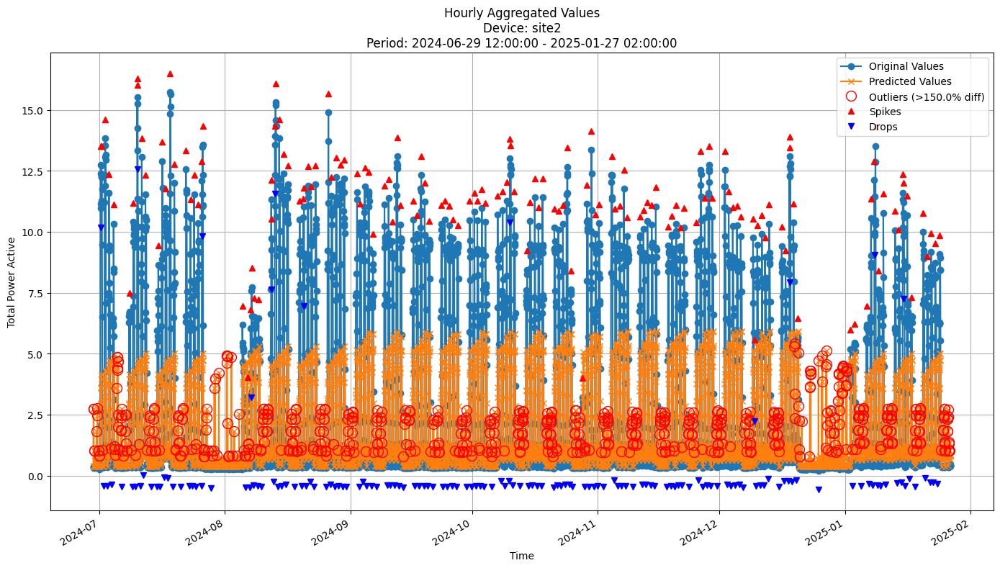


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.4380
MAE: 1.4439
MAPE: 99.4401%

Directional Metrics:
Directional Accuracy: 57.3538%
First-Diff Correlation: 0.5808

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0930
  Recall: 0.0541
  F1 Score: 0.0684
Drops:
  Precision: 0.0964
  Recall: 0.0541
  F1 Score: 0.0693

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2791
  Recall: 0.1622
  F1 Score: 0.2051
Drops:
  Precision: 0.1807
  Recall: 0.1014
  F1 Score: 0.1299


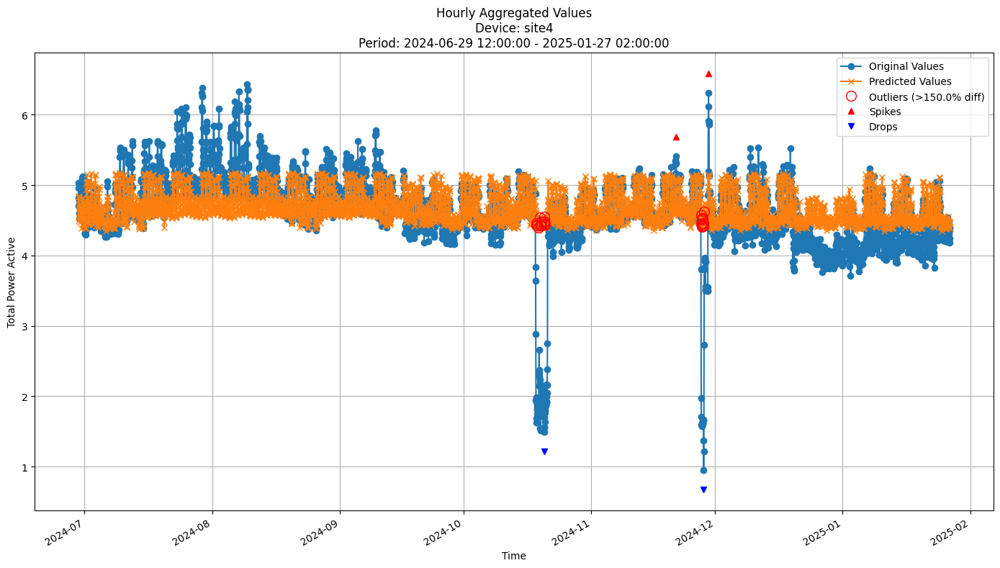


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4488
MAE: 0.2556
MAPE: 7.0846%

Directional Metrics:
Directional Accuracy: 53.9279%
First-Diff Correlation: 0.2123

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


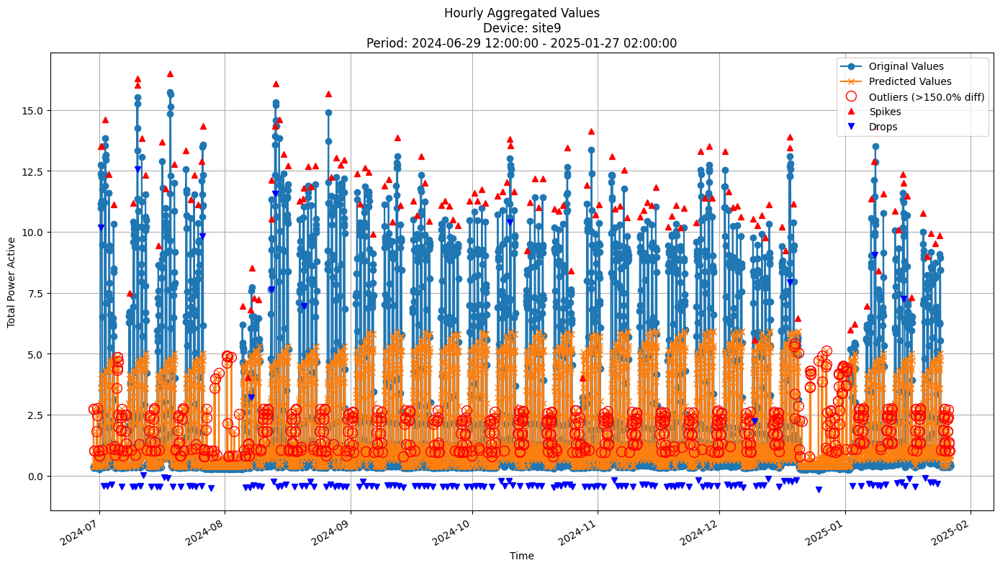


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.4380
MAE: 1.4439
MAPE: 99.4401%

Directional Metrics:
Directional Accuracy: 57.3538%
First-Diff Correlation: 0.5808

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0930
  Recall: 0.0541
  F1 Score: 0.0684
Drops:
  Precision: 0.0964
  Recall: 0.0541
  F1 Score: 0.0693

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2791
  Recall: 0.1622
  F1 Score: 0.2051
Drops:
  Precision: 0.1807
  Recall: 0.1014
  F1 Score: 0.1299


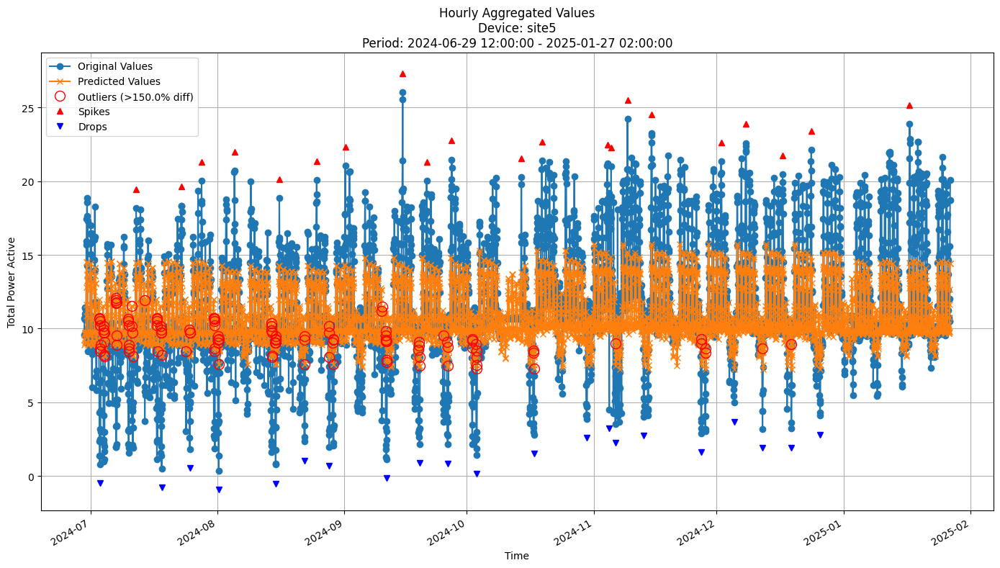


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.7629
MAE: 1.9924
MAPE: 24.2052%

Directional Metrics:
Directional Accuracy: 57.7476%
First-Diff Correlation: 0.4288

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0476
  Recall: 0.0476
  F1 Score: 0.0476
Drops:
  Precision: 0.1429
  Recall: 0.1429
  F1 Score: 0.1429

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0476
  Recall: 0.0476
  F1 Score: 0.0476
Drops:
  Precision: 0.2381
  Recall: 0.2381
  F1 Score: 0.2381


In [20]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

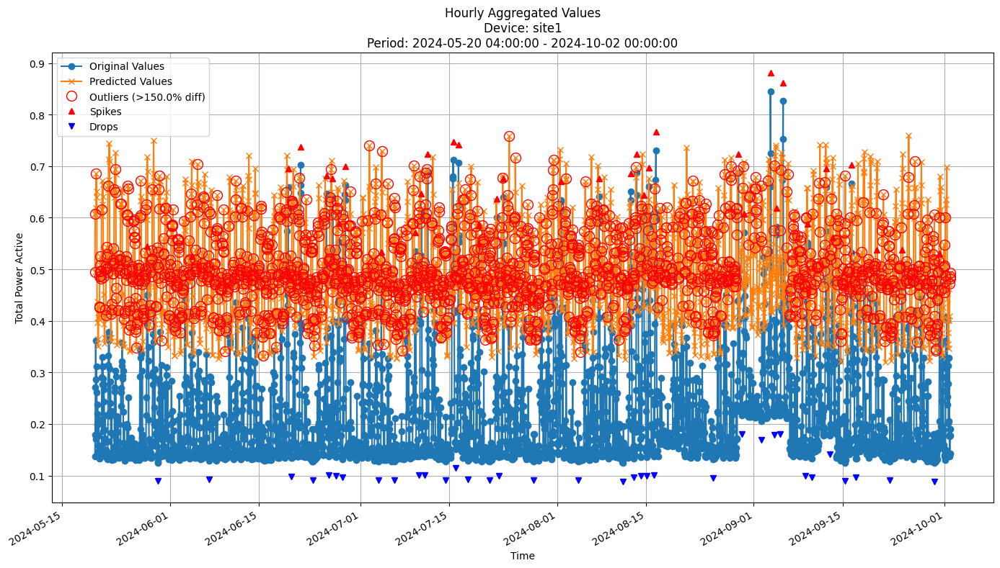


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3035
MAE: 0.2861
MAPE: 162.7110%

Directional Metrics:
Directional Accuracy: 53.3684%
First-Diff Correlation: 0.2551

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


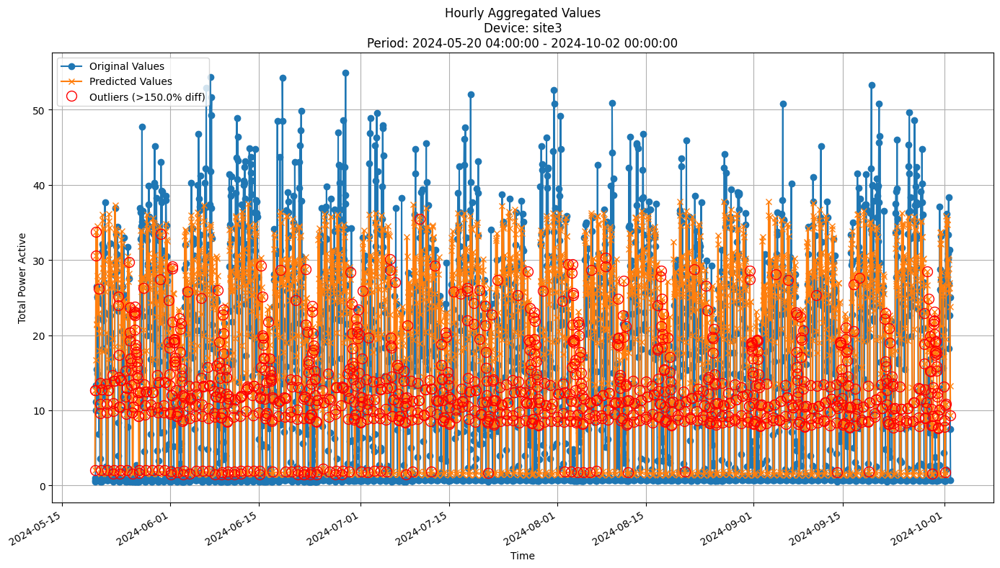


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 9.3960
MAE: 7.7618
MAPE: 381.8834%

Directional Metrics:
Directional Accuracy: 52.7194%
First-Diff Correlation: 0.3652

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


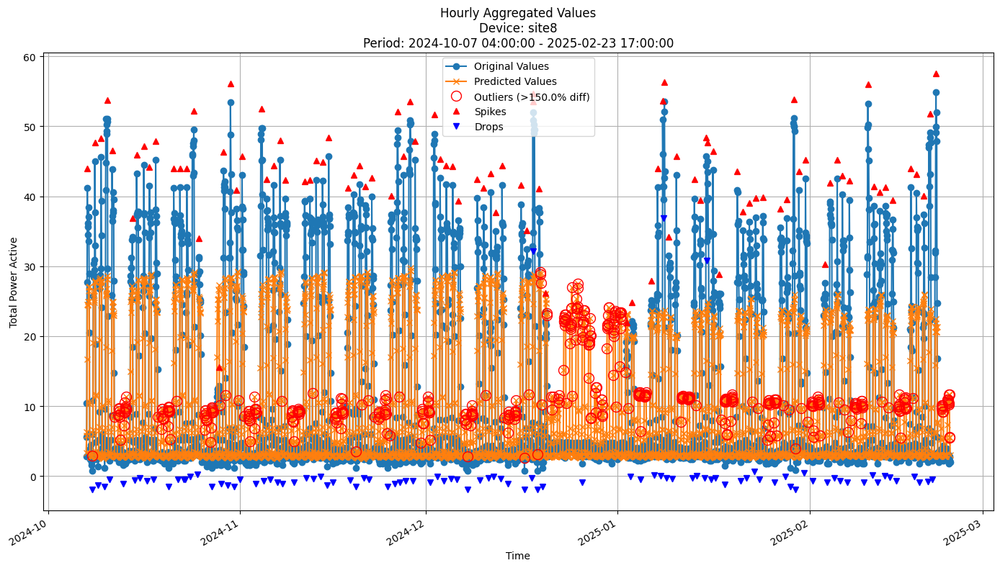


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.2529
MAE: 4.4416
MAPE: 65.7490%

Directional Metrics:
Directional Accuracy: 51.4925%
First-Diff Correlation: 0.4955

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


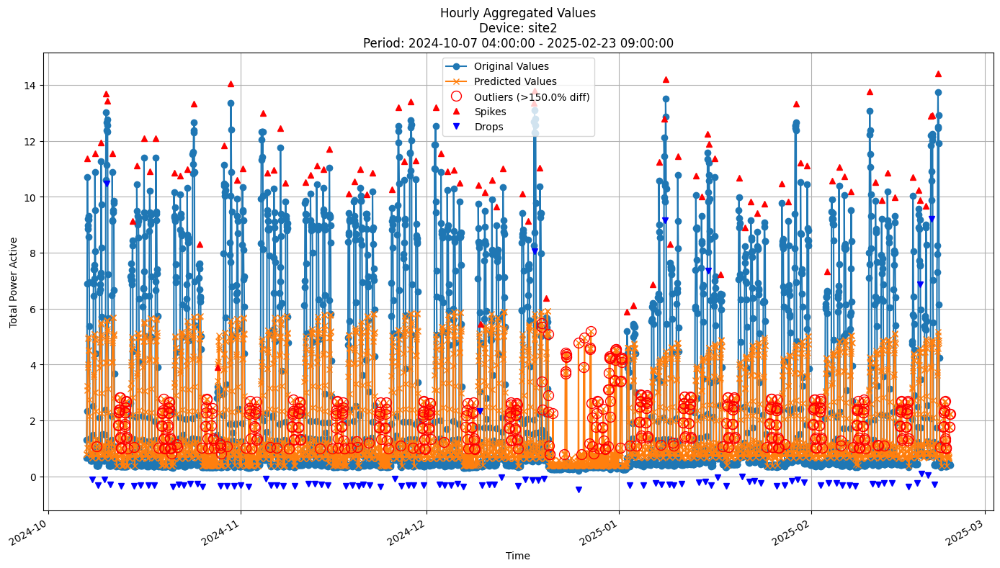


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.2831
MAE: 1.4145
MAPE: 105.5681%

Directional Metrics:
Directional Accuracy: 61.0712%
First-Diff Correlation: 0.5920

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1087
  Recall: 0.1010
  F1 Score: 0.1047
Drops:
  Precision: 0.0110
  Recall: 0.0102
  F1 Score: 0.0106

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2826
  Recall: 0.2626
  F1 Score: 0.2723
Drops:
  Precision: 0.1758
  Recall: 0.1633
  F1 Score: 0.1693


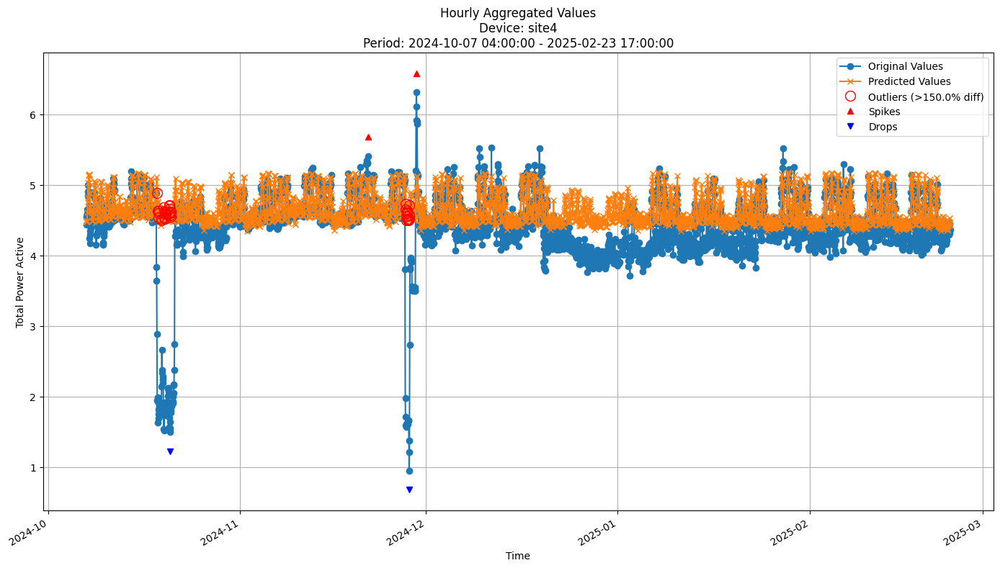


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.5314
MAE: 0.2925
MAPE: 9.1257%

Directional Metrics:
Directional Accuracy: 54.2985%
First-Diff Correlation: 0.1229

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


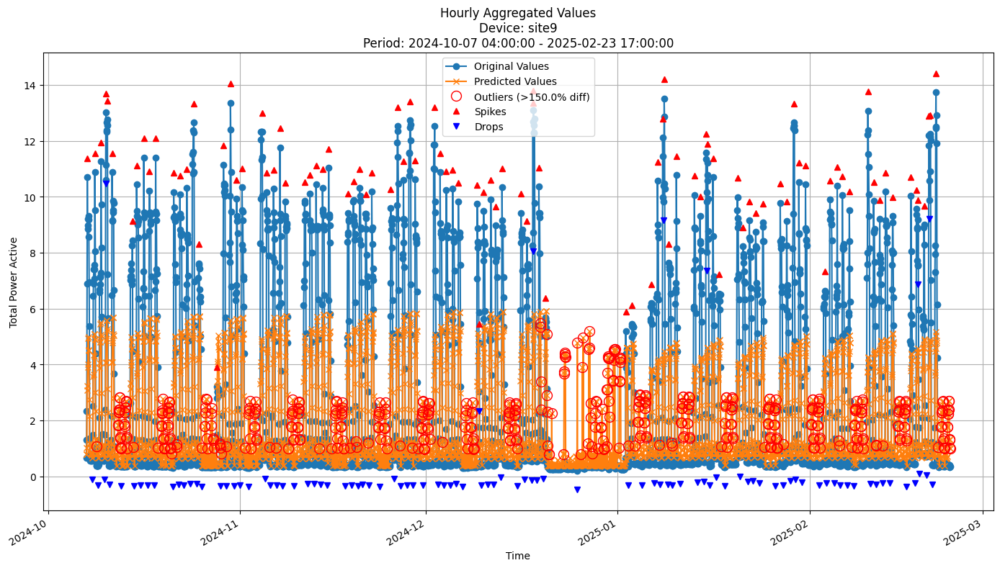


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.2817
MAE: 1.4146
MAPE: 106.2676%

Directional Metrics:
Directional Accuracy: 61.0746%
First-Diff Correlation: 0.5917

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1087
  Recall: 0.1010
  F1 Score: 0.1047
Drops:
  Precision: 0.0110
  Recall: 0.0102
  F1 Score: 0.0106

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2826
  Recall: 0.2626
  F1 Score: 0.2723
Drops:
  Precision: 0.1758
  Recall: 0.1633
  F1 Score: 0.1693


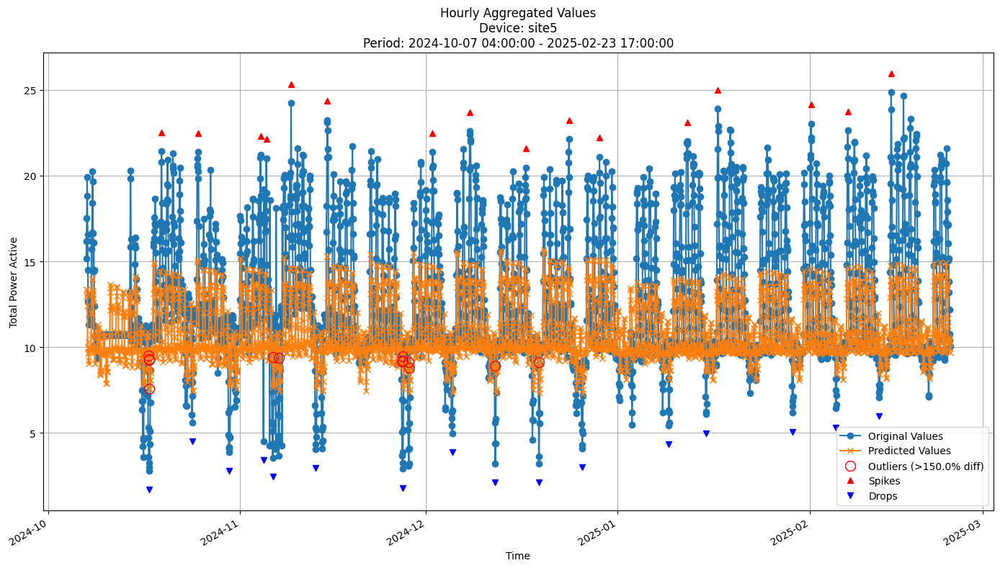


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 3.2372
MAE: 2.3835
MAPE: 18.2929%

Directional Metrics:
Directional Accuracy: 58.4776%
First-Diff Correlation: 0.3757

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0556
  Recall: 0.0625
  F1 Score: 0.0588
Drops:
  Precision: 0.0526
  Recall: 0.0625
  F1 Score: 0.0571

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0556
  Recall: 0.0625
  F1 Score: 0.0588
Drops:
  Precision: 0.1053
  Recall: 0.1250
  F1 Score: 0.1143


In [21]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [22]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf = ARFRegressorFODT
arf_params = {
    "n_models": 20,
    "aggregation_method": "mean",
    "grace_period": 0,  # by default works for all leaves
    "max_depth": 100,
    "delta": 0.005,  # split confidence
    "tau": 0.01,  # break ties
    "seed": 42,
    "max_feature": 0.7,  # maximum feature ratio for each model
    "eagerness": 200
}

In [24]:
arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf,
    model_params=arf_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1135
	MAE: 0.0913
	MAPE: 39.2295%

Directional Metrics:
	Directional Accuracy: 59.3145%
	First-Diff Correlation: 0.3037

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1000
		Recall: 0.0870
		F1: 0.0930
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5000
		Recall: 0.4348
		F1: 0.4651
	Drops:
		Precision: 0.4211
		Recall: 0.3636
		F1: 0.3902
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0695
	MAE: 0.0600
	MAPE: 35.0072%

Directional Metrics:
	Directional Accuracy: 48.2861%
	First-Diff Correlation: 0.0151

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0455
		Recall: 0.0233
		F1: 0.0308
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.1364
		Recall: 0.0698
		F1: 0.0923
	Drops:
		Precision: 0.0952
		Recall: 0.0435
		F1: 0.0597
--------------------------------------------------
Dai

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

[! WARNING !] No validation data for device site1 in split 23. Skipping.
[! WARNING !] No validation data for device site3 in split 23. Skipping.
Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 0.000053 MB
Metrics for Device: site8 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 8.0579
	MAE: 4.6002
	MAPE: 51.1698%

Directional Metrics:
	Directional Accuracy: 53.8003%
	First-Diff Correlation: 0.4361

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1667
		Recall: 0.1429
		F1: 0.1538
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

[! WARNING !] No validation data for device site1 in split 24. Skipping.
[! WARNING !] No validation data for device site3 in split 24. Skipping.
Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 0.000053 MB
Metrics for Device: site8 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 8.3544
	MAE: 5.0781
	MAPE: 59.0748%

Directional Metrics:
	Directional Accuracy: 60.8761%
	First-Diff Correlation: 0.4150

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0870
		Recall: 0.0800
		F1: 0.0833
	Drops:
		Precision: 0.0455
		Recall: 0.0417
		F1: 0.0435

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3

#### Results

In [25]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.1682 ± 0.0390
	MAE: 0.1167 ± 0.0448
	MAPE: 43.6991% ± 28.0440%

	Directional Metrics:
		Directional Accuracy: 53.5101% ± 3.8838%
		First-Diff Correlation: 0.2075 ± 0.1116

	Immediate Detection (delta=0):
		Spike Precision: 0.1368 ± 0.0822
		Spike Recall: 0.0961 ± 0.0642
		Spike F1: 0.1091 ± 0.0634
		Drop Precision: 0.0513 ± 0.0263
		Drop Recall: 0.0351 ± 0.0195
		Drop F1: 0.0406 ± 0.0209

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3932 ± 0.0921
		Spike Recall: 0.3063 ± 0.1687
		Spike F1: 0.3302 ± 0.1137
		Drop Precision: 0.1836 ± 0.0465
		Drop Recall: 0.1327 ± 0.0523
		Drop F1: 0.1489 ± 0.0423
Daily Metrics:
	RMSE: 3.2936 ± 1.0633
	MAE: 2.2231 ± 1.1582
	MAPE: 31.3845% ± 25.6163%

	Directional Metrics:
		Directional Accuracy: 85.1135% ± 4.2029%
		First-Diff Correlation: 0.6455 ± 0.1358

	Immediate Detection (delta=0):
		S

#### Training plots

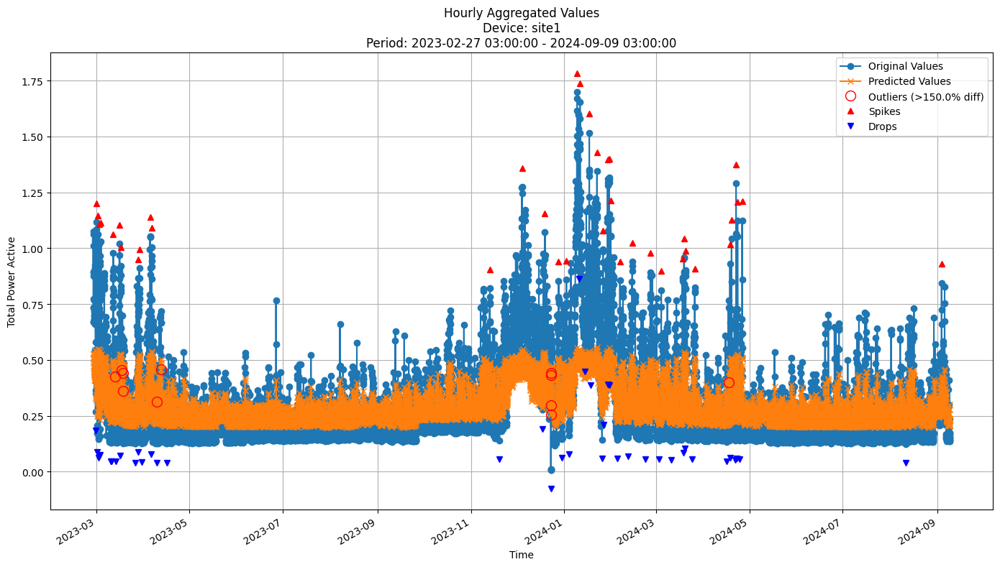


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1385
MAE: 0.0958
MAPE: 36.5775%

Directional Metrics:
Directional Accuracy: 51.9830%
First-Diff Correlation: 0.0911

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


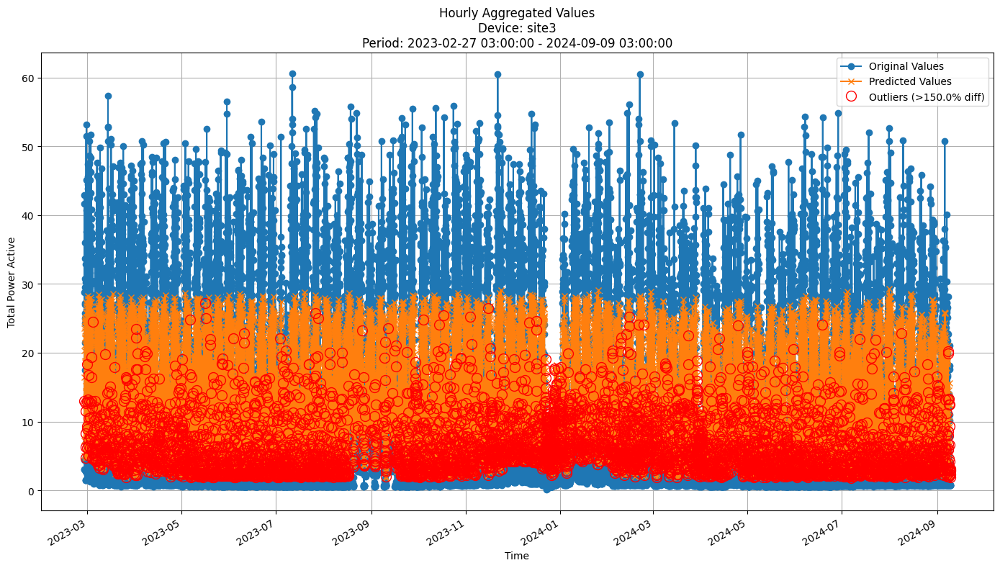


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 8.8256
MAE: 6.7867
MAPE: 209.6173%

Directional Metrics:
Directional Accuracy: 55.3687%
First-Diff Correlation: 0.3324

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


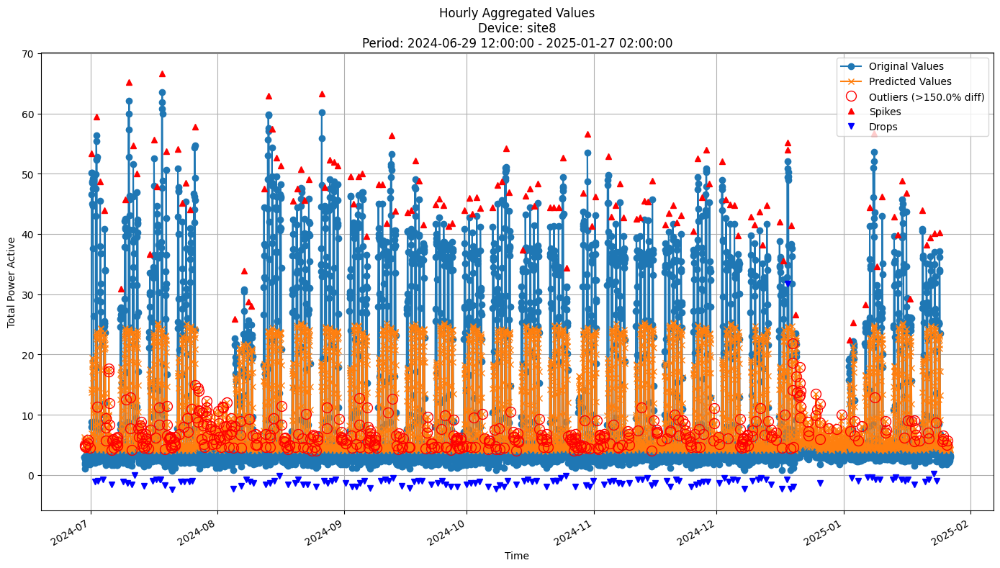


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 8.6972
MAE: 5.3792
MAPE: 68.6037%

Directional Metrics:
Directional Accuracy: 60.5828%
First-Diff Correlation: 0.5797

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0652
  Recall: 0.0667
  F1 Score: 0.0659
Drops:
  Precision: 0.0876
  Recall: 0.0882
  F1 Score: 0.0879

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2319
  Recall: 0.2370
  F1 Score: 0.2344
Drops:
  Precision: 0.2190
  Recall: 0.2206
  F1 Score: 0.2198


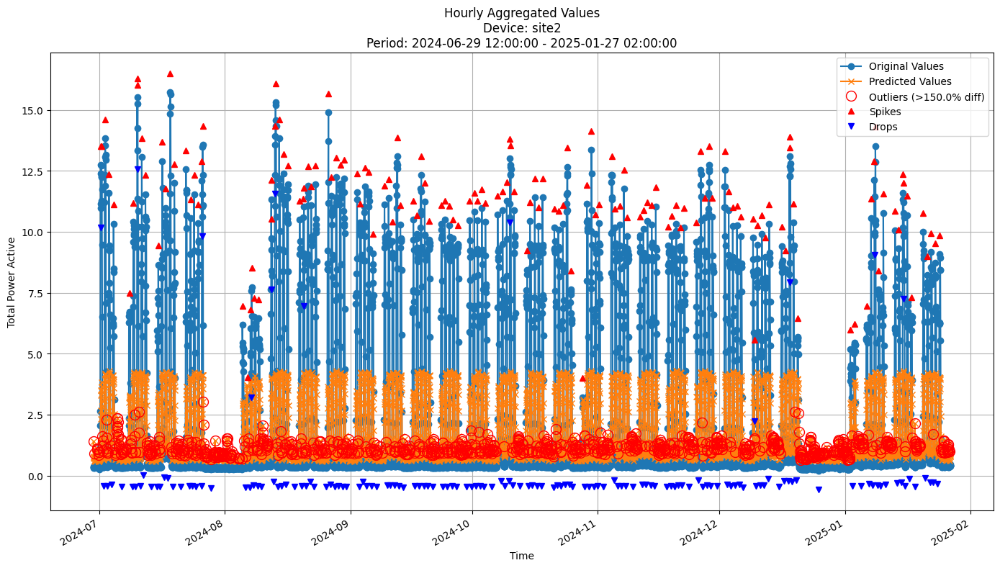


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.7112
MAE: 1.6115
MAPE: 99.0636%

Directional Metrics:
Directional Accuracy: 61.4294%
First-Diff Correlation: 0.5963

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1031
  Recall: 0.0676
  F1 Score: 0.0816
Drops:
  Precision: 0.0938
  Recall: 0.0608
  F1 Score: 0.0738

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3402
  Recall: 0.2230
  F1 Score: 0.2694
Drops:
  Precision: 0.2083
  Recall: 0.1351
  F1 Score: 0.1639


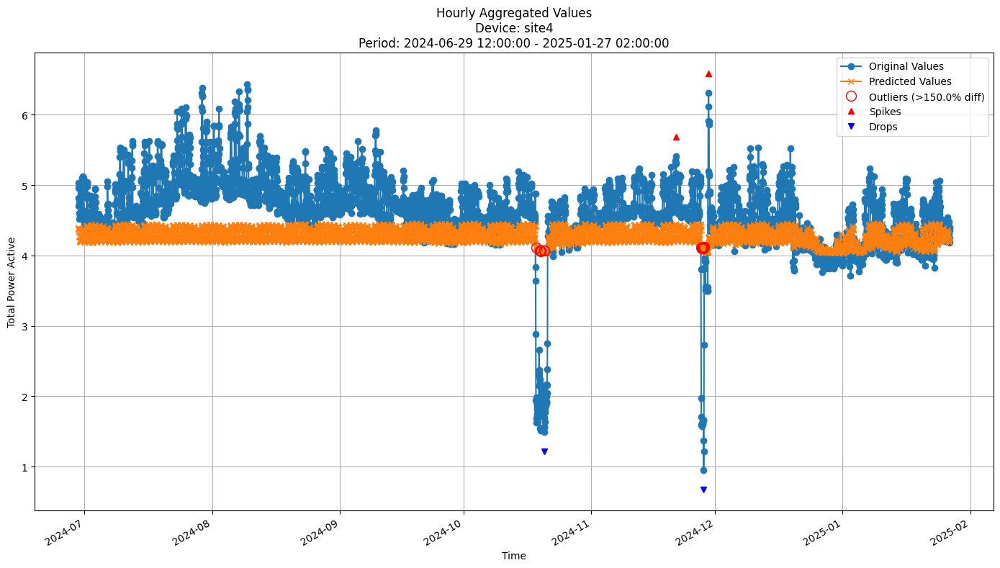


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.5787
MAE: 0.4325
MAPE: 10.2214%

Directional Metrics:
Directional Accuracy: 56.4087%
First-Diff Correlation: 0.3173

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


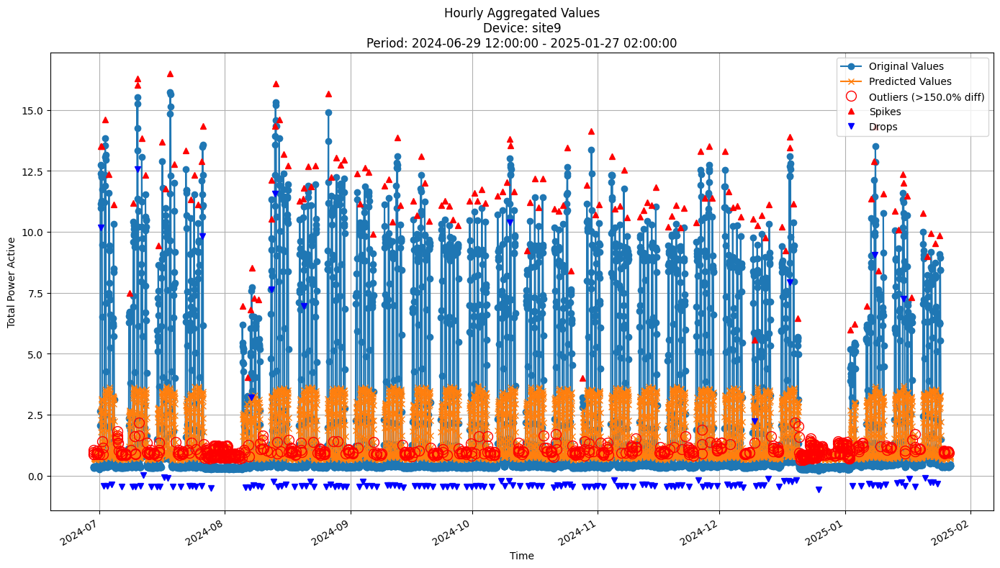


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.9771
MAE: 1.7244
MAPE: 92.7442%

Directional Metrics:
Directional Accuracy: 62.7289%
First-Diff Correlation: 0.6420

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0956
  Recall: 0.0878
  F1 Score: 0.0915
Drops:
  Precision: 0.0963
  Recall: 0.0878
  F1 Score: 0.0919

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2868
  Recall: 0.2635
  F1 Score: 0.2746
Drops:
  Precision: 0.3111
  Recall: 0.2838
  F1 Score: 0.2968


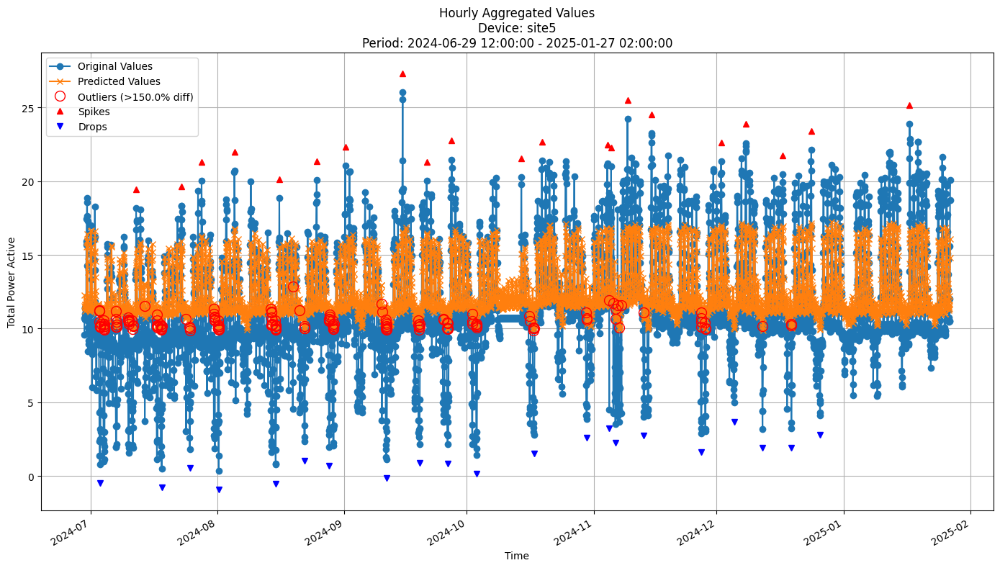


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.7610
MAE: 2.1458
MAPE: 29.6688%

Directional Metrics:
Directional Accuracy: 60.6615%
First-Diff Correlation: 0.2490

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0833
  Recall: 0.0952
  F1 Score: 0.0889
Drops:
  Precision: 0.1200
  Recall: 0.1429
  F1 Score: 0.1304

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1667
  Recall: 0.1905
  F1 Score: 0.1778
Drops:
  Precision: 0.3600
  Recall: 0.4286
  F1 Score: 0.3913


In [26]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

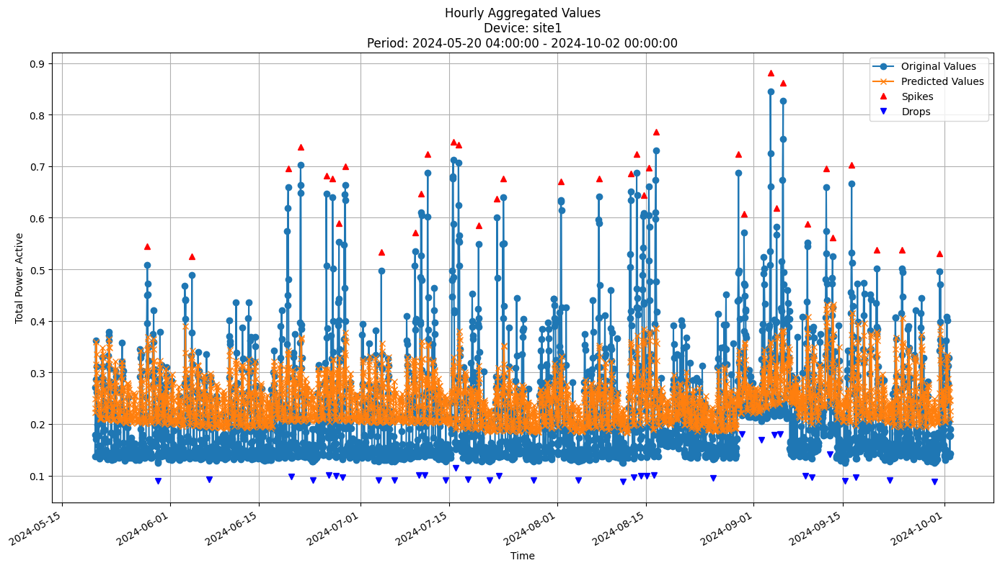


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0874
MAE: 0.0701
MAPE: 36.3706%

Directional Metrics:
Directional Accuracy: 52.8121%
First-Diff Correlation: 0.1165

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


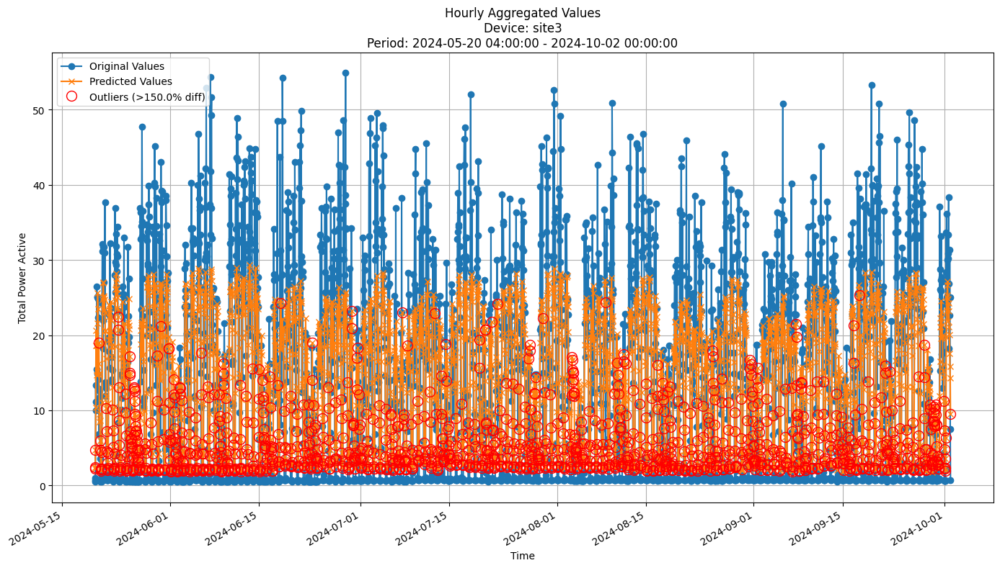


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 8.1575
MAE: 6.1771
MAPE: 204.1193%

Directional Metrics:
Directional Accuracy: 53.8628%
First-Diff Correlation: 0.3146

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


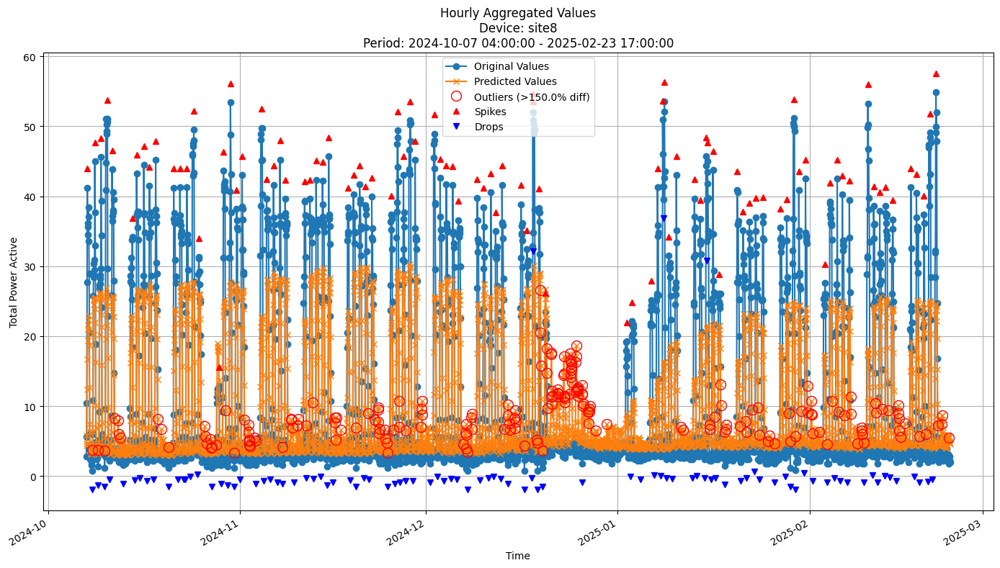


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.2987
MAE: 4.3789
MAPE: 54.6923%

Directional Metrics:
Directional Accuracy: 57.9403%
First-Diff Correlation: 0.5741

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1125
  Recall: 0.0947
  F1 Score: 0.1029
Drops:
  Precision: 0.0759
  Recall: 0.0632
  F1 Score: 0.0690

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2125
  Recall: 0.1789
  F1 Score: 0.1943
Drops:
  Precision: 0.2025
  Recall: 0.1684
  F1 Score: 0.1839


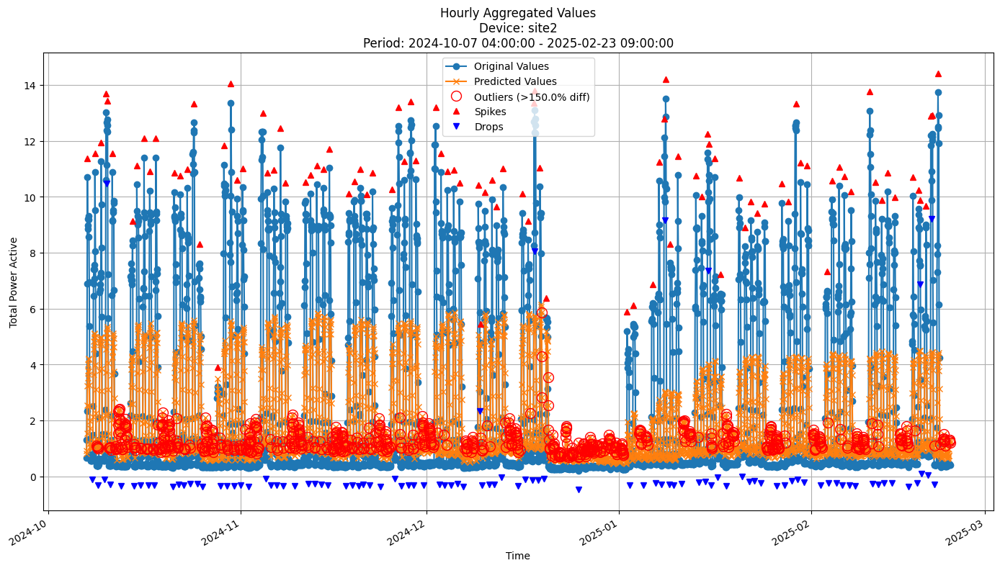


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.2956
MAE: 1.4461
MAPE: 104.2472%

Directional Metrics:
Directional Accuracy: 62.4177%
First-Diff Correlation: 0.6185

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0820
  Recall: 0.0505
  F1 Score: 0.0625
Drops:
  Precision: 0.0500
  Recall: 0.0306
  F1 Score: 0.0380

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1311
  Recall: 0.0808
  F1 Score: 0.1000
Drops:
  Precision: 0.2333
  Recall: 0.1429
  F1 Score: 0.1772


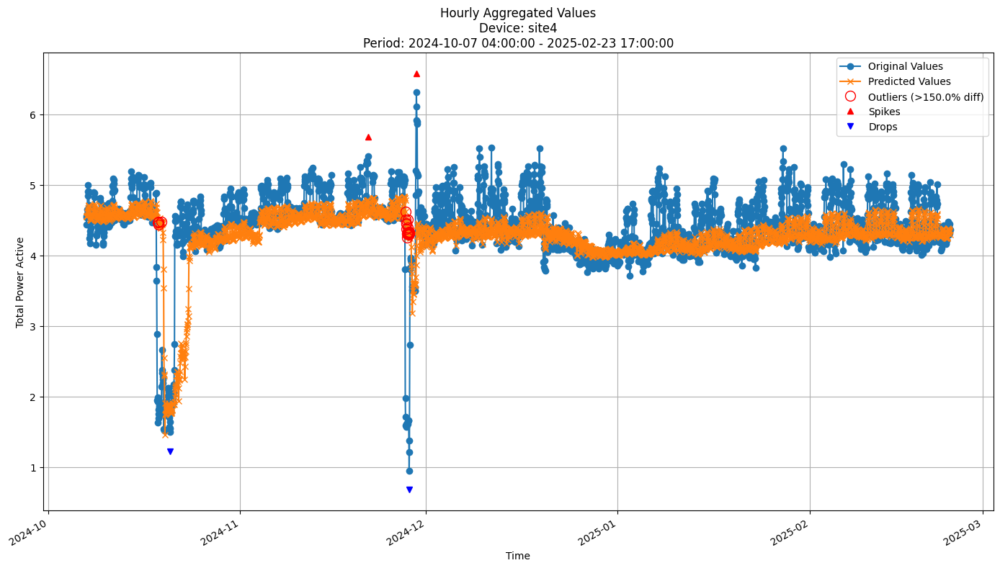


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4632
MAE: 0.2410
MAPE: 6.5527%

Directional Metrics:
Directional Accuracy: 53.7910%
First-Diff Correlation: 0.1236

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


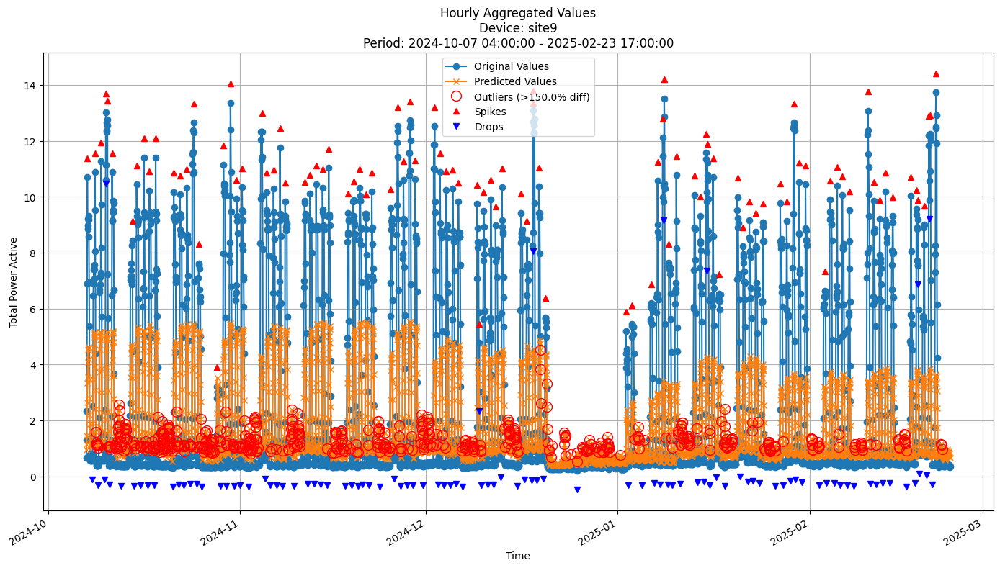


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.3987
MAE: 1.4534
MAPE: 91.3765%

Directional Metrics:
Directional Accuracy: 62.4776%
First-Diff Correlation: 0.6321

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1364
  Recall: 0.0606
  F1 Score: 0.0839
Drops:
  Precision: 0.0465
  Recall: 0.0204
  F1 Score: 0.0284

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1591
  Recall: 0.0707
  F1 Score: 0.0979
Drops:
  Precision: 0.1628
  Recall: 0.0714
  F1 Score: 0.0993


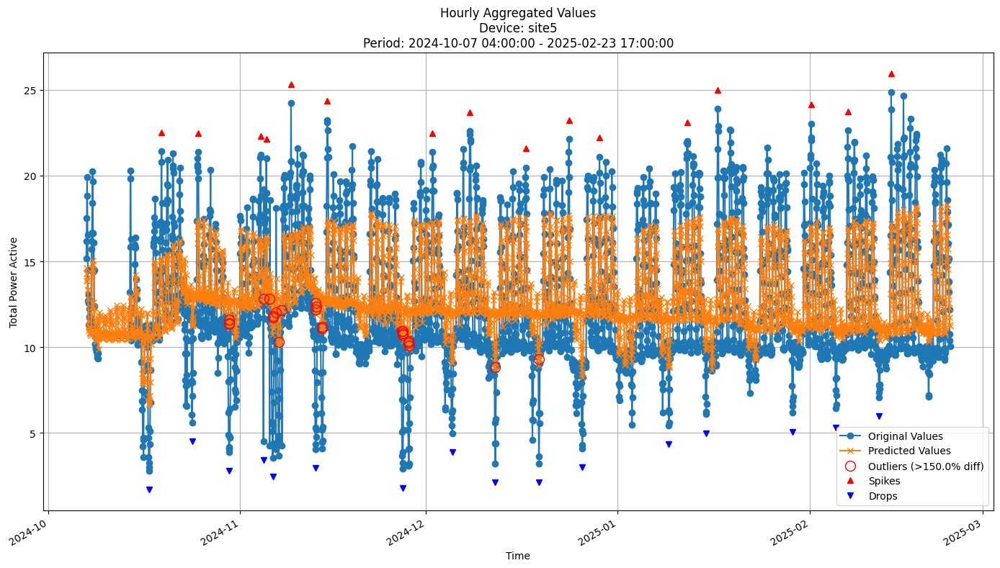


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.3716
MAE: 1.9107
MAPE: 17.7122%

Directional Metrics:
Directional Accuracy: 63.3731%
First-Diff Correlation: 0.3493

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [27]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [28]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:

# FastODT params
depth = 50
grace_period = 0
split_confidence_hf = 0.01
option = "hf"
max_features = 1.0
eagerness = 1000
learning_rate = 0.5
grace_period_depth = -1 # set to 1 to use only for first node, set to -1 to use for all nodes, set to N to use for N nodes

incb = IncubationBoost
incb_params = {
    "baseLearner": fastodt.FastODT,
    "length": 100,
    "learning_rate": 0.5,
    "incubationMode": "DEFAULT",
    "verbose": False,
    "baseLearnerOptions": (depth, grace_period, split_confidence_hf, option, max_features, eagerness, grace_period_depth),
}


In [29]:
incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=incb, 
    model_params=incb_params,
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1689
	MAE: 0.1127
	MAPE: 35.0730%

Directional Metrics:
	Directional Accuracy: 61.6990%
	First-Diff Correlation: 0.3116

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2000
		Recall: 0.0435
		F1: 0.0714
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.4000
		Recall: 0.0870
		F1: 0.1429
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0705
	MAE: 0.0578
	MAPE: 33.0841%

Directional Metrics:
	Directional Accuracy: 60.2086%
	First-Diff Correlation: 0.2525

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2308
		Recall: 0.0698
		F1: 0.1071
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6154
		Recall: 0.1860
		F1: 0.2857
	Drops:
		Precision: 0.0769
		Recall: 0.0217
		F1: 0.0339
--------------------------------------------------
Dai

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

[! WARNING !] No validation data for device site1 in split 23. Skipping.
[! WARNING !] No validation data for device site3 in split 23. Skipping.
Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 0.000053 MB
Metrics for Device: site8 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 9.2596
	MAE: 5.7199
	MAPE: 63.4154%

Directional Metrics:
	Directional Accuracy: 55.1416%
	First-Diff Correlation: 0.5920

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1071
		Recall: 0.1429
		F1: 0.1224
	Drops:
		Precision: 0.0370
		Recall: 0.0476
		F1: 0.0417

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

[! WARNING !] No validation data for device site1 in split 24. Skipping.
[! WARNING !] No validation data for device site3 in split 24. Skipping.
Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 0.000053 MB
Metrics for Device: site8 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 10.8636
	MAE: 6.4631
	MAPE: 50.2480%

Directional Metrics:
	Directional Accuracy: 57.7039%
	First-Diff Correlation: 0.6614

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1071
		Recall: 0.1200
		F1: 0.1132
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.

#### Results

In [30]:
print("\n\nTrain period metrics:")
incb_all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
incb_all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.1883 ± 0.0380
	MAE: 0.1156 ± 0.0296
	MAPE: 30.3780% ± 4.4389%

	Directional Metrics:
		Directional Accuracy: 60.5035% ± 1.9322%
		First-Diff Correlation: 0.4026 ± 0.0117

	Immediate Detection (delta=0):
		Spike Precision: 0.2099 ± 0.0579
		Spike Recall: 0.2228 ± 0.0451
		Spike F1: 0.2091 ± 0.0394
		Drop Precision: 0.0996 ± 0.0296
		Drop Recall: 0.1104 ± 0.0389
		Drop F1: 0.1016 ± 0.0273

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3672 ± 0.1306
		Spike Recall: 0.3839 ± 0.0694
		Spike F1: 0.3629 ± 0.0797
		Drop Precision: 0.2398 ± 0.0711
		Drop Recall: 0.2479 ± 0.0727
		Drop F1: 0.2341 ± 0.0577
Daily Metrics:
	RMSE: 3.9168 ± 0.9296
	MAE: 2.3788 ± 0.7305
	MAPE: 24.1278% ± 5.2297%

	Directional Metrics:
		Directional Accuracy: 75.0124% ± 6.1448%
		First-Diff Correlation: 0.6321 ± 0.1506

	Immediate Detection (delta=0):
		Spi

#### Train plots

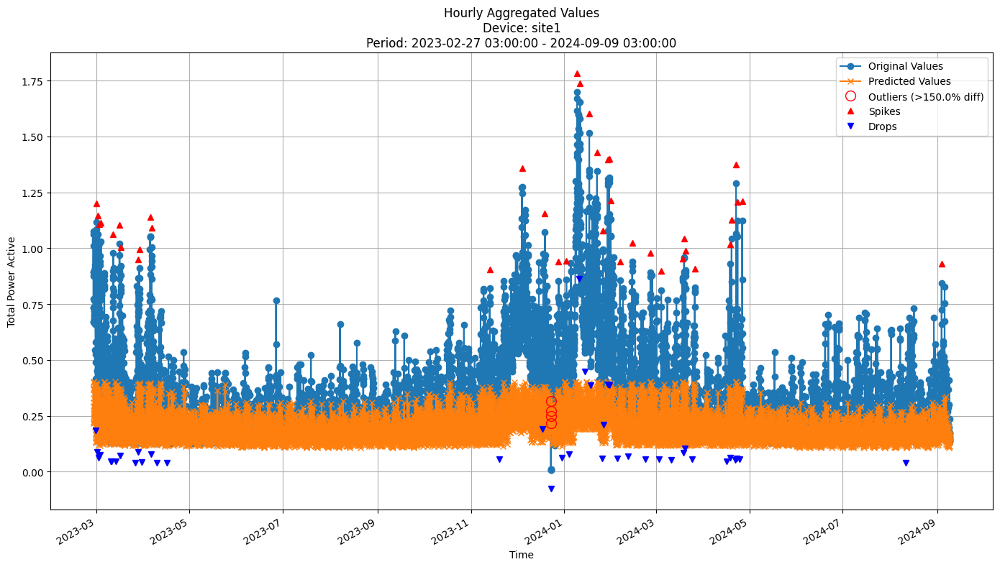


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1959
MAE: 0.1162
MAPE: 29.5271%

Directional Metrics:
Directional Accuracy: 61.6266%
First-Diff Correlation: 0.3848

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


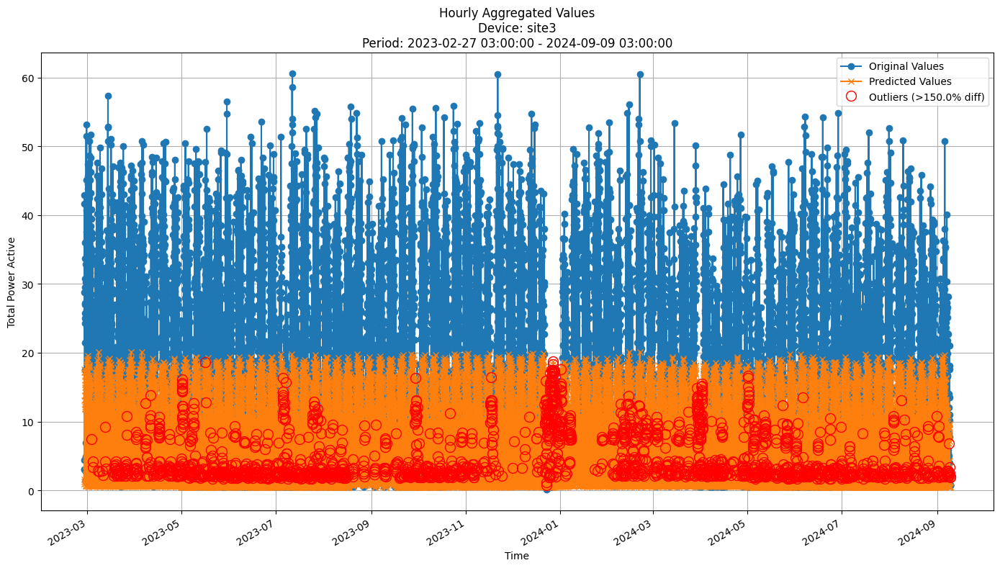


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 11.5125
MAE: 7.9132
MAPE: 104.0673%

Directional Metrics:
Directional Accuracy: 61.0164%
First-Diff Correlation: 0.6379

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


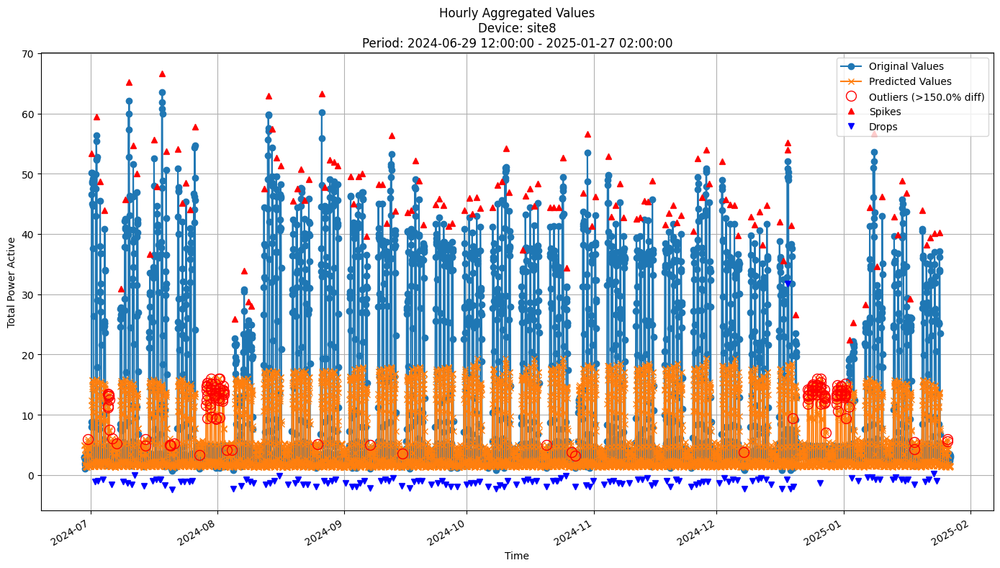


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 10.8568
MAE: 6.3931
MAPE: 55.8929%

Directional Metrics:
Directional Accuracy: 58.6336%
First-Diff Correlation: 0.7154

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1133
  Recall: 0.1259
  F1 Score: 0.1193
Drops:
  Precision: 0.1208
  Recall: 0.1324
  F1 Score: 0.1263

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2400
  Recall: 0.2667
  F1 Score: 0.2526
Drops:
  Precision: 0.2550
  Recall: 0.2794
  F1 Score: 0.2667


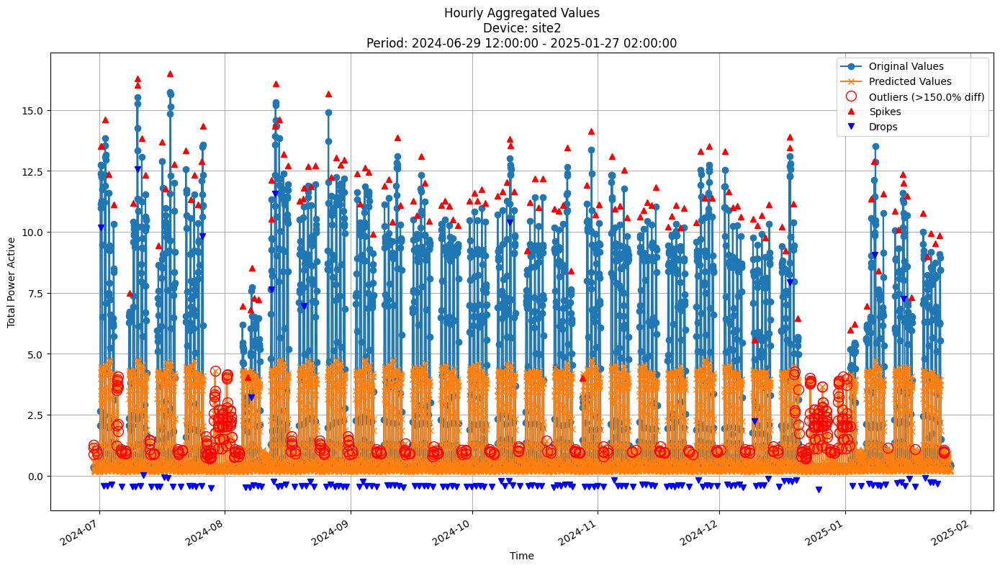


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.6292
MAE: 1.4886
MAPE: 74.7128%

Directional Metrics:
Directional Accuracy: 62.4729%
First-Diff Correlation: 0.7430

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1111
  Recall: 0.1081
  F1 Score: 0.1096
Drops:
  Precision: 0.0699
  Recall: 0.0676
  F1 Score: 0.0687

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2847
  Recall: 0.2770
  F1 Score: 0.2808
Drops:
  Precision: 0.2517
  Recall: 0.2432
  F1 Score: 0.2474


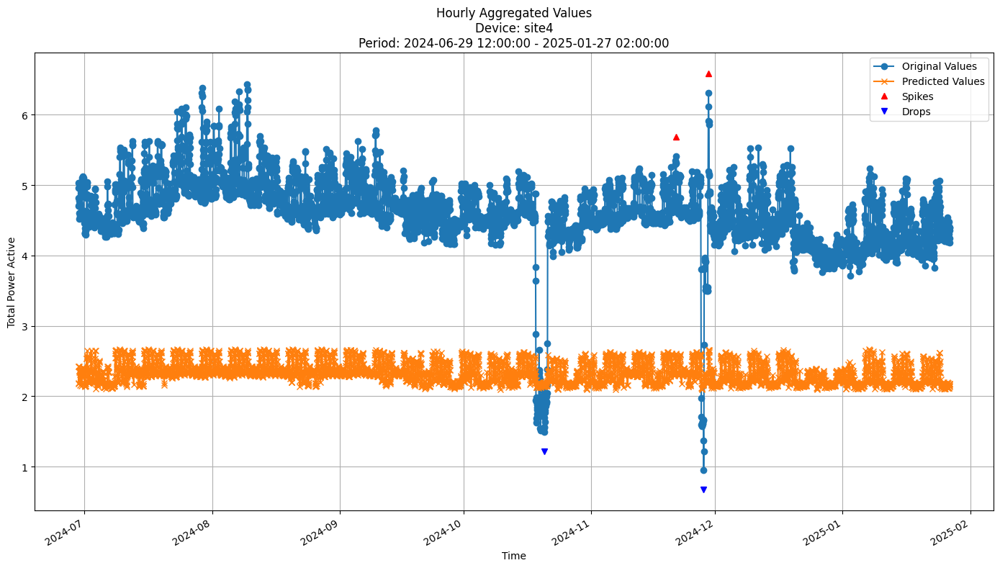


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.3170
MAE: 2.2835
MAPE: 49.2424%

Directional Metrics:
Directional Accuracy: 53.9476%
First-Diff Correlation: 0.2008

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


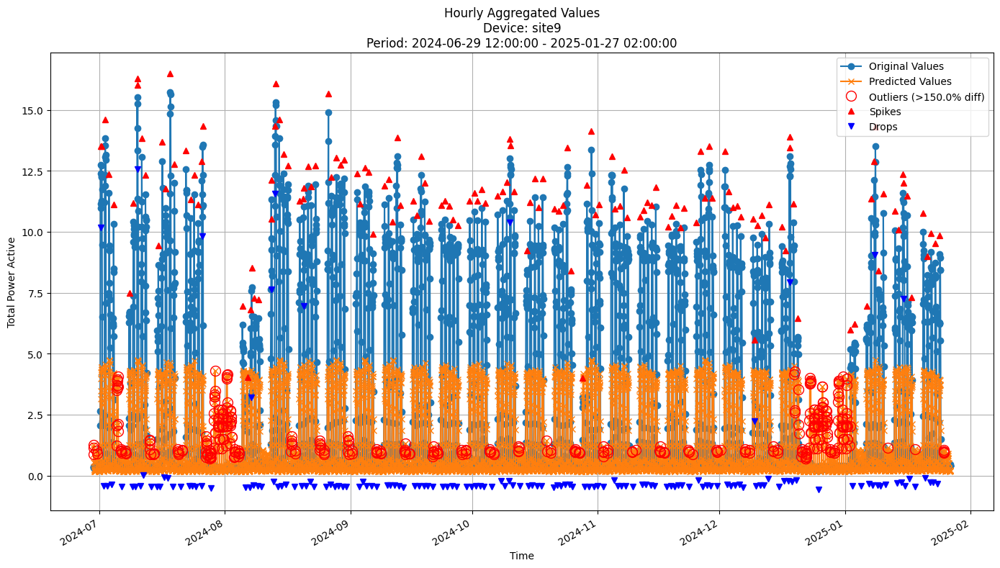


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.6292
MAE: 1.4886
MAPE: 74.7128%

Directional Metrics:
Directional Accuracy: 62.4729%
First-Diff Correlation: 0.7430

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1111
  Recall: 0.1081
  F1 Score: 0.1096
Drops:
  Precision: 0.0699
  Recall: 0.0676
  F1 Score: 0.0687

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2847
  Recall: 0.2770
  F1 Score: 0.2808
Drops:
  Precision: 0.2517
  Recall: 0.2432
  F1 Score: 0.2474


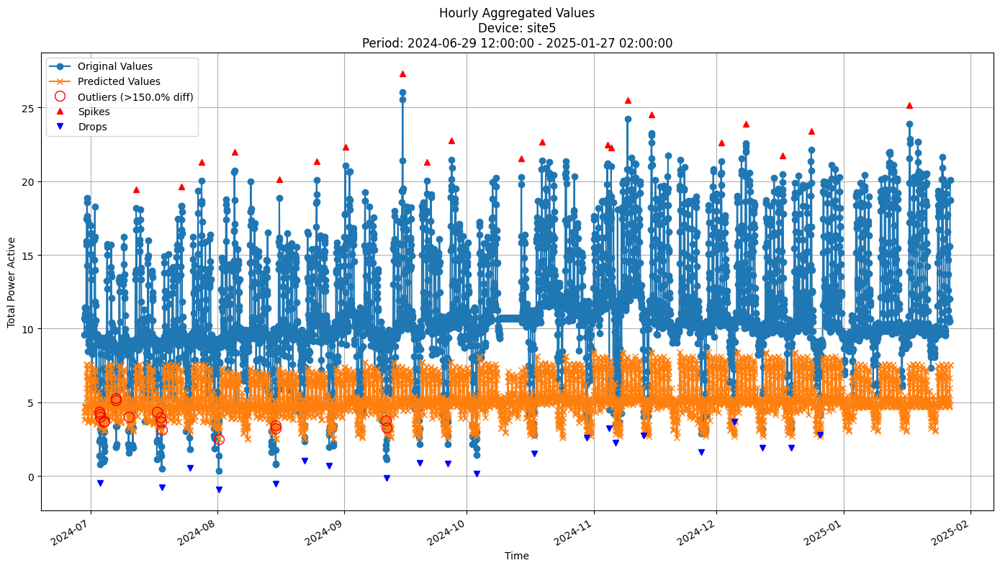


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 6.8068
MAE: 6.2133
MAPE: 52.9526%

Directional Metrics:
Directional Accuracy: 59.4999%
First-Diff Correlation: 0.4764

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0345
  Recall: 0.0476
  F1 Score: 0.0400
Drops:
  Precision: 0.1000
  Recall: 0.1429
  F1 Score: 0.1176

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0345
  Recall: 0.0476
  F1 Score: 0.0400
Drops:
  Precision: 0.2000
  Recall: 0.2857
  F1 Score: 0.2353


In [31]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

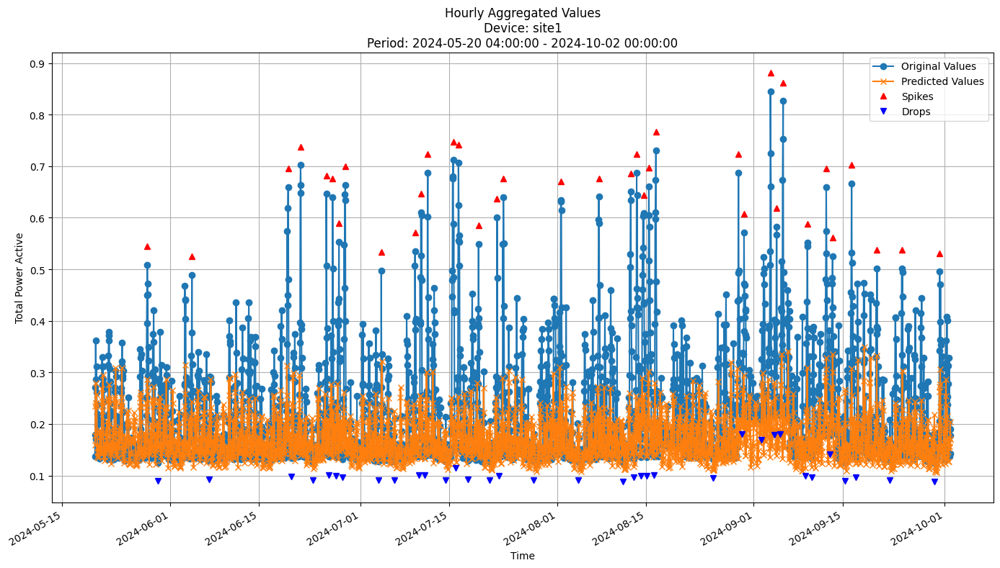


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1044
MAE: 0.0618
MAPE: 22.5294%

Directional Metrics:
Directional Accuracy: 58.1273%
First-Diff Correlation: 0.2658

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


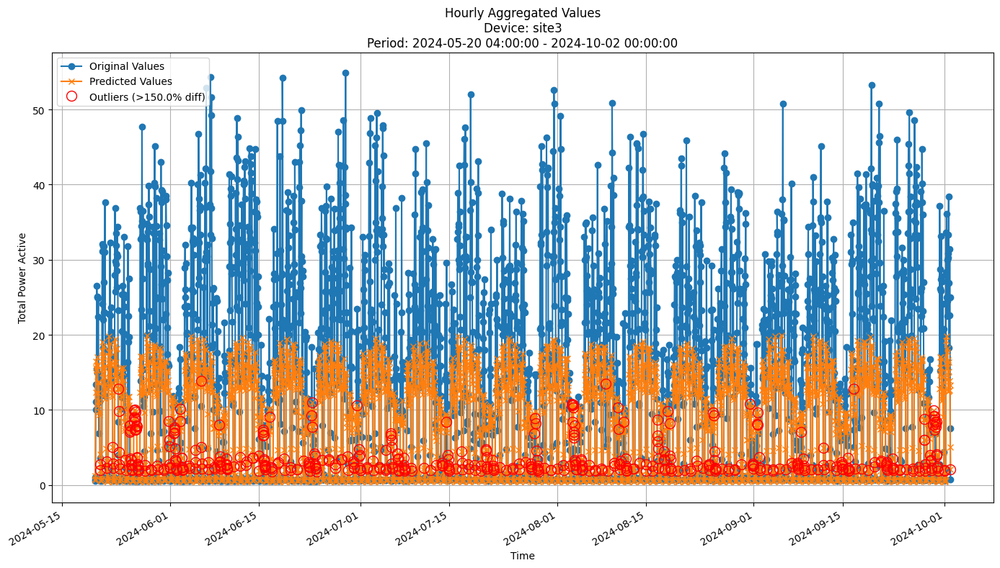


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 10.3254
MAE: 6.8008
MAPE: 79.5718%

Directional Metrics:
Directional Accuracy: 57.3239%
First-Diff Correlation: 0.5959

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


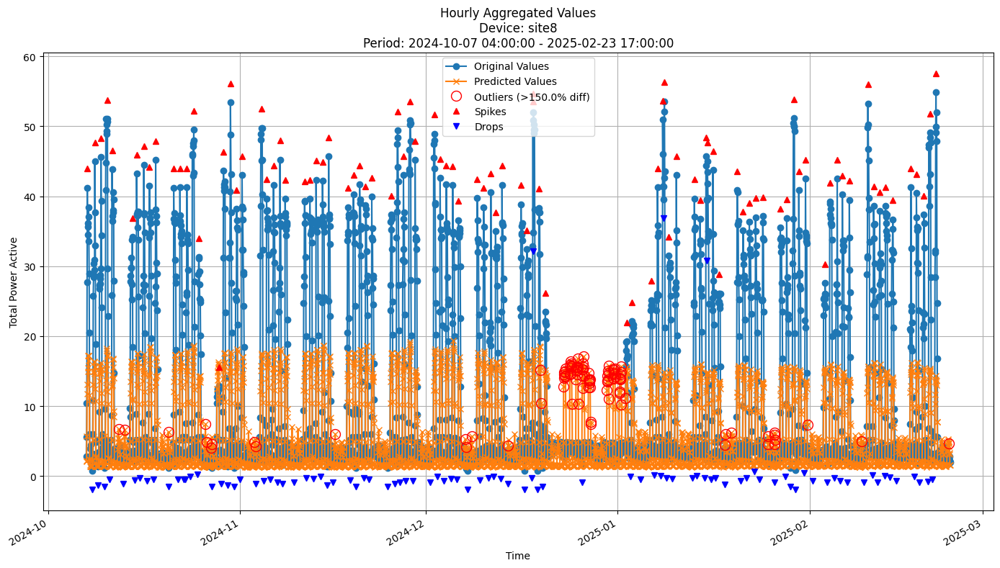


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 10.1448
MAE: 6.1584
MAPE: 56.6993%

Directional Metrics:
Directional Accuracy: 57.1343%
First-Diff Correlation: 0.6844

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1100
  Recall: 0.1158
  F1 Score: 0.1128
Drops:
  Precision: 0.0707
  Recall: 0.0737
  F1 Score: 0.0722

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2400
  Recall: 0.2526
  F1 Score: 0.2462
Drops:
  Precision: 0.1616
  Recall: 0.1684
  F1 Score: 0.1649


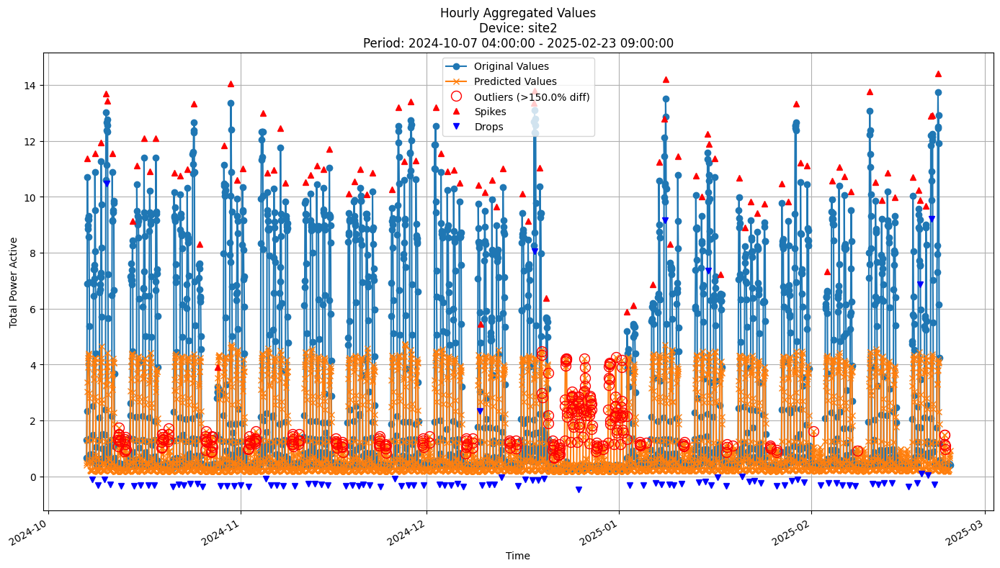


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.4504
MAE: 1.4269
MAPE: 77.2258%

Directional Metrics:
Directional Accuracy: 61.2807%
First-Diff Correlation: 0.7301

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0825
  Recall: 0.0808
  F1 Score: 0.0816
Drops:
  Precision: 0.1042
  Recall: 0.1020
  F1 Score: 0.1031

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2062
  Recall: 0.2020
  F1 Score: 0.2041
Drops:
  Precision: 0.3125
  Recall: 0.3061
  F1 Score: 0.3093


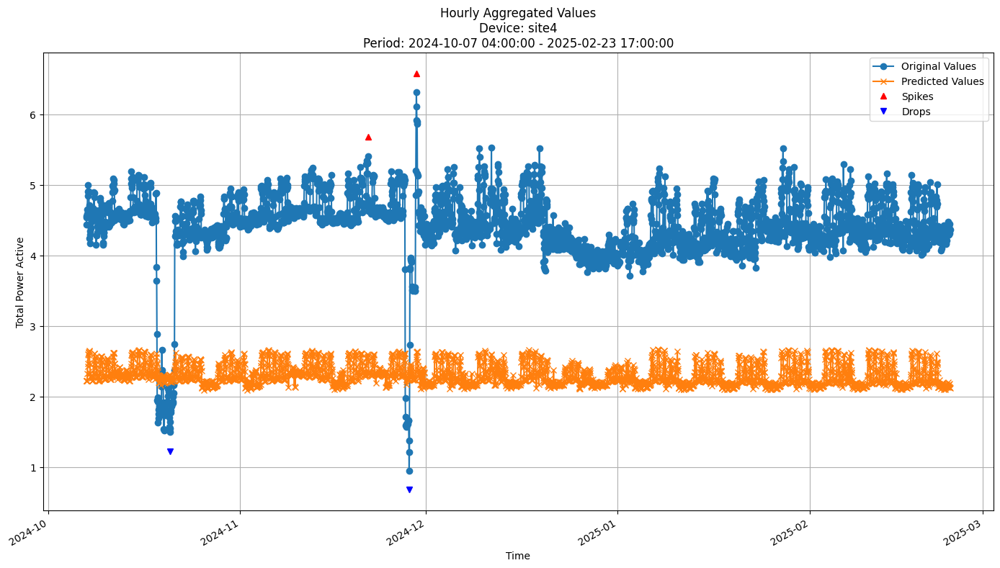


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.1493
MAE: 2.1175
MAPE: 47.7242%

Directional Metrics:
Directional Accuracy: 53.1940%
First-Diff Correlation: 0.1028

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


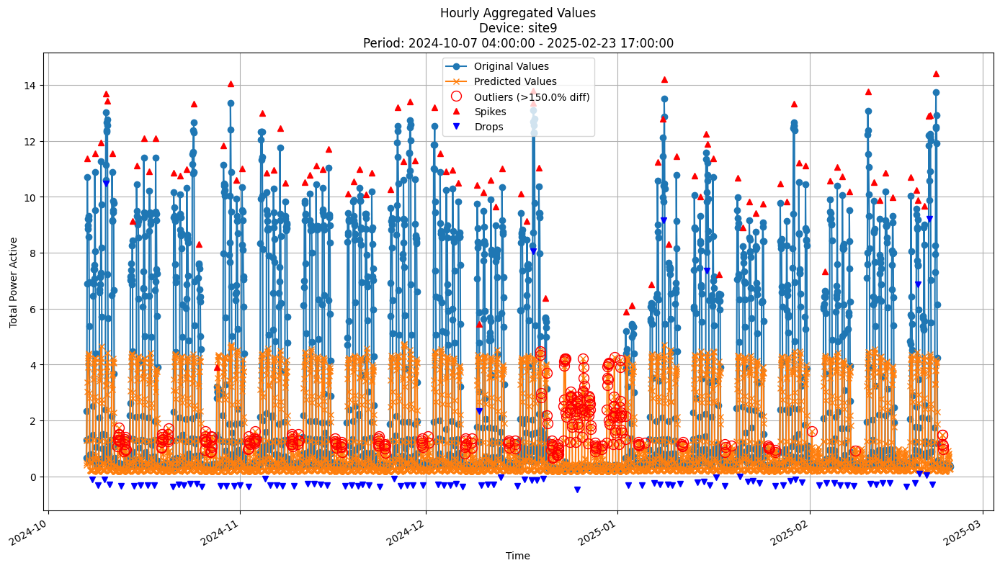


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.4475
MAE: 1.4240
MAPE: 77.1869%

Directional Metrics:
Directional Accuracy: 61.3134%
First-Diff Correlation: 0.7301

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0825
  Recall: 0.0808
  F1 Score: 0.0816
Drops:
  Precision: 0.1042
  Recall: 0.1020
  F1 Score: 0.1031

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2062
  Recall: 0.2020
  F1 Score: 0.2041
Drops:
  Precision: 0.3125
  Recall: 0.3061
  F1 Score: 0.3093


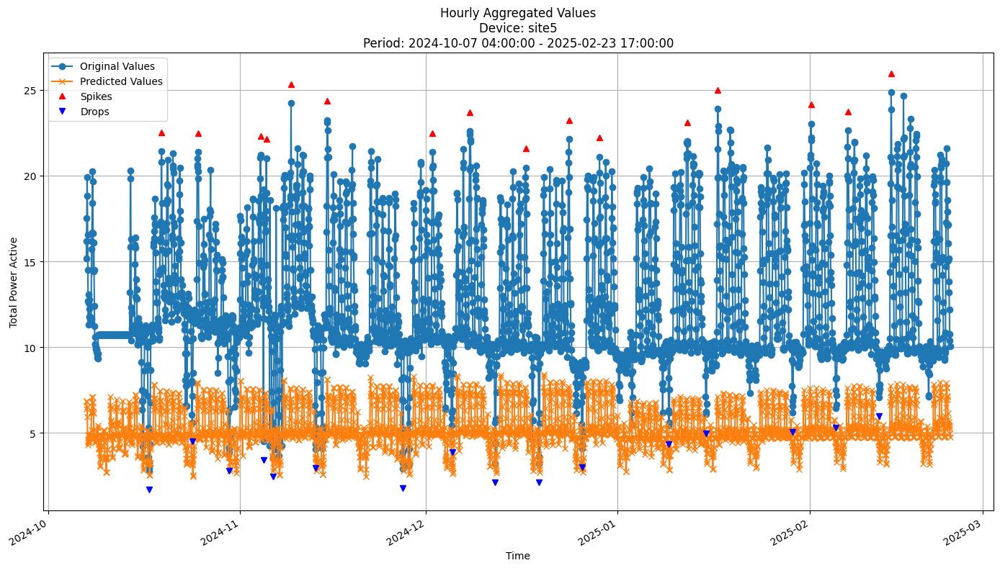


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.8419
MAE: 7.2390
MAPE: 56.0243%

Directional Metrics:
Directional Accuracy: 59.0448%
First-Diff Correlation: 0.3877

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0556
  Recall: 0.0625
  F1 Score: 0.0588
Drops:
  Precision: 0.0526
  Recall: 0.0625
  F1 Score: 0.0571

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0556
  Recall: 0.0625
  F1 Score: 0.0588
Drops:
  Precision: 0.1053
  Recall: 0.1250
  F1 Score: 0.1143


In [32]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

# Test-set Model Evaluation
(`train[-1]` + `valid[-1]`) vs `test`

In [105]:
# Initialize the models beforehand to run this cell
models_classes = [baseline, gbdt, rf, hoef, arf_hf, fodt, arf, incb]
models_params = [baseline_params, gbdt_params, rf_params,
                 hoef_params, arf_hf_params, fodt_params, arf_params, incb_params]

model_test_results = {}
for model, params in zip(models_classes, models_params):
    if model in [gbdt, rf]:
        # Batch learning models
        incremental = False
        update_freq = "14D"
        print(f"\n\n\nModel: {model.__name__} - update_freq: {update_freq}")
    else:
        # Incremental learning models
        incremental = True
        update_freq = "1h"
        print(f"\n\n\nModel: {model.__name__} - update_freq: {update_freq}")

    _, test_preds, \
    _, test_metrics = test_set_seq_fit_predict(
        model_class=model,
        model_params=params,
        train=train, 
        valid=valid,
        test=test,
        incremental=incremental, 
        data_freq=DATA_FREQUENCY,
        forecast_horizon=FORECAST_HORIZON,
        features=FEATURES,
        update_freq=update_freq,
        spike_prominence=SPIKE_PROMINENCE,
        normalize_robust=True,
        predict_train=False,
        verbose=1
    )
    model_test_results[model.__name__] = {
        "test_preds": test_preds,
        "test_metrics": test_metrics
    }




Model: PreviousValueRegressor - update_freq: 1h


Processing devices for test predictions:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2024-10-02 00:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: site1 | Period: 2024-10-02 02:00:00+02:00 - 2025-02-24 23:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0914
	MAE: 0.0635
	MAPE: 13.5864%

Directional Metrics:
	Directional Accuracy: 49.6002%
	First-Diff Correlation: -0.0467

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Da

Processing devices for test predictions:   0%|          | 0/7 [00:00<?, ?it/s]


Retraining model on data from 2023-02-27 03:00:00+01:00 to 2024-10-02 00:00:00+02:00

Time: 3.53 seconds
Predicting for chunk from 2024-10-02 02:00:00+02:00 to 2024-10-16 02:00:00+02:00

-------------------------

Retraining model on data from 2023-02-27 03:00:00+01:00 to 2024-10-16 02:00:00+02:00

Time: 3.57 seconds
Predicting for chunk from 2024-10-16 03:00:00+02:00 to 2024-10-30 02:00:00+01:00

-------------------------

Retraining model on data from 2023-02-27 03:00:00+01:00 to 2024-10-30 02:00:00+01:00

Time: 3.68 seconds
Predicting for chunk from 2024-10-30 03:00:00+01:00 to 2024-11-13 03:00:00+01:00

-------------------------

Retraining model on data from 2023-02-27 03:00:00+01:00 to 2024-11-13 03:00:00+01:00

Time: 3.71 seconds
Predicting for chunk from 2024-11-13 04:00:00+01:00 to 2024-11-27 04:00:00+01:00

-------------------------

Retraining model on data from 2023-02-27 03:00:00+01:00 to 2024-11-27 04:00:00+01:00

Time: 3.78 seconds
Predicting for chunk from 2024-11-27 0

Processing devices for test predictions:   0%|          | 0/7 [00:00<?, ?it/s]

... (7 outputs left out)

Processing devices for test predictions:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2024-10-02 00:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: site1 | Period: 2024-10-02 02:00:00+02:00 - 2025-02-24 23:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1473
	MAE: 0.1107
	MAPE: 23.4105%

Directional Metrics:
	Directional Accuracy: 58.9949%
	First-Diff Correlation: 0.2162

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Dai

Processing devices for test predictions:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2024-10-02 00:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: site1 | Period: 2024-10-02 02:00:00+02:00 - 2025-02-24 23:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3552
	MAE: 0.2960
	MAPE: 49.1232%

Directional Metrics:
	Directional Accuracy: 64.1062%
	First-Diff Correlation: 0.3933

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0667
		Recall: 0.1818
		F1: 0.0976
	Drops:
		Precision: 0.0787
		Recall: 0.2121
		F1: 0.1148

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0889
		Recall: 0.2424
		F1: 0.1301
	Drops:
		Precision: 0.1910
		Recall: 0.5152
		F1: 0.2787
--------------------------------------------------
Dai

In [106]:
for model in models_classes:
    model_test_results[model.__name__]['test_metrics'] = all_time_aggregation_metrics(
        model_test_results[model.__name__]['test_metrics'],
        data_freq=DATA_FREQUENCY,
        verbose=False)

# Model Comparison

In [107]:
AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]
# SPIKES_METRICS = ["spikes_immediate.precision", "spikes_immediate.recall", "spikes_immediate.f1",
#                   "spikes_delayed.precision", "spikes_delayed.recall", "spikes_delayed.f1",
#                   "drops_immediate.precision", "drops_immediate.recall", "drops_immediate.f1",
#                   "drops_delayed.precision", "drops_delayed.recall", "drops_delayed.f1"]
SPIKES_METRICS = ["spikes_immediate.f1", "spikes_delayed.f1",
                  "drops_immediate.f1", "drops_delayed.f1"]

METRICS.extend(SPIKES_METRICS)
PERC_METRICS.extend(SPIKES_METRICS)

## Test results

In [108]:
MODEL_TEST_METRICS = {
    "Baseline": model_test_results[baseline.__name__]["test_metrics"],
    "GBDT": model_test_results[gbdt.__name__]["test_metrics"],
    "RandomForest": model_test_results[rf.__name__]["test_metrics"],
    "HoeffdingTree": model_test_results[hoef.__name__]["test_metrics"],
    "ARF_Hoeffding": model_test_results[arf_hf.__name__]["test_metrics"],
    "FastODT": model_test_results[fodt.__name__]["test_metrics"],
    "ARF_FastODT": model_test_results[arf.__name__]["test_metrics"],
    "IncubationBoost": model_test_results[incb.__name__]["test_metrics"],
}

In [ ]:
def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f}"# ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

def display_aggregated_results(model_metrics, device_ids, agg_level):
    for device_id in device_ids:
        rows = []
        for model, mdict in model_metrics.items():
            if device_id in mdict and agg_level in mdict[device_id]:
                vals = mdict[device_id][agg_level]
                row = [model]
                for m in METRICS:
                    is_perc = (m in PERC_METRICS)
                    row.append(format_metric(vals.get(m, None), is_perc=is_perc))
                rows.append(row)
        df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                         "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)", "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
        print(f"\n\nDevice: {device_id} | Aggregation: {agg_level}")
        display(df)

In [ ]:
device_ids = set()
for m in MODEL_TEST_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

print("\n\n============================Hourly Test Results============================")
display_aggregated_results(MODEL_TEST_METRICS, device_ids, AGG_LEVEL)


Device: site1 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.091,0.064,13.586,49.600,-4.671,0.000,100.000,0.000,100.000
1,GBDT,0.084,0.061,12.826,62.079,42.507,15.152,36.364,12.308,40.000
2,RandomForest,0.090,0.067,14.175,60.822,31.304,13.793,37.931,7.018,24.561
3,HoeffdingTree,0.134,0.098,19.787,55.425,30.466,13.699,35.616,2.778,19.444
4,ARF_Hoeffding,0.110,0.081,16.621,58.424,35.290,11.765,39.216,0.000,16.000
5,FastODT,0.197,0.160,49.742,59.138,42.053,4.598,4.598,4.598,18.391
6,ARF_FastODT,0.147,0.111,23.410,58.995,21.622,0.000,0.000,0.000,0.000
7,IncubationBoost,0.355,0.296,49.123,64.106,39.334,9.756,13.008,11.475,27.869



Device: site2 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,1.458,0.641,27.145,53.857,32.903,0.000,99.200,0.000,100.000
1,GBDT,0.838,0.453,28.894,61.710,78.232,7.752,24.806,9.375,18.750
2,RandomForest,0.888,0.451,24.816,59.694,76.441,1.835,7.339,7.407,16.667
3,HoeffdingTree,1.274,0.633,34.785,49.409,39.921,8.850,38.938,3.571,12.500
4,ARF_Hoeffding,1.037,0.510,27.637,60.111,75.882,7.273,14.545,3.670,14.679
5,FastODT,2.613,1.644,103.543,59.416,64.093,10.769,30.769,3.077,15.385
6,ARF_FastODT,3.025,1.688,48.723,59.347,62.552,11.538,26.923,5.825,13.592
7,IncubationBoost,2.723,1.600,61.869,63.030,79.899,16.216,27.027,7.273,16.364



Device: site3 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,8.845,5.426,53.730,44.232,-6.889,0.000,100.000,0.000,100.000
1,GBDT,6.020,3.961,55.753,61.136,63.605,2.105,14.737,1.835,11.009
2,RandomForest,6.255,4.195,59.131,57.853,61.725,0.000,0.000,0.000,0.000
3,HoeffdingTree,8.414,5.751,103.744,49.772,32.051,0.000,0.000,0.000,2.105
4,ARF_Hoeffding,7.292,4.906,65.646,55.740,46.716,0.000,0.000,0.000,0.000
5,FastODT,9.843,7.886,252.998,56.054,36.284,11.707,25.366,14.545,35.455
6,ARF_FastODT,9.521,7.392,180.404,54.683,35.347,0.000,0.000,0.000,0.000
7,IncubationBoost,12.708,9.102,91.069,60.337,63.466,0.000,0.000,0.000,0.000


... (4 outputs left out)


Device: site8 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,5.878,2.907,35.259,46.565,30.963,0.000,100.000,0.000,100.000
1,GBDT,3.807,2.053,29.304,60.722,71.138,17.241,32.759,3.509,19.298
2,RandomForest,3.901,2.127,30.009,56.905,72.041,6.250,16.667,6.383,19.149
3,HoeffdingTree,5.487,2.805,37.499,51.631,53.260,8.696,23.188,8.824,23.529
4,ARF_Hoeffding,4.961,2.554,29.847,55.864,54.858,3.922,25.490,6.000,22.000
5,FastODT,8.123,5.109,69.603,53.990,54.934,15.556,33.333,9.091,25.000
6,ARF_FastODT,8.112,5.492,80.869,58.848,60.466,4.211,25.263,6.452,15.054
7,IncubationBoost,11.605,7.110,56.508,58.709,75.768,7.619,24.762,5.825,25.243



Device: site9 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,1.467,0.648,27.563,53.990,33.128,0.000,100.000,0.000,100.000
1,GBDT,0.835,0.450,28.605,60.652,78.836,9.302,27.907,7.874,18.898
2,RandomForest,0.891,0.453,24.862,60.097,76.919,5.556,14.815,9.434,16.981
3,HoeffdingTree,1.282,0.641,34.965,49.341,40.460,8.850,40.708,3.604,12.613
4,ARF_Hoeffding,1.059,0.520,30.541,61.138,74.889,10.909,16.364,7.407,18.519
5,FastODT,2.634,1.657,102.040,59.542,64.449,10.769,32.308,3.125,15.625
6,ARF_FastODT,3.021,1.752,64.717,61.277,64.448,9.615,23.077,9.804,17.647
7,IncubationBoost,2.749,1.620,61.814,63.081,80.111,18.182,29.091,7.407,16.667


## Validation results

In [ ]:
MODEL_VALID_METRICS = {
    "Baseline": baseline_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": incb_all_time_valid_metrics,
}


device_ids = set()
for m in MODEL_VALID_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)


print("\n\n============================Hourly Validation Results============================")
display_aggregated_results(MODEL_VALID_METRICS, device_ids, AGG_LEVEL)


Device: site1 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.072 ± 0.009,0.047 ± 0.007,17.668 ± 2.250,44.671 ± 3.509,-9.708 ± 9.598,0.000 ± 0.000,98.931 ± 2.624,0.000 ± 0.000,99.740 ± 0.665
1,GBDT,0.073 ± 0.028,0.049 ± 0.021,18.457 ± 5.867,59.634 ± 2.083,41.936 ± 10.672,20.653 ± 11.051,40.130 ± 13.721,12.899 ± 8.144,26.762 ± 9.484
2,RandomForest,0.076 ± 0.029,0.052 ± 0.022,19.486 ± 6.834,56.839 ± 1.976,32.800 ± 10.256,13.435 ± 9.450,31.584 ± 13.887,8.695 ± 6.331,17.155 ± 7.258
3,HoeffdingTree,0.098 ± 0.045,0.068 ± 0.037,24.368 ± 5.756,54.851 ± 2.835,27.859 ± 9.290,12.167 ± 9.746,34.288 ± 13.205,8.214 ± 5.614,24.924 ± 10.779
4,ARF_Hoeffding,0.082 ± 0.031,0.059 ± 0.025,23.685 ± 8.255,56.048 ± 2.237,33.238 ± 11.994,11.923 ± 9.919,30.870 ± 13.698,5.853 ± 5.016,17.524 ± 8.366
5,FastODT,0.310 ± 0.047,0.287 ± 0.052,146.736 ± 45.103,54.897 ± 2.565,34.495 ± 8.269,12.244 ± 8.552,26.491 ± 16.811,7.075 ± 6.542,14.321 ± 11.287
6,ARF_FastODT,0.105 ± 0.052,0.081 ± 0.039,32.523 ± 10.698,52.913 ± 4.056,19.376 ± 10.255,10.775 ± 7.521,26.727 ± 13.701,5.267 ± 6.571,13.562 ± 12.310
7,IncubationBoost,0.152 ± 0.118,0.113 ± 0.106,30.855 ± 13.469,59.060 ± 2.489,30.989 ± 8.485,15.401 ± 10.131,33.822 ± 14.902,9.390 ± 7.884,18.000 ± 9.954



Device: site2 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,1.403 ± 0.140,0.604 ± 0.095,26.846 ± 3.425,48.975 ± 5.632,29.302 ± 3.311,0.000 ± 0.000,99.513 ± 1.289,0.000 ± 0.000,99.500 ± 1.323
1,GBDT,1.134 ± 0.396,0.566 ± 0.177,36.834 ± 13.539,62.472 ± 4.024,67.491 ± 14.065,11.933 ± 6.402,36.831 ± 10.124,8.146 ± 5.352,21.728 ± 5.677
2,RandomForest,1.035 ± 0.191,0.524 ± 0.096,31.403 ± 15.044,62.373 ± 2.914,71.408 ± 10.538,9.295 ± 4.671,26.063 ± 10.273,8.655 ± 2.779,20.947 ± 6.588
3,HoeffdingTree,1.408 ± 0.199,0.691 ± 0.101,37.534 ± 17.330,50.422 ± 3.584,38.918 ± 19.013,7.075 ± 7.209,36.328 ± 12.614,8.989 ± 3.043,19.790 ± 9.060
4,ARF_Hoeffding,1.134 ± 0.227,0.551 ± 0.110,32.069 ± 21.115,60.604 ± 3.832,68.608 ± 11.943,10.984 ± 10.135,28.798 ± 10.785,5.486 ± 4.676,20.171 ± 8.053
5,FastODT,2.476 ± 0.392,1.506 ± 0.271,102.943 ± 12.543,59.992 ± 3.743,55.869 ± 11.668,10.306 ± 7.064,27.539 ± 11.371,1.502 ± 2.076,14.269 ± 6.849
6,ARF_FastODT,2.495 ± 0.406,1.543 ± 0.279,103.583 ± 12.362,62.437 ± 5.729,60.090 ± 10.362,8.735 ± 3.733,25.374 ± 12.779,4.324 ± 3.198,17.503 ± 10.184
7,IncubationBoost,2.646 ± 0.411,1.543 ± 0.258,84.432 ± 29.198,59.832 ± 2.770,67.815 ± 10.316,10.570 ± 8.740,25.501 ± 11.516,6.346 ± 4.457,23.259 ± 7.084



Device: site3 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,9.039 ± 0.794,5.779 ± 0.712,68.480 ± 10.968,42.504 ± 3.538,-11.459 ± 5.142,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,GBDT,6.772 ± 0.575,4.618 ± 0.476,101.180 ± 39.960,58.394 ± 3.236,54.167 ± 6.928,2.248 ± 4.736,5.136 ± 11.192,2.377 ± 4.919,6.060 ± 11.544
2,RandomForest,6.810 ± 0.423,4.642 ± 0.381,96.441 ± 37.149,56.664 ± 3.150,51.693 ± 6.647,2.392 ± 5.948,5.259 ± 11.885,1.307 ± 3.933,2.909 ± 7.629
3,HoeffdingTree,8.468 ± 0.746,5.723 ± 0.705,120.702 ± 32.845,48.862 ± 2.079,29.382 ± 5.808,4.505 ± 8.466,7.012 ± 10.564,1.346 ± 3.643,4.170 ± 7.671
4,ARF_Hoeffding,7.347 ± 0.799,4.937 ± 0.620,89.767 ± 24.247,54.137 ± 2.320,43.434 ± 7.753,1.765 ± 4.264,3.469 ± 8.338,2.177 ± 4.396,4.995 ± 10.179
5,FastODT,10.418 ± 1.063,8.517 ± 0.864,427.934 ± 117.546,53.850 ± 2.896,32.216 ± 6.995,9.973 ± 7.345,20.696 ± 11.528,15.025 ± 7.727,36.023 ± 10.599
6,ARF_FastODT,8.851 ± 1.088,6.951 ± 0.836,256.760 ± 72.076,55.067 ± 2.494,30.518 ± 7.388,4.072 ± 6.093,14.634 ± 12.486,5.809 ± 6.132,14.246 ± 12.469
7,IncubationBoost,11.315 ± 1.211,7.831 ± 1.063,116.944 ± 48.710,58.931 ± 2.201,59.892 ± 5.482,2.149 ± 4.571,4.704 ± 10.247,3.568 ± 7.520,5.161 ± 10.374


... (4 outputs left out)


Device: site8 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,5.619 ± 0.556,2.688 ± 0.328,32.534 ± 2.452,46.592 ± 3.266,26.976 ± 3.766,0.000 ± 0.000,99.479 ± 1.378,0.000 ± 0.000,99.457 ± 1.438
1,GBDT,4.509 ± 1.540,2.370 ± 0.717,28.497 ± 6.439,59.412 ± 3.282,66.017 ± 12.718,10.787 ± 7.037,31.986 ± 5.836,7.357 ± 5.843,18.687 ± 9.139
2,RandomForest,4.247 ± 0.671,2.285 ± 0.351,28.125 ± 7.124,59.581 ± 3.294,67.845 ± 9.288,5.907 ± 3.694,22.531 ± 6.745,9.143 ± 5.645,23.625 ± 9.781
3,HoeffdingTree,5.729 ± 1.251,3.109 ± 0.717,41.106 ± 18.179,51.627 ± 2.538,44.516 ± 8.396,8.172 ± 2.408,24.634 ± 7.613,5.657 ± 4.330,18.582 ± 6.564
4,ARF_Hoeffding,4.982 ± 0.752,2.598 ± 0.417,31.338 ± 12.660,59.188 ± 3.617,57.083 ± 13.352,8.683 ± 4.233,28.969 ± 7.706,9.624 ± 6.675,22.713 ± 8.321
5,FastODT,7.943 ± 1.256,4.871 ± 0.753,70.610 ± 18.741,51.911 ± 2.027,51.256 ± 7.251,2.956 ± 2.299,18.096 ± 7.214,10.102 ± 8.675,26.758 ± 10.166
6,ARF_FastODT,8.010 ± 1.811,4.860 ± 1.134,59.423 ± 11.561,58.578 ± 3.531,57.736 ± 14.116,8.216 ± 5.785,20.896 ± 7.186,7.217 ± 4.237,20.981 ± 8.236
7,IncubationBoost,10.832 ± 1.578,6.543 ± 0.942,59.647 ± 9.224,57.027 ± 1.854,64.757 ± 10.781,10.015 ± 7.798,23.711 ± 8.253,6.405 ± 4.346,20.092 ± 12.090



Device: site9 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,1.401 ± 0.140,0.603 ± 0.095,26.821 ± 3.431,48.952 ± 5.617,29.302 ± 3.311,0.000 ± 0.000,99.513 ± 1.289,0.000 ± 0.000,99.500 ± 1.323
1,GBDT,1.133 ± 0.396,0.566 ± 0.177,36.848 ± 13.529,62.435 ± 4.033,67.491 ± 14.065,11.876 ± 6.423,37.030 ± 10.058,8.105 ± 5.364,22.028 ± 5.476
2,RandomForest,1.035 ± 0.191,0.523 ± 0.096,31.384 ± 15.054,62.358 ± 2.926,71.408 ± 10.538,9.199 ± 4.640,25.840 ± 10.293,8.586 ± 2.808,20.844 ± 6.739
3,HoeffdingTree,1.407 ± 0.200,0.690 ± 0.100,37.503 ± 17.348,50.421 ± 3.583,38.918 ± 19.013,7.075 ± 7.209,36.151 ± 12.787,8.894 ± 2.933,19.663 ± 9.106
4,ARF_Hoeffding,1.133 ± 0.227,0.550 ± 0.110,32.057 ± 21.120,60.589 ± 3.834,68.608 ± 11.943,10.857 ± 10.065,28.607 ± 10.855,5.451 ± 4.685,20.067 ± 8.145
5,FastODT,2.475 ± 0.392,1.506 ± 0.271,103.395 ± 12.454,59.994 ± 3.744,55.835 ± 11.630,10.108 ± 6.728,27.647 ± 11.471,1.502 ± 2.076,14.217 ± 6.900
6,ARF_FastODT,2.549 ± 0.379,1.540 ± 0.258,94.487 ± 13.889,61.803 ± 6.124,61.573 ± 11.989,10.753 ± 13.056,27.450 ± 12.703,5.452 ± 4.185,14.570 ± 5.708
7,IncubationBoost,2.644 ± 0.411,1.542 ± 0.259,84.443 ± 29.186,59.849 ± 2.792,67.813 ± 10.315,10.410 ± 8.553,25.777 ± 11.641,6.276 ± 4.421,23.120 ± 7.200


### By-period validation results

In [111]:
MODEL_VALID_PERIOD_METRICS = {
    "Baseline": baseline_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, MODEL_VALID_PERIOD_METRICS, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        MODEL_VALID_PERIOD_METRICS: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in MODEL_VALID_PERIOD_METRICS.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (higher is better)

In [112]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)


Device: site1 | Aggregation: hourly | DIR_ACCURACY (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,49.776,59.165,57.079,50.820,58.569,57.526,59.314,61.699,56.743500
Period 2,41.729,59.911,54.993,58.569,56.185,52.906,48.286,60.209,54.098500
Period 3,42.474,61.252,57.377,55.440,57.228,51.416,50.373,56.036,53.949500
Period 4,44.262,59.613,57.377,55.142,59.911,50.522,46.349,53.502,53.334750
Period 5,44.560,65.574,61.252,54.694,61.252,53.204,46.051,59.762,55.793625
Period 6,41.580,59.911,59.165,60.954,58.569,54.694,50.969,57.675,55.439625
Period 7,43.964,61.550,55.887,60.805,57.824,54.545,55.142,57.675,55.924000
Period 8,40.984,59.613,56.483,54.545,54.694,58.420,50.522,58.271,54.191500
Period 9,46.796,57.675,55.142,57.079,55.440,59.016,54.844,60.805,55.849625
Period 10,46.796,56.781,54.993,52.310,53.949,55.142,54.694,55.738,53.800375



Absolute gain/drop in DIR_ACCURACY (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-8.047,0.746,-2.086,7.749,-2.384,-4.620,-11.028,-1.490,-2.645
Period 3 - Period 2,0.745,1.341,2.384,-3.129,1.043,-1.490,2.087,-4.173,-0.149
Period 4 - Period 3,1.788,-1.639,0.000,-0.298,2.683,-0.894,-4.024,-2.534,-0.615
Period 5 - Period 4,0.298,5.961,3.875,-0.448,1.341,2.682,-0.298,6.260,2.459
Period 6 - Period 5,-2.980,-5.663,-2.087,6.260,-2.683,1.490,4.918,-2.087,-0.354
Period 7 - Period 6,2.384,1.639,-3.278,-0.149,-0.745,-0.149,4.173,0.000,0.484
Period 8 - Period 7,-2.980,-1.937,0.596,-6.260,-3.130,3.875,-4.620,0.596,-1.733
Period 9 - Period 8,5.812,-1.938,-1.341,2.534,0.746,0.596,4.322,2.534,1.658
Period 10 - Period 9,0.000,-0.894,-0.149,-4.769,-1.491,-3.874,-0.150,-5.067,-2.049
Period 11 - Period 10,7.600,3.279,5.514,1.639,1.938,0.745,5.068,5.216,3.875



Device: site2 | Aggregation: hourly | DIR_ACCURACY (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,50.075,55.440,59.165,43.219,53.949,53.949,50.522,54.247,52.570750
Period 2,57.079,65.425,65.574,57.377,64.978,61.103,66.617,57.824,61.997125
Period 3,49.329,66.021,65.276,50.522,66.915,59.762,70.343,60.358,61.065750
Period 4,51.416,67.213,66.617,49.329,61.997,64.680,64.680,61.401,60.916625
Period 5,40.835,64.978,62.891,51.416,59.463,65.276,65.872,62.742,59.184125
Period 6,39.195,61.997,60.507,50.224,57.377,58.867,61.401,58.271,55.979875
Period 7,51.118,57.079,59.016,50.373,60.060,55.291,57.675,60.507,56.389875
Period 8,52.752,61.621,59.939,50.917,60.092,61.009,62.385,63.303,59.002250


... (18 outputs left out)


Device: site9 | Aggregation: hourly | DIR_ACCURACY (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,50.075,55.440,59.165,43.219,53.949,53.949,48.286,54.247,52.291250
Period 2,57.079,65.425,65.574,57.377,64.978,61.103,64.978,57.824,61.792250
Period 3,49.329,66.021,65.276,50.522,66.915,59.762,68.703,60.358,60.860750
Period 4,51.416,67.213,66.617,49.329,61.997,64.680,68.107,61.401,61.345000
Period 5,40.835,64.978,62.891,51.416,59.463,65.276,63.636,62.742,58.904625
Period 6,39.195,61.997,60.507,50.224,57.377,58.867,60.954,58.271,55.924000
Period 7,51.118,57.079,59.016,50.373,60.060,55.291,57.824,60.507,56.408500
Period 8,52.568,61.329,59.819,50.906,59.970,61.027,61.934,63.444,58.874625



Absolute gain/drop in DIR_ACCURACY (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,7.004,9.985,6.409,14.158,11.029,7.154,16.692,3.577,9.501
Period 3 - Period 2,-7.750,0.596,-0.298,-6.855,1.937,-1.341,3.725,2.534,-0.931
Period 4 - Period 3,2.087,1.192,1.341,-1.193,-4.918,4.918,-0.596,1.043,0.484
Period 5 - Period 4,-10.581,-2.235,-3.726,2.087,-2.534,0.596,-4.471,1.341,-2.440
Period 6 - Period 5,-1.640,-2.981,-2.384,-1.192,-2.086,-6.409,-2.682,-4.471,-2.981
Period 7 - Period 6,11.923,-4.918,-1.491,0.149,2.683,-3.576,-3.130,2.236,0.484
Period 8 - Period 7,1.450,4.250,0.803,0.533,-0.090,5.736,4.110,2.937,2.466


#### MAPE (lower is better)

In [113]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)


Device: site1 | Aggregation: hourly | MAPE (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,19.048,25.525,25.710,30.862,26.066,162.044,39.229,35.073,45.444625
Period 2,18.136,19.220,18.877,23.278,24.067,220.077,35.007,33.084,48.968250
Period 3,19.114,15.708,16.861,24.367,21.111,206.143,23.127,28.556,44.373375
Period 4,18.635,14.785,15.188,19.565,17.786,192.375,21.966,24.068,40.546000
Period 5,17.999,13.419,13.672,17.170,15.588,175.186,25.776,19.430,37.280000
Period 6,17.382,17.831,16.985,18.650,17.233,168.130,22.298,20.204,37.339125
Period 7,17.974,13.787,14.798,18.313,15.550,146.175,22.627,22.886,34.013750
Period 8,17.110,13.207,14.360,19.774,14.797,112.681,21.561,26.207,29.962125
Period 9,13.348,19.023,19.330,24.131,19.886,49.237,23.650,47.238,26.980375
Period 10,18.069,41.098,46.843,43.762,54.300,90.553,69.000,70.214,54.229875



Absolute gain/drop in MAPE (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.912,-6.305,-6.833,-7.584,-1.999,58.033,-4.222,-1.989,3.524
Period 3 - Period 2,0.978,-3.512,-2.016,1.089,-2.956,-13.934,-11.880,-4.528,-4.595
Period 4 - Period 3,-0.479,-0.923,-1.673,-4.802,-3.325,-13.768,-1.161,-4.488,-3.827
Period 5 - Period 4,-0.636,-1.366,-1.516,-2.395,-2.198,-17.189,3.810,-4.638,-3.266
Period 6 - Period 5,-0.617,4.412,3.313,1.480,1.645,-7.056,-3.478,0.774,0.059
Period 7 - Period 6,0.592,-4.044,-2.187,-0.337,-1.683,-21.955,0.329,2.682,-3.325
Period 8 - Period 7,-0.864,-0.580,-0.438,1.461,-0.753,-33.494,-1.066,3.321,-4.052
Period 9 - Period 8,-3.762,5.816,4.970,4.357,5.089,-63.444,2.089,21.031,-2.982
Period 10 - Period 9,4.721,22.075,27.513,19.631,34.414,41.316,45.350,22.976,27.250
Period 11 - Period 10,-8.320,-25.412,-30.617,-15.320,-32.886,-48.366,-36.821,-9.576,-25.915



Device: site2 | Aggregation: hourly | MAPE (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,22.607,67.523,68.596,79.156,86.079,103.822,95.045,145.126,83.494250
Period 2,27.691,33.842,25.550,30.316,24.601,102.408,123.514,76.327,55.531125
Period 3,30.268,26.306,20.394,24.317,17.889,89.642,89.345,68.471,45.829000
Period 4,30.176,27.094,23.024,26.824,20.597,98.257,115.442,66.544,50.994750
Period 5,31.704,26.671,22.341,27.174,20.322,95.114,110.881,62.513,49.590000
Period 6,23.771,46.412,38.710,36.576,35.300,101.196,107.935,117.026,63.365750
Period 7,22.532,40.179,28.970,48.445,30.125,134.214,101.103,85.852,61.427500
Period 8,26.017,26.648,23.638,27.463,21.636,98.890,85.399,53.596,45.410875


... (18 outputs left out)


Device: site9 | Aggregation: hourly | MAPE (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,22.607,67.523,68.596,79.156,86.079,103.822,98.808,145.126,83.964625
Period 2,27.691,33.842,25.550,30.316,24.601,102.408,96.775,76.327,52.188750
Period 3,30.268,26.306,20.394,24.317,17.889,89.642,103.703,68.471,47.623750
Period 4,30.176,27.094,23.024,26.824,20.597,98.257,118.169,66.544,51.335625
Period 5,31.704,26.671,22.341,27.174,20.322,95.114,100.128,62.513,48.245875
Period 6,23.771,46.412,38.710,36.576,35.300,101.196,88.709,117.026,60.962500
Period 7,22.532,40.179,28.970,48.445,30.125,134.214,78.871,85.852,58.648500
Period 8,25.817,26.754,23.484,27.217,21.542,102.506,70.728,53.685,43.966625



Absolute gain/drop in MAPE (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,5.084,-33.681,-43.046,-48.840,-61.478,-1.414,-2.033,-68.799,-31.776
Period 3 - Period 2,2.577,-7.536,-5.156,-5.999,-6.712,-12.766,6.928,-7.856,-4.565
Period 4 - Period 3,-0.092,0.788,2.630,2.507,2.708,8.615,14.466,-1.927,3.712
Period 5 - Period 4,1.528,-0.423,-0.683,0.350,-0.275,-3.143,-18.041,-4.031,-3.090
Period 6 - Period 5,-7.933,19.741,16.369,9.402,14.978,6.082,-11.419,54.513,12.717
Period 7 - Period 6,-1.239,-6.233,-9.740,11.869,-5.175,33.018,-9.838,-31.174,-2.314
Period 8 - Period 7,3.285,-13.425,-5.486,-21.228,-8.583,-31.708,-8.143,-32.167,-14.682


#### RMSE (lower is better)

In [114]:
# RMSE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)


Device: site1 | Aggregation: hourly | RMSE per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.078,0.077,0.082,0.111,0.086,0.354,0.114,0.169,0.133875
Period 2,0.060,0.048,0.049,0.062,0.055,0.394,0.069,0.071,0.101000
Period 3,0.065,0.043,0.047,0.071,0.051,0.368,0.057,0.064,0.095750
Period 4,0.067,0.056,0.055,0.065,0.059,0.348,0.064,0.076,0.098750
Period 5,0.062,0.050,0.049,0.063,0.053,0.327,0.059,0.061,0.090500
Period 6,0.060,0.056,0.054,0.064,0.057,0.322,0.061,0.073,0.093375
Period 7,0.070,0.054,0.060,0.066,0.059,0.303,0.071,0.083,0.095750
Period 8,0.073,0.060,0.064,0.084,0.069,0.278,0.086,0.112,0.103250
Period 9,0.077,0.113,0.112,0.143,0.108,0.191,0.132,0.282,0.144750
Period 10,0.082,0.103,0.107,0.144,0.119,0.208,0.182,0.334,0.159875



Absolute gain/drop in RMSE:


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.018,-0.029,-0.033,-0.049,-0.031,0.040,-0.045,-0.098,-0.033
Period 3 - Period 2,0.005,-0.005,-0.002,0.009,-0.004,-0.026,-0.012,-0.007,-0.005
Period 4 - Period 3,0.002,0.013,0.008,-0.006,0.008,-0.020,0.007,0.012,0.003
Period 5 - Period 4,-0.005,-0.006,-0.006,-0.002,-0.006,-0.021,-0.005,-0.015,-0.008
Period 6 - Period 5,-0.002,0.006,0.005,0.001,0.004,-0.005,0.002,0.012,0.003
Period 7 - Period 6,0.010,-0.002,0.006,0.002,0.002,-0.019,0.010,0.010,0.002
Period 8 - Period 7,0.003,0.006,0.004,0.018,0.010,-0.025,0.015,0.029,0.008
Period 9 - Period 8,0.004,0.053,0.048,0.059,0.039,-0.087,0.046,0.170,0.041
Period 10 - Period 9,0.005,-0.010,-0.005,0.001,0.011,0.017,0.050,0.052,0.015
Period 11 - Period 10,0.004,0.060,0.064,0.118,0.065,0.083,0.101,0.213,0.089



Device: site2 | Aggregation: hourly | RMSE per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,1.247,1.548,1.357,1.748,1.471,2.454,2.529,2.597,1.868875
Period 2,1.604,1.993,1.309,1.564,1.518,3.384,3.360,3.517,2.281125
Period 3,1.521,0.757,0.788,1.043,0.803,2.591,2.659,2.868,1.628750
Period 4,1.440,0.965,1.042,1.260,1.040,2.374,2.347,2.671,1.642375
Period 5,1.516,0.780,0.858,1.522,0.997,2.414,2.344,2.725,1.644500
Period 6,1.240,0.964,1.000,1.343,1.099,1.929,1.798,2.196,1.446125
Period 7,1.212,1.042,0.901,1.443,1.029,2.204,2.388,2.090,1.538625
Period 8,1.441,1.020,1.029,1.343,1.113,2.459,2.538,2.506,1.681125


... (18 outputs left out)


Device: site9 | Aggregation: hourly | RMSE per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,1.247,1.548,1.357,1.748,1.471,2.454,2.503,2.597,1.865625
Period 2,1.604,1.993,1.309,1.564,1.518,3.384,3.407,3.517,2.287000
Period 3,1.521,0.757,0.788,1.043,0.803,2.591,2.544,2.868,1.614375
Period 4,1.440,0.965,1.042,1.260,1.040,2.374,2.334,2.671,1.640750
Period 5,1.516,0.780,0.858,1.522,0.997,2.414,2.456,2.725,1.658500
Period 6,1.240,0.964,1.000,1.343,1.099,1.929,2.072,2.196,1.480375
Period 7,1.212,1.042,0.901,1.443,1.029,2.204,2.283,2.090,1.525500
Period 8,1.432,1.014,1.022,1.335,1.106,2.451,2.794,2.491,1.705625



Absolute gain/drop in RMSE:


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,0.357,0.445,-0.048,-0.184,0.047,0.930,0.904,0.920,0.421
Period 3 - Period 2,-0.083,-1.236,-0.521,-0.521,-0.715,-0.793,-0.863,-0.649,-0.673
Period 4 - Period 3,-0.081,0.208,0.254,0.217,0.237,-0.217,-0.210,-0.197,0.026
Period 5 - Period 4,0.076,-0.185,-0.184,0.262,-0.043,0.040,0.122,0.054,0.018
Period 6 - Period 5,-0.276,0.184,0.142,-0.179,0.102,-0.485,-0.384,-0.529,-0.178
Period 7 - Period 6,-0.028,0.078,-0.099,0.100,-0.070,0.275,0.211,-0.106,0.045
Period 8 - Period 7,0.220,-0.028,0.121,-0.108,0.077,0.247,0.511,0.401,0.180
